# Rossmann Store Sales Forecasting — Part 2
**NextHikes IT Solutions | Machine Learning Engineering Project**

This notebook continues *Attempt 1* (Sections 1 to 8.1). It does not redo any earlier work: it reloads the saved state (cleaned data, feature tables, registers, figure numbering, MLflow store, DVC history) and carries on from Section 8.2.

| Part | Contents | Deadline |
|---|---|---|
| **Step 0** | Interim package: the 3-to-5-slide deck content and the evidence checklist (GitHub, DVC, MLflow) | **5 Nov 2026** |
| **Section 8** (8.2 to 8.6) | Supervised framing for sequences, chain-level and store-level LSTMs, fair comparison, wrap-up | 15 Nov 2026 |
| **Section 9** | Customer forecasts, explainability, prediction intervals | 15 Nov 2026 |
| **Section 10** | Freeze, the single holdout scoring, final refit, timestamped models, MLflow inference, submission file | 15 Nov 2026 |
| **Section 11** | Inference module, Streamlit app, tests, deployment | 15 Nov 2026 |
| **Section 12** | Repository, evidence pack, blog content, final audit | 15 Nov 2026 |

**How to run.** Put this notebook in the project root (next to `src/`, or in `notebooks/`) and run it top to bottom after Attempt 1. Slow cells are marked **(slow)** with the time they took on the reference run (a 2-core CPU machine without a GPU). On Google Colab with a GPU the LSTM cells are several times faster.

**Rules carried over from Part 1.** The final holdout (20 Jun to 31 Jul 2015) stays locked until Section 10.2 and is scored exactly once; the evaluation-access log must be empty until then. The seasonal check is a diagnostic, never used for tuning. Every reusable function lives in `src/` and is imported here and by the app.

## R. Resume the Project

The cell below reconnects to everything Part 1 saved:

- the project root, `src/` modules, logger, palette and plotting style;
- the three registers (`outputs/decision_register.csv`, `outputs/limitations.csv`, `outputs/evaluation_log.csv`) and the helper functions that add to them;
- **figure and table numbering**: the numbers already used in Part 1 are read back from `outputs/figure_index.csv` and `outputs/table_index.csv`, so new figures continue the sequence (for example Figure 8.6 after 8.5) instead of overwriting Part 1 files;
- the Git and DVC helpers (`sh`, `save_data_version`);
- the cleaned data, the split design and the locked final configuration from Section 7.

In [1]:
import gc
import json
import os
import subprocess
import sys
import time
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from IPython.display import Markdown, display

NOTEBOOK_START = time.time()

# ---- project root (same rule as Part 1, cell 2.2)
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=UserWarning)

from src import config, style, data, validation
from src import features as F
from src import models as M
from src import baselines as B
from src import timeseries as TS
from src.logger import get_logger
from src.style import PALETTE, FORECAST_COLORS, CATEGORICAL
from src.utils import set_seed

logger = get_logger("rossmann")
set_seed(config.SEED)
style.apply_style()
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 200)
OUTPUT_DIR = config.OUTPUTS_DIR

# ---- registers (Section 1.10), reloaded from disk
decision_register = pd.read_csv(OUTPUT_DIR / "decision_register.csv")
limitations = pd.read_csv(OUTPUT_DIR / "limitations.csv")
evaluation_log = pd.read_csv(OUTPUT_DIR / "evaluation_log.csv")


def log_decision(section, decision, reason, status="Confirmed"):
    """Append a decision to the Decision Register and return its id."""
    global decision_register
    new_id = f"D{len(decision_register) + 1:02d}"
    decision_register.loc[len(decision_register)] = [new_id, section, decision, reason, status]
    return new_id


def log_limitation(section, limitation, effect_on_conclusions):
    """Append a limitation to the Limitations List and return its id."""
    global limitations
    new_id = f"L{len(limitations) + 1:02d}"
    limitations.loc[len(limitations)] = [new_id, section, limitation, effect_on_conclusions]
    return new_id


def log_evaluation(section, dataset, model, purpose, result_summary):
    """Record every scoring of the FINAL holdout (and other key evaluations)."""
    global evaluation_log
    evaluation_log.loc[len(evaluation_log)] = [datetime.now().strftime("%Y-%m-%d %H:%M:%S"), section, dataset, model,
                                               purpose, result_summary]


def save_registers():
    """Save all three registers to outputs/ so the report and app can quote them."""
    decision_register.to_csv(OUTPUT_DIR / "decision_register.csv", index=False)
    evaluation_log.to_csv(OUTPUT_DIR / "evaluation_log.csv", index=False)
    limitations.to_csv(OUTPUT_DIR / "limitations.csv", index=False)


# ---- continue the figure and table numbering of Part 1
def restore_numbering():
    restored = {}
    for kind, file, target in [("Figure", "figure_index.csv", style.figure_index), ("Table", "table_index.csv", style.table_index)]:
        path = OUTPUT_DIR / file
        if not path.exists():
            continue
        idx = pd.read_csv(path, keep_default_na=False)
        for r in idx.itertuples(index=False):
            section, n = r.label.split(" ", 1)[1].rsplit(".", 1)
            key = (kind, section, r.title)
            style._numbers[key] = int(n)
            style._per_section[(kind, section)] = max(style._per_section.get((kind, section), 0), int(n))
            entry = {"label": r.label, "title": r.title, "file": r.file}
            if entry not in target:
                target.append(entry)
        restored[kind] = len(idx)
    # Section 8.1 of Part 1 did not call style.save_index(), so its figures and tables are recovered from the saved files
    for kind, folder, pattern, target in [("Figure", config.FIGURES_DIR, "fig_*.png", style.figure_index),
                                          ("Table", OUTPUT_DIR / "tables", "table_*.csv", style.table_index)]:
        for f in sorted(folder.glob(pattern)):
            _, section, n, *slug = f.stem.split("_")
            n = int(n)
            if any(e["file"] == f.name for e in target):
                continue
            title = " ".join(slug).capitalize()
            style._numbers[(kind, section, title)] = n
            style._per_section[(kind, section)] = max(style._per_section.get((kind, section), 0), n)
            target.append({"label": f"{kind} {section}.{n}", "title": title, "file": f.name})
            restored[kind] = restored.get(kind, 0) + 1
    # its completion-check table was displayed but not saved: it was Table 8.8, so new Section 8 tables start at 8.9
    style._per_section[("Table", "8")] = max(style._per_section.get(("Table", "8"), 0), 8)
    return restored


restored = restore_numbering()


# ---- Git and DVC helpers (Section 2.7)
def sh(cmd, check=True, quiet=False):
    """Run a shell command from the project root, print its output and optionally fail loudly."""
    result = subprocess.run(cmd, shell=True, cwd=ROOT, capture_output=True, text=True)
    output = (result.stdout + result.stderr).strip()
    if output and not quiet:
        print(output)
    if check and result.returncode != 0:
        raise RuntimeError(f"Command failed: {cmd}")
    return result


# models/ is versioned with DVC (Section 10.3), never committed to Git
gitignore = ROOT / ".gitignore"
if "/models/" not in gitignore.read_text():
    gitignore.write_text(gitignore.read_text().rstrip("\n") + "\n# model files are versioned with DVC\n/models/\n", encoding="utf-8")


def save_data_version(tag, message, target="data"):
    """Record the current state of a folder as a new DVC version, commit the pointer and tag it."""
    sh(f"dvc add {target}", quiet=True)
    sh(f"git add {target}.dvc .gitignore")
    sh(f'git commit -m "{message}"', check=False, quiet=True)
    if sh(f"git tag -l {tag}", quiet=True).stdout.strip():
        print(f"Tag {tag} already exists and is not moved (a re-run must not rewrite the version history).")
    else:
        sh(f"git tag {tag}", quiet=True)
    sh("dvc push", quiet=True)
    logger.info(f"Data version saved: {tag}")


# ---- data, splits and the locked Section 7 configuration
train_clean = data.load_interim("train_clean")
test_clean = data.load_interim("test_clean")
store_clean = data.load_interim("store_clean")
splits = pd.concat([
    validation.make_splits(train_clean["Date"].min(), train_clean["Date"].max()),
    validation.seasonal_check_split(train_clean["Date"].min(), test_clean["Date"].min(), test_clean["Date"].nunique()),
], ignore_index=True)
SPLIT = splits.set_index("split")
dev_end = SPLIT.loc["holdout", "train_end"]                   # 19 Jun 2015: the last day any model may learn from before Section 10
LAST_DAY = train_clean["Date"].max()                          # 31 Jul 2015: the last labelled day
F.register_all()
ROLLING = ["rolling_1", "rolling_2", "rolling_3"]
ALL_WINDOWS = ROLLING + ["seasonal_check"]
WINDOW_LABELS = {"rolling_1": "Rolling 1", "rolling_2": "Rolling 2", "rolling_3": "Rolling 3", "seasonal_check": "Seasonal check"}
DAYS = {1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat", 7: "Sun"}
test_stores = set(test_clean["Store"].unique())

NO_LY_FEATURES = [f for f in F.ALL_FEATURES if not f.startswith("ly_")]          # 59 features (Decision D53)
FINALIST = "hist_gradient_boosting"
FINAL_PARAMS = {"max_iter": 300, "learning_rate": 0.05, "max_leaf_nodes": 127, "min_samples_leaf": 20, "l2_regularization": 0.0}
CANDIDATE_ROWS = 400_000                                                         # Section 7 candidate (registered version 2)
BEST_BASELINE = "promo_aware_average"
TARGET_ROLLING_RMSPE = 0.13

import mlflow
mlflow.set_tracking_uri(config.MLFLOW_TRACKING_URI)
mlflow.set_experiment(config.MLFLOW_EXPERIMENT)
client = mlflow.tracking.MlflowClient()

# the locked configuration must agree with what Section 7 registered (version 2 of rossmann-gradient-boosting)
v2 = client.get_model_version("rossmann-gradient-boosting", "2")
v2_params = client.get_run(v2.run_id).data.params
registered_params = {k[2:]: v for k, v in v2_params.items() if k.startswith("p_")}

state = pd.DataFrame([
    ("Project root", str(ROOT)),
    ("Figures / tables already numbered in Part 1", f"{restored.get('Figure', 0)} / {restored.get('Table', 0)}"),
    ("Decision Register / Limitations List entries", f"{len(decision_register)} / {len(limitations)}"),
    ("Evaluation-access log entries (must be 0)", len(evaluation_log)),
    ("Development period (models may learn from)", f"{train_clean['Date'].min().date()} to {dev_end.date()}"),
    ("Final holdout (locked)", f"{SPLIT.loc['holdout', 'valid_start'].date()} to {SPLIT.loc['holdout', 'valid_end'].date()}"),
    ("Finalist settings agree with MLflow version 2", all(str(FINAL_PARAMS[k]) == registered_params.get(k) for k in FINAL_PARAMS)),
    ("Features of MLflow version 2 (the Section 7 candidate)", f"{v2_params.get('n_features')} ({client.get_run(v2.run_id).data.tags.get('version_note')})"),
    ("MLflow runs in the main experiment", len(client.search_runs([mlflow.get_experiment_by_name(config.MLFLOW_EXPERIMENT).experiment_id], max_results=5000))),
], columns=["item", "value"]).set_index("item")
display(state)
assert len(evaluation_log) == 0, "The holdout has already been scored: Part 2 must start with an empty evaluation-access log"
assert bool(state.loc["Finalist settings agree with MLflow version 2", "value"]), "Locked settings differ from the registered candidate"
logger.info("Part 2 resumed from the saved state of Section 8.1.")

I0000 00:00:1793703153.891303    6512 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793703153.892707    6512 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793703154.002875    6512 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793703155.151445    6512 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793703155.152008    6512 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/11/03 10:52:38 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /usr/local/lib/python3.13/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


,value
item,
Project root,/home/claude/rossmann
Figures / tables already numbered in Part 1,31 / 113
Decision Register / Limitations List entries,59 / 37
Evaluation-access log entries (must be 0),0
Development period (models may learn from),2013-01-01 to 2015-06-19
Final holdout (locked),2015-06-20 to 2015-07-31
Finalist settings agree with MLflow version 2,True
Features of MLflow version 2 (the Section 7 candidate),"61 (61 features, 400,000 training rows, drop_same_year=False)"
MLflow runs in the main experiment,48


2026-11-03 10:52:39 | INFO     | rossmann | Part 2 resumed from the saved state of Section 8.1.


## R.2 Resolving an Inconsistency in Section 7: 59 or 61 Features?

**What the audit found.** Section 7 fixed a rule *before* the ablation: drop the two same-year-earlier features (`ly_sales_same_dow`, `ly_week_mean`) only if removing them worsens the average rolling RMSPE by **at most 0.5%**. The ablation measured **+0.76%** (0.1297 to 0.1307 at 150,000 rows), so by its own rule the code kept all 61 features: Table 7.20 says "61 (all features kept)" and registered version 2 has 61 features. But the Decision Register entry (D53) was typed as "dropped, leaving 59 features", and the Part 2 brief repeated that. The record and the evidence disagree.

**Resolution (before any holdout access).** The rule is applied again at the size the final model will actually use more closely: 400,000 training rows (the Section 7 candidate size), in every rolling window and the seasonal check. The rule itself is not changed. Whatever it says is the final feature set, and D53 is corrected in the register. These eight fits are also the reference gradient-boosting forecasts used throughout Section 8, so nothing is fitted twice. **(slow: about 7 minutes)**

In [2]:
dataset = pd.read_pickle(config.DATA_PROCESSED / "features_dev.pkl.gz")
FEATURE_SETS = {"61 features (with same-year-earlier)": F.ALL_FEATURES, "59 features (without)": NO_LY_FEATURES}
ref_pred, ref_fit_seconds, ref_models, fs_rows = {}, {}, {}, []
t0 = time.time()
for name in ALL_WINDOWS:
    train, valid = M.window_data(dataset, splits, name, train_sample=CANDIDATE_ROWS)
    for set_name, feats in FEATURE_SETS.items():
        res, pred, model = M.fit_and_score(FINALIST, FINAL_PARAMS, feats, train, valid, test_stores, keep_model=True)
        ref_pred[(set_name, name)] = pred
        ref_fit_seconds[(set_name, name)] = res["fit_seconds"]
        if name == "rolling_3":
            ref_models[set_name] = model
        fs_rows.append({"window": name, "features": set_name, "rmspe": res["rmspe"], "rmspe_test_stores": res["rmspe_test_stores"], "mae": res["mae"]})
    del train, valid
    gc.collect()
print(f"Eight fits in {time.time() - t0:.0f} s")
fs = pd.DataFrame(fs_rows).pivot(index="features", columns="window", values="rmspe")[ALL_WINDOWS]
fs["rolling average"] = fs[ROLLING].mean(axis=1)
with_ly, without_ly = fs.loc["61 features (with same-year-earlier)", "rolling average"], fs.loc["59 features (without)", "rolling average"]
ly_change_400k = 100 * (without_ly / with_ly - 1)
fs["change of the 59-feature set (%)"] = np.nan
fs.loc["59 features (without)", "change of the 59-feature set (%)"] = ly_change_400k
style.show_table(fs.round(4), "R", "Same-year-earlier features at 400,000 training rows (RMSPE)")

DROP_LY = bool(ly_change_400k <= 0.5)                       # the Section 7 rule, unchanged
FINAL_SET = "59 features (without)" if DROP_LY else "61 features (with same-year-earlier)"
FINAL_FEATURES = FEATURE_SETS[FINAL_SET]
print(f"Removing the same-year-earlier features changes the average rolling RMSPE by {ly_change_400k:+.2f}% at 400,000 rows "
      f"(150,000 rows: +0.76%). Section 7 rule (drop if at most +0.5%) -> final feature set: {FINAL_SET}")

d53 = decision_register["decision"].str.startswith("The same-year-earlier features are dropped")
decision_register.loc[d53, "status"] = (f"Corrected in Part 2 (R.2): the rule kept them (+0.76% at 150,000 rows) and still keeps them ({ly_change_400k:+.2f}% at 400,000 rows)"
                                        if not DROP_LY else f"Confirmed in Part 2 (R.2): {ly_change_400k:+.2f}% at 400,000 rows, within the 0.5% rule (at 150,000 rows the rule had kept them: +0.76%)")
if not decision_register["decision"].str.startswith("Final feature set after re-applying").any():
    log_decision(8, f"Final feature set after re-applying the Section 7 rule at 400,000 rows: {FINAL_SET} ({len(FINAL_FEATURES)} features).",
                 f"Removing the same-year-earlier features changed the average rolling RMSPE by {ly_change_400k:+.2f}% (rule: drop only if at most +0.5%). "
                 "D53 had recorded a drop that the Section 7 code did not make (Table 7.20 and MLflow version 2 use 61 features).")
save_registers()

Eight fits in 418 s


**Table R.1: Same-year-earlier features at 400,000 training rows (RMSPE)**

window,rolling_1,rolling_2,rolling_3,seasonal_check,rolling average,change of the 59-feature set (%)
features,,,,,,
59 features (without),0.1725,0.1106,0.1025,0.1045,0.1285,-0.6821
61 features (with same-year-earlier),0.1734,0.1128,0.1020,0.1035,0.1294,NaN


Removing the same-year-earlier features changes the average rolling RMSPE by -0.68% at 400,000 rows (150,000 rows: +0.76%). Section 7 rule (drop if at most +0.5%) -> final feature set: 59 features (without)


**Reading the result (R.2).** At 400,000 training rows, removing the two same-year-earlier features makes the average rolling RMSPE slightly **better** (0.1294 to 0.1285, -0.68%). They help a little in rolling 3 (0.1020 vs 0.1025) and the seasonal check (0.1035 vs 0.1045), and hurt in rolling 1 and 2. Under the unchanged Section 7 rule (drop if the cost is at most +0.5%), they are dropped. **The final feature set is 59 features**, now justified by evidence at the size the final model uses. D53's status is corrected in the register. Note the instability, though: at 150,000 rows the same comparison went the other way (+0.76%). These two features are worth at most about 1% either way.

---

# Step 0: Interim Submission Package (due 5 Nov 2026)

**Purpose:** the employer wants a quick meeting after a first pass of the data, to decide whether further investigation is useful. The interim submission is: a 3-to-5-slide deck on the exploration (Task 1), the GitHub link with the notebook, and screenshots of multiple data versions in DVC and multiple model versions in MLflow.

Everything in the deck is taken from saved results (`outputs/eda_insights.csv` and the Section 7 tables), so the slides cannot drift from the notebook. The cell below collects the numbers and copies the figures each slide uses into `outputs/interim_deck/`.

In [3]:
import shutil

insights = pd.read_csv(OUTPUT_DIR / "eda_insights.csv")
fig_index = pd.read_csv(OUTPUT_DIR / "figure_index.csv")
tab_index = pd.read_csv(OUTPUT_DIR / "table_index.csv", keep_default_na=False)


def saved_table(title, **kw):
    """Reload a numbered table saved in Part 1 by its title."""
    row = tab_index[tab_index["title"] == title].iloc[0]
    return pd.read_csv(OUTPUT_DIR / "tables" / row["file"], **kw), row["label"]


comparison, comparison_label = saved_table("Model comparison: forecast error (RMSPE) in every window", index_col=0)
gb_row = [i for i in comparison.index if i.startswith("Gradient")][0]
base_row = [i for i in comparison.index if i.startswith("Best baseline")][0]
gb_avg, base_avg = comparison.loc[gb_row, "rolling average"], comparison.loc[base_row, "rolling average"]

DECK = [
    (1, "The data is clean enough to forecast, after four documented fixes", ["Figure 3.1"]),
    (2, "The calendar drives sales: holidays, December and a two-week promotion rhythm", ["Figure 5.2", "Figure 5.3"]),
    (3, "Promotions work everywhere, but not equally", ["Figure 5.5", "Figure 5.6"]),
    (4, "Stores and competition: a new competitor nearby costs about a tenth of sales", ["Figure 5.8", "Figure 5.11"]),
    (5, "Is further investigation useful? Yes, and here is the plan", []),
]
deck_dir = OUTPUT_DIR / "interim_deck"
deck_dir.mkdir(parents=True, exist_ok=True)
rows = []
for n, title, figs in DECK:
    for f in figs:
        file = fig_index.loc[fig_index["label"] == f, "file"].iloc[0]
        shutil.copy(config.FIGURES_DIR / file, deck_dir / f"slide{n}_{file}")
    rows.append({"slide": n, "headline": title, "figures": ", ".join(figs) if figs else "none (text and one small table)"})
deck_plan = pd.DataFrame(rows).set_index("slide")
style.show_table(deck_plan, "0", "Interim deck: slide plan and figures")

key_numbers = pd.Series({
    "Store-days / stores / integrity checks passed": "1,017,209 / 1,115 / 27 of 27",
    "Stores missing the same 184 days (1 Jul to 31 Dec 2014)": "180",
    "Promotion effect on ordinary Mon-Fri days (sales, customers, spend per customer)": "+39%, +20%, +16%",
    "Promotion effect by weekday": "Monday +57%, Friday +22%",
    "Weakest promotion response": "type b +15%, assortment b +12%",
    "Sales after a competitor opens (3 months)": "-7.1% on average; -14% under 1 km; about 0 beyond 5 km",
    "Sunday trading": "33 stores; Saturday sales kept (0.82 vs 0.74 of a weekday)",
    f"Gradient boosting vs best baseline, average rolling RMSPE ({comparison_label})": f"{gb_avg:.3f} vs {base_avg:.3f} ({100 * (1 - gb_avg / base_avg):.0f}% lower)",
}, dtype=object).to_frame("value")
style.show_table(key_numbers, "0", "Numbers quoted in the interim deck")

# every number quoted from the exploration must appear in the saved insights table (no retyping errors)
all_text = " ".join(insights.astype(str).values.ravel())
quoted = ["39%", "20%", "16%", "+57%", "+22%", "(15%)", "(12%)", "7.1%", "14%", "33 stores", "0.82", "0.74", "1.22", "1.49",
          "0.71", "0.94", "40% more", "19% more", "12% less", "2% to 103%", "34% vs 43%", "2,845", "1,576", "-0.03", "120 stores"]
missing_quotes = [q for q in quoted if q not in all_text]
print("Quoted numbers not found in eda_insights.csv:", missing_quotes or "none")
assert not missing_quotes
print("Figures copied to", deck_dir.relative_to(ROOT), ":", sorted(p.name for p in deck_dir.iterdir()))

**Table 0.1: Interim deck: slide plan and figures**

,headline,figures
slide,,
1,"The data is clean enough to forecast, after four documented fixes",Figure 3.1
2,"The calendar drives sales: holidays, December and a two-week promotion rhythm","Figure 5.2, Figure 5.3"
3,"Promotions work everywhere, but not equally","Figure 5.5, Figure 5.6"
4,Stores and competition: a new competitor nearby costs about a tenth of sales,"Figure 5.8, Figure 5.11"
5,"Is further investigation useful? Yes, and here is the plan",none (text and one small table)


**Table 0.2: Numbers quoted in the interim deck**

,value
Store-days / stores / integrity checks passed,"1,017,209 / 1,115 / 27 of 27"
Stores missing the same 184 days (1 Jul to 31 Dec 2014),180
"Promotion effect on ordinary Mon-Fri days (sales, customers, spend per customer)","+39%, +20%, +16%"
Promotion effect by weekday,"Monday +57%, Friday +22%"
Weakest promotion response,"type b +15%, assortment b +12%"
Sales after a competitor opens (3 months),-7.1% on average; -14% under 1 km; about 0 beyond 5 km
Sunday trading,33 stores; Saturday sales kept (0.82 vs 0.74 of a weekday)
"Gradient boosting vs best baseline, average rolling RMSPE (Table 7.10)",0.130 vs 0.173 (25% lower)


Quoted numbers not found in eda_insights.csv: none
Figures copied to outputs/interim_deck : ['slide1_fig_3_01_stores_with_a_sales_record_on_each_day.png', 'slide2_fig_5_02_sales_and_opening_around_state_holidays.png', 'slide2_fig_5_03_seasonal_patterns_months_easter_and_christmas.png', 'slide3_fig_5_05_promotion_effect_by_weekday_and_across_stores.png', 'slide3_fig_5_06_where_promotions_work_best.png', 'slide4_fig_5_08_stores_that_trade_on_sundays.png', 'slide4_fig_5_11_competitor_openings_and_store_sales.png']


## 0.1 Interim Deck (5 slides)

Each slide has one message (the headline), at most three supporting points, one or two figures, and speaker notes. Every number below appears in `outputs/eda_insights.csv` or in Table 0.2.

---

### Slide 1. The data is clean enough to forecast, after four documented fixes
**Figure:** 3.1 (stores with a sales record on each day)

- 1,017,209 store-days for 1,115 stores (Jan 2013 to Jul 2015); all 27 integrity checks pass; every test row has a store and an `Id`.
- **Four fixes, none of which deletes data:** 180 stores miss the same 184 days in the second half of 2014 (flagged, never filled); 54 open days with zero sales look like recording errors (excluded from training); 11 missing `Open` values for store 622 are set to open by rule; 3 missing competitor distances get the median plus a flag.
- **Outliers are flagged, not removed:** a standard IQR rule would delete 30,769 days (3.6%), mostly promotion days and large stores, which are exactly what the model must learn.

*Speaker notes:* "Before trusting any pattern, I checked that every row means what we think it means. The one real gap is a six-month block for 180 stores; because it is the same block for every one of them, it is a data-extraction issue, not store behaviour, so I flag it and make sure no feature crosses it."

---

### Slide 2. The calendar drives sales: holidays, December and a two-week promotion rhythm
**Figures:** 5.2 (sales and opening around state holidays), 5.3 (months, Easter and Christmas)

- Stores close on state holidays (about 2% open), but the **3 days before Easter sell about 40% more** than a normal day, and the days before Christmas 19% more; the 3 days after Easter sell 12% less.
- **December peaks** at about 1.22 times a normal day (the 15 to 23 December run-up 1.49), 24 December drops to 0.71, January is the low point (0.94).
- Promotions follow **one chain-wide calendar** (Monday to Friday, alternating weeks), so sales repeat on a two-week cycle.

*Speaker notes:* "Most of what a store will sell next month is set by the calendar. That is good news for forecasting: the calendar is known in advance."

---

### Slide 3. Promotions work everywhere, but not equally
**Figures:** 5.5 (promotion effect by weekday and across stores), 5.6 (where promotions work best)

- On ordinary weekdays a promotion lifts **sales by 39%, customers by 20% and spend per customer by 16%**; every single store gains (2% to 103%); there is no sign of a hangover on the following Saturday.
- **Monday promotions lift sales by 57%, Friday promotions by only 22%.**
- **Weakest responders:** type b stores (+15%) and assortment b stores (+12%). Larger stores gain less in percent (34% vs 43%) but more in money (2,845 vs 1,576 extra sales per promotion day).

*Speaker notes:* "These are associations, not experiments: every store runs the same calendar. But if promotions cost money, type b and assortment b stores are the first place to review, and early-week promotion days work hardest."

---

### Slide 4. Stores and competition: a new competitor nearby costs about a tenth of sales
**Figures:** 5.11 (competitor openings and store sales), 5.8 (stores that trade on Sundays)

- For 120 stores with a competitor opening in the data, sales fall **7.1% in the following 3 months** (chance range about -1% to +1%); **-14% when the competitor is under 1 km**, about zero beyond 5 km.
- Distance alone barely matters (rank correlation -0.03); it is the **opening** of a nearby competitor that bites.
- Only 33 stores trade on Sundays; among comparable type a stores they keep their Saturday sales, so Sunday sales look additional.

*Speaker notes:* "Three competitors open inside the forecast window itself (stores 688, 1020 and 1072); history cannot teach the model their effect, so those forecasts should be read with care."

---

### Slide 5. Is further investigation useful? Yes, and here is the plan
- **Yes.** The patterns are strong, regular and known in advance (calendar, promotions, store history). A first tuned model is already about a quarter more accurate than the best simple rule (Table 0.2: average rolling RMSPE 0.130 vs 0.173).
- **Plan to 15 Nov:** deep learning (two-layer LSTM) compared fairly with the tree model; customer forecasts; 90% prediction intervals; one locked holdout test; a hosted app for store managers.
- **Risks we will report, not hide:** the test window is a summer window (44% school-holiday days vs 18% in training); state holidays and Sunday trading are rare and hard; three new competitors open during the forecast window.

*Speaker notes:* "The question was whether more work is worth it. The baseline-beating first model says yes; the remaining work is about making it trustworthy and usable."

---

**Design notes for building the slides:** one headline per slide in the sentence form above, the project palette (cream background, espresso text, terracotta accents), figures at full width, no code screenshots, numbers rounded as shown. Building the slides from these blocks takes about 30 minutes in any slide tool.

## 0.2 Evidence Checklist (GitHub, DVC, MLflow)

The cell below verifies that the evidence exists **before** you take the screenshots: three or more data versions in DVC, many runs in MLflow and at least two versions of the finalist in the model registry.

In [4]:
print("--- Git commits that changed the DVC pointer (one per data version)")
sh("git log --oneline -- data.dvc")
print("\n--- Data version tags")
tags = sh("git tag -l 'data-*'").stdout.split()
print("\n--- DVC: cache and remote in sync")
sh("dvc status -c", check=False)
print("\n--- What changed between the first and the latest data version")
sh(f"dvc diff {tags[0]} {tags[-1]}", check=False)

exp = mlflow.get_experiment_by_name(config.MLFLOW_EXPERIMENT)
runs = client.search_runs([exp.experiment_id], max_results=5000)
registry = pd.DataFrame([{"registered model": m.name, "versions": len(client.search_model_versions(f"name='{m.name}'"))}
                         for m in client.search_registered_models() if m.name.startswith("rossmann")]).set_index("registered model")
evidence = pd.DataFrame([
    ("DVC data versions (tags)", len(tags), len(tags) >= 3),
    ("MLflow runs in the main experiment", len(runs), len(runs) >= 10),
    ("Registered rossmann models", len(registry), len(registry) >= 3),
    ("Versions of rossmann-gradient-boosting", int(registry.loc["rossmann-gradient-boosting", "versions"]), int(registry.loc["rossmann-gradient-boosting", "versions"]) >= 2),
], columns=["evidence", "count", "enough for the screenshot"]).set_index("evidence")
style.show_table(evidence, "0", "Interim evidence available for the screenshots", save=False)
display(registry)

--- Git commits that changed the DVC pointer (one per data version)
9a407c8 Data v3: feature tables (Section 6)
5a99558 Data v2: cleaned and merged data (Section 3)
1bf6c46 Data v3: feature tables (Section 6)
868c2bc Data v2: cleaned and merged data (Section 3)
a45e8b1 Data v1: raw files tracked with DVC

--- Data version tags
data-v1-raw
data-v2-cleaned
data-v3-features

--- DVC: cache and remote in sync


Cache and remote 'localstore' are in sync.

--- What changed between the first and the latest data version


Modified:
    data/
    data/interim/store_clean.csv.gz
    data/interim/test_clean.csv.gz
    data/interim/train_clean.csv.gz
    data/processed/features_dev.pkl.gz
    data/processed/features_test.pkl.gz

files summary: 5 modified
⠋ Calculating diff



**Table 0.3: Interim evidence available for the screenshots**

,count,enough for the screenshot
evidence,,
DVC data versions (tags),3,True
MLflow runs in the main experiment,48,True
Registered rossmann models,3,True
Versions of rossmann-gradient-boosting,2,True


,versions
registered model,
rossmann-gradient-boosting,2
rossmann-random-forest,1
rossmann-ridge,1


**Reading the result (0.2).** The interim evidence exists: 3 DVC data versions, 48 MLflow runs, 3 registered models and 2 versions of `rossmann-gradient-boosting`. One caveat for the screenshot: `dvc diff data-v1-raw data-v3-features` reports the interim and processed files as *modified*, not *added*. Re-running Section 2 of Attempt 1 moves the `data-v1-raw` tag (`git tag -f`) onto a data folder that already holds later files. Part 2 never moves an existing tag. Fix the same line in Attempt 1 before the final submission.

**Taking the screenshots and pushing to GitHub (run in a terminal in the project folder):**

```bash
# 1. GitHub: create an empty repository on github.com (no README), then
git remote add origin https://github.com/<your-user>/rossmann-sales-forecasting.git
git branch -M main
git push -u origin main --tags          # code, notebooks, data.dvc pointers and the data-v* tags (data itself stays in DVC)

# 2. DVC screenshot: the three data versions
git log --oneline -- data.dvc
git tag -l "data-*"
dvc diff data-v1-raw data-v3-features   # files added or changed between versions

# 3. MLflow screenshots
mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5000
#    open http://127.0.0.1:5000 ->  Experiments > rossmann-sales-forecasting  (table of all runs; sort by rmspe_mean)
#                               ->  Models > rossmann-gradient-boosting      (versions 1 and 2)
```

**Interim submission checklist**

| Item | Where it comes from | Done when |
|---|---|---|
| 3 to 5 slide deck (PDF) | Slides 1 to 5 above, figures in `outputs/interim_deck/` | Exported to PDF |
| GitHub link with the notebook | `git push` above | The repository page shows both notebooks and `src/` |
| DVC screenshot (multiple data versions) | `git log -- data.dvc`, `git tag`, `dvc diff` | Three versions visible |
| MLflow screenshot (multiple model versions) | `mlflow ui` | Experiments page with the runs, Models page with version 2 |

Late-penalty reminder: interim work submitted 1 to 6 hours late is capped at 50%; more than 6 hours late is not graded.

---

# Section 8 (continued): Time-Series Modelling and the LSTM

| Step | What it covers |
|---|---|
| 8.1 | *Done in Part 1:* the time series, stationarity, differencing, autocorrelation |
| **8.2** | Supervised framing: sliding windows, (-1, 1) scaling, lazy batches and five leakage tests |
| **8.3** | Chain-level two-layer LSTM: "predict the next sale", recursive vs direct, window length, differencing |
| **8.4** | One shared store-level LSTM for all 1,115 stores |
| **8.5** | Fair comparison with gradient boosting and the best baseline; ensemble; cost |
| **8.6** | Wrap-up: saved models, registry, decisions, story points for the blog |

## 8.2 Supervised Framing for Sequences

**Question.** How do we turn daily sales into (input, target) pairs for an LSTM so that each pair looks exactly like the real forecasting task, without leaking the future?

**Method.**

| Choice | Value | Why |
|---|---|---|
| Strategy | **Direct multi-horizon**: one forecast origin produces all 48 days at once | The real task has one cut-off and a 42 to 48-day window. A direct model reads the planned calendar of every future day and needs one pass per origin; a recursive model feeds its own forecasts back for up to 48 steps. The recursive alternative is tested against it in 8.3. |
| History window | **56 days** (28 and 84 tested in 8.3) | 8.1 found a two-week cycle (autocorrelation peaks at 14, 28, 42, 56); the window must cover at least two full cycles. |
| Horizon | **48 days** (scored on 42 in rolling windows, 48 in the seasonal check) | Same horizon as the test file. |
| Training origins | Every **7 days**, anchored at the latest origin whose 48 targets all fall inside the split's training period | Targets never reach into the validation window. |
| Inputs per past day | Scaled sales + planned inputs (open, promotion, school and state holidays, weekday and day-of-year cycles, distance to Easter and Christmas, Christmas Eve, New Year's Eve, a `has_record` flag) | The same information the tree models use, arranged by day. |
| Inputs per future day | The planned inputs of that day + its position in the horizon | Known in advance (test file). |
| Scaling | Range scaling to **(-1, 1)** fitted on training days only. Store level: log sales minus the store's own mean, robust range (0.05% to 99.95%). Chain level: raw average sales, min to max. | The brief asks for (-1, 1); centring per store lets one shared model handle stores of very different size. |
| Missing days | The 2014 gap is zero-filled and flagged with `has_record = 0`; a history window needs records on at least half its days | Nothing is interpolated across the gap. |
| Storage | Windows are cut lazily from one panel (stores x days x channels) | Materialising every window would need about 0.8 GB per split; the panel needs about 80 MB. |

The code goes into `src/sequences.py` (no deep learning library needed) and `src/lstm.py` (Keras models and training, 8.3).

In [5]:
%%writefile src/sequences.py
"""Sequence data for the LSTM: store-by-day panels, (-1, 1) scaling and lazy sliding windows.

Design (Section 8.2):
  * direct multi-horizon framing: one forecast origin produces all `horizon` days at once;
  * a sample = (series, origin). Its history is the `window` days ending at the origin, its future inputs are the
    planned calendar of the next `horizon` days, its target is the sales of those days;
  * nothing is materialised: windows are cut from the panel on demand (get_batch), so the panel stays small;
  * missing days (the 2014 gap of 180 stores) are zero-filled and flagged with `has_record`, never interpolated.

This module does not import any deep learning library, so it can be tested and reused without one.
"""
from dataclasses import dataclass, field, replace

import numpy as np
import pandas as pd

from . import features as F
from .logger import get_logger

logger = get_logger("rossmann.sequences")

WINDOW_DAYS = 56            # history window (8.1: the two-week cycle needs at least 28 days)
HORIZON_DAYS = 48           # direct horizon (the test window is 48 days; the main horizon is 42)
ORIGIN_STEP_DAYS = 7        # a training origin every 7 days
MIN_HISTORY_SHARE = 0.5     # a history window needs records on at least half of its days

CALENDAR_CHANNELS = ["dow_sin", "dow_cos", "doy_sin", "doy_cos", "days_to_easter", "days_since_easter",
                     "days_to_christmas", "days_since_christmas", "christmas_eve", "new_years_eve"]
STORE_CHANNELS = ["has_record", "open", "promo", "school_holiday", "state_holiday_a", "state_holiday_b",
                  "state_holiday_c"] + CALENDAR_CHANNELS
CHAIN_CHANNELS = ["open_share", "promo_share", "school_holiday_share", "state_holiday_share"] + CALENDAR_CHANNELS


# ----------------------------------------------------------------------------- the panel
@dataclass
class Panel:
    """Series x days arrays. `sales` is NaN wherever the value is unknown (no record, after the last known day,
    or an open day with zero sales). `cov` holds the planned inputs, all inside [-1, 1]."""
    dates: pd.DatetimeIndex
    stores: np.ndarray                       # series ids (store numbers, or [0] for the chain)
    sales: np.ndarray                        # (S, T) float32: log1p(Sales) at store level, raw at chain level
    cov: np.ndarray                          # (S, T, C) float32
    cov_names: list
    level: str = "store"
    last_sales_date: pd.Timestamp = None
    log_sales: bool = True
    static: dict = field(default_factory=dict)      # per-series static inputs (store type, assortment)
    scaled: np.ndarray = None                # (S, T) scaled sales, set by scale_panel
    scaling: object = None

    @property
    def n_days(self):
        return len(self.dates)

    def date_index(self, dates):
        idx = self.dates.get_indexer(pd.DatetimeIndex(pd.to_datetime(dates)))
        if (idx < 0).any():
            raise KeyError("Some dates are outside the panel")
        return idx

    def memory_mb(self):
        arrays = [self.sales, self.cov] + ([self.scaled] if self.scaled is not None else [])
        return sum(a.nbytes for a in arrays) / 1e6


def _calendar_block(plan, dates):
    """Calendar channels for every date (the same holiday calendar as the tree-model features)."""
    cal = F.holiday_calendar(plan)
    d = pd.Series(dates)
    out = pd.DataFrame(index=dates)
    dow = d.dt.dayofweek.values + 1
    doy = d.dt.dayofyear.values
    out["dow_sin"], out["dow_cos"] = np.sin(2 * np.pi * dow / 7), np.cos(2 * np.pi * dow / 7)
    out["doy_sin"], out["doy_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
    for key, name in [("easter", "easter"), ("christmas", "christmas")]:
        to, since = F._days_to_and_since(d, cal[key], F.HOLIDAY_CAP)
        out[f"days_to_{name}"] = to / F.HOLIDAY_CAP
        out[f"days_since_{name}"] = since / F.HOLIDAY_CAP
    out["christmas_eve"] = ((d.dt.month == 12) & (d.dt.day == 24)).astype(float).values
    out["new_years_eve"] = ((d.dt.month == 12) & (d.dt.day == 31)).astype(float).values
    return out[CALENDAR_CHANNELS].astype("float32")


def store_panel(plan, last_sales_date, log_sales=True):
    """One row per store, one column per day (first train day to last test day).

    Sales after `last_sales_date` are hidden (NaN), so a panel built for a split cannot leak its own future.
    """
    last_sales_date = pd.Timestamp(last_sales_date)
    dates = pd.date_range(plan["Date"].min(), plan["Date"].max(), freq="D")
    stores = np.sort(plan["Store"].unique())
    S, T = len(stores), len(dates)
    si = np.searchsorted(stores, plan["Store"].values)
    ti = dates.get_indexer(plan["Date"])

    sales = np.full((S, T), np.nan, dtype="float32")
    known = (plan["Date"] <= last_sales_date) & plan["Sales"].notna()
    usable = known & ((plan["Open"] == 0) | (plan["Sales"] > 0))           # open zero-sales days stay unknown
    values = plan["Sales"].astype(float).values
    values = np.log1p(values) if log_sales else values
    sales[si[usable.values], ti[usable.values]] = values[usable.values]

    cov = np.zeros((S, T, len(STORE_CHANNELS)), dtype="float32")
    ch = {c: i for i, c in enumerate(STORE_CHANNELS)}
    cov[si, ti, ch["has_record"]] = 1.0
    cov[si, ti, ch["open"]] = plan["Open"].values
    cov[si, ti, ch["promo"]] = plan["Promo"].values
    cov[si, ti, ch["school_holiday"]] = plan["SchoolHoliday"].values
    for code in "abc":
        cov[si, ti, ch[f"state_holiday_{code}"]] = (plan["StateHoliday"] == code).values
    cal = _calendar_block(plan, dates).values
    cov[:, :, ch["dow_sin"]:] = cal[None, :, :]

    meta = plan.drop_duplicates("Store").set_index("Store").reindex(stores)
    static = {
        "store_type": pd.Categorical(meta["StoreType"], categories=list("abcd")).codes.astype("int32"),
        "assortment": pd.Categorical(meta["Assortment"], categories=list("abc")).codes.astype("int32"),
    }
    panel = Panel(dates, stores, sales, cov, list(STORE_CHANNELS), "store", last_sales_date, log_sales, static)
    logger.info(f"Store panel: {S} stores x {T} days x {len(STORE_CHANNELS)} channels ({panel.memory_mb():.0f} MB), sales known to {last_sales_date.date()}")
    return panel


def chain_panel(plan, last_sales_date):
    """The chain-level series of 8.1 (average sales per open store per day) with chain-wide planned shares."""
    last_sales_date = pd.Timestamp(last_sales_date)
    dates = pd.date_range(plan["Date"].min(), plan["Date"].max(), freq="D")
    used = plan[(plan["Date"] <= last_sales_date) & (plan["Open"] == 1) & (plan["Sales"] > 0)]
    avg = used.groupby("Date")["Sales"].mean().reindex(dates)
    by_day = plan.groupby("Date").agg(open_share=("Open", "mean"), promo_share=("Promo", "mean"),
                                      school_holiday_share=("SchoolHoliday", "mean"),
                                      state_holiday_share=("StateHoliday", lambda s: float((s != "0").mean()))).reindex(dates)
    cov = np.concatenate([by_day[CHAIN_CHANNELS[:4]].values.astype("float32"), _calendar_block(plan, dates).values], axis=1)
    panel = Panel(dates, np.array([0]), avg.values.astype("float32")[None, :], cov[None, :, :], list(CHAIN_CHANNELS),
                  "chain", last_sales_date, False, {})
    logger.info(f"Chain panel: {len(dates)} days x {len(CHAIN_CHANNELS)} channels, sales known to {last_sales_date.date()}")
    return panel


def differenced_panel(panel, lag):
    """Replace the series by its `lag`-day difference x[t] - x[t - lag] (NaN for the first `lag` days).

    Used for the chain-level differencing test of 8.3; the scaling must be fitted again on the differenced values and
    forecasts are turned back into levels with timeseries.invert_chain.
    """
    d = np.full_like(panel.sales, np.nan)
    d[:, lag:] = panel.sales[:, lag:] - panel.sales[:, :-lag]
    return replace(panel, sales=d, scaled=None, scaling=None)


# ----------------------------------------------------------------------------- scaling to (-1, 1)
class RangeScaler:
    """Linear map of [lo, hi] onto [-1, 1]. lo and hi are quantiles of the TRAINING values (default: min and max).

    With clip=True, values outside the training range are clipped to the boundary (a robust range ignores a handful
    of extreme days instead of letting them squeeze every other day into a narrow band).
    """

    def __init__(self, lower_q=0.0, upper_q=1.0, clip=True):
        self.lower_q, self.upper_q, self.clip = lower_q, upper_q, clip

    def fit(self, values):
        v = np.asarray(values, dtype=float)
        v = v[np.isfinite(v)]
        self.lo_, self.hi_ = float(np.quantile(v, self.lower_q)), float(np.quantile(v, self.upper_q))
        if self.hi_ <= self.lo_:
            raise ValueError("RangeScaler needs at least two distinct training values")
        self.n_fit_ = int(v.size)
        self.clipped_share_ = float(np.mean((v < self.lo_) | (v > self.hi_)))
        return self

    def transform(self, x):
        z = 2.0 * (np.asarray(x, dtype=float) - self.lo_) / (self.hi_ - self.lo_) - 1.0
        return np.clip(z, -1.0, 1.0) if self.clip else z

    def inverse_transform(self, z):
        return (np.asarray(z, dtype=float) + 1.0) / 2.0 * (self.hi_ - self.lo_) + self.lo_


@dataclass
class Scaling:
    """Everything needed to turn sales into model values and back."""
    train_end: pd.Timestamp
    center: np.ndarray            # per-series centre (store level: mean log sales on open days up to train_end)
    scaler: RangeScaler
    centered: bool

    def to_model(self, sales, series_idx):
        c = self.center[series_idx] if self.centered else 0.0
        return self.scaler.transform(sales - c)

    def to_sales(self, z, series_idx):
        """Model output -> sales (expm1 of log sales at store level)."""
        c = self.center[np.asarray(series_idx)][:, None] if self.centered else 0.0
        level = self.scaler.inverse_transform(z) + c
        return level


def scale_panel(panel, train_end, lower_q=None, upper_q=None):
    """Fit the scaling on days up to `train_end` ONLY and return a copy of the panel with `scaled` values.

    Store level: log1p sales minus the store's own mean (a shared model then sees every store on one scale), then
    a robust (0.05% / 99.95%) range. Closed days carry no sales signal: their value is set to 0 (the centre) and the
    `open` channel tells the model the store is closed. Chain level: raw average sales, plain min / max range.
    """
    train_end = pd.Timestamp(train_end)
    train_cols = panel.dates <= train_end
    opened = panel.cov[:, :, panel.cov_names.index("open")] > 0.5 if panel.level == "store" else np.ones(panel.sales.shape, bool)
    signal = np.where(opened, panel.sales, np.nan)
    if panel.level == "store":
        with np.errstate(invalid="ignore"):
            center = np.nanmean(np.where(train_cols[None, :], signal, np.nan), axis=1)
        center = np.where(np.isfinite(center), center, np.nanmean(center))
        lq, uq = (0.0005 if lower_q is None else lower_q), (0.9995 if upper_q is None else upper_q)
        centered = True
    else:
        center = np.zeros(len(panel.stores))
        lq, uq = (0.0 if lower_q is None else lower_q), (1.0 if upper_q is None else upper_q)
        centered = False
    rel = signal - (center[:, None] if centered else 0.0)
    scaler = RangeScaler(lq, uq).fit(rel[:, train_cols])
    scaled = scaler.transform(rel).astype("float32")
    if panel.level == "store":
        closed_known = (~opened) & np.isfinite(panel.sales)
        scaled[closed_known] = scaler.transform(0.0)
    scaling = Scaling(train_end, center.astype("float32"), scaler, centered)
    return replace(panel, scaled=scaled, scaling=scaling)


# ----------------------------------------------------------------------------- samples and batches
def training_origins(panel, train_end, window=WINDOW_DAYS, horizon=HORIZON_DAYS, step=ORIGIN_STEP_DAYS):
    """Origins every `step` days, anchored at the latest origin whose `horizon` targets all fall on or before train_end."""
    last = pd.Timestamp(train_end) - pd.Timedelta(days=horizon)
    first = panel.dates[0] + pd.Timedelta(days=window - 1)
    out, o = [], last
    while o >= first:
        out.append(o)
        o -= pd.Timedelta(days=step)
    return pd.DatetimeIndex(sorted(out))


def sample_index(panel, origins, window, horizon, last_target_day, complete_target, min_history_share=MIN_HISTORY_SHARE):
    """Valid (series, origin) pairs as a DataFrame with columns series_idx, origin_idx, origin.

    A sample is kept when its history window lies inside the panel and has records on at least `min_history_share`
    of its days, and it has at least one scoreable target day (known sales on an open day, not after last_target_day).
    With complete_target=True every target day must also exist in the panel, be on or before last_target_day and
    have a record (used for training samples).
    """
    origins = pd.DatetimeIndex(origins)
    oi = panel.date_index(origins)
    last_t = int(np.searchsorted(panel.dates, pd.Timestamp(last_target_day), side="right")) - 1
    if "has_record" in panel.cov_names:
        rec = panel.cov[:, :, panel.cov_names.index("has_record")]
    else:                                                  # chain level: a day counts if its value is known
        rec = np.isfinite(panel.sales).astype("float32")
    opened = panel.cov[:, :, panel.cov_names.index("open")] if "open" in panel.cov_names else np.ones(panel.sales.shape, "float32")
    scoreable = np.isfinite(panel.sales) & (opened > 0.5)
    if panel.log_sales:
        scoreable &= panel.sales > 0
    csum_rec = np.concatenate([np.zeros((rec.shape[0], 1)), np.cumsum(rec, axis=1)], axis=1)
    csum_sc = np.concatenate([np.zeros((rec.shape[0], 1)), np.cumsum(scoreable, axis=1)], axis=1)
    rows = []
    for o_pos, o_date in zip(oi, origins):
        h0 = o_pos - window + 1
        if h0 < 0:
            continue
        t1 = o_pos + horizon
        if complete_target and (t1 > last_t or t1 >= panel.n_days):
            continue
        hist_share = (csum_rec[:, o_pos + 1] - csum_rec[:, h0]) / window
        t_end = min(t1, last_t)
        n_score = csum_sc[:, t_end + 1] - csum_sc[:, o_pos + 1] if t_end > o_pos else np.zeros(len(panel.stores))
        ok = (hist_share >= min_history_share) & (n_score >= 1)
        if complete_target:
            ok &= (csum_rec[:, t1 + 1] - csum_rec[:, o_pos + 1]) == horizon
        for s in np.flatnonzero(ok):
            rows.append((s, o_pos, o_date))
    return pd.DataFrame(rows, columns=["series_idx", "origin_idx", "origin"])


def get_batch(panel, series_idx, origin_idx, window, horizon, last_target_day, add_horizon_channel=True):
    """Cut a batch from the panel (nothing is stored). Returns a dict:

      history : (n, window, 1 + C)  scaled sales (store centre where unknown) followed by the planned inputs of each past day
      future  : (n, horizon, C [+1]) planned inputs of each future day (+ horizon position h / horizon)
      target  : (n, horizon)        scaled sales on scoreable days up to last_target_day, NaN elsewhere
      series  : (n,)                series index (for the store embedding)
    """
    if panel.scaled is None:
        raise ValueError("Call scale_panel first")
    s = np.asarray(series_idx, dtype=int)
    o = np.asarray(origin_idx, dtype=int)
    hist_t = o[:, None] + np.arange(-window + 1, 1)[None, :]
    fut_t = o[:, None] + np.arange(1, horizon + 1)[None, :]
    inside = fut_t < panel.n_days
    fut_c = np.minimum(fut_t, panel.n_days - 1)

    fill = float(panel.scaling.scaler.transform(0.0)) if panel.scaling.centered else 0.0      # "typical day" value
    hist_sales = np.nan_to_num(panel.scaled[s[:, None], hist_t], nan=fill)
    history = np.concatenate([hist_sales[:, :, None], panel.cov[s[:, None], hist_t]], axis=2)
    future = panel.cov[s[:, None], fut_c] * inside[:, :, None]
    if add_horizon_channel:
        pos = np.broadcast_to((np.arange(1, horizon + 1) / horizon)[None, :, None], (len(s), horizon, 1))
        future = np.concatenate([future, pos], axis=2)

    target = panel.scaled[s[:, None], fut_c].astype("float32").copy()
    last_t = int(np.searchsorted(panel.dates, pd.Timestamp(last_target_day), side="right")) - 1
    opened = panel.cov[s[:, None], fut_c, panel.cov_names.index("open")] if "open" in panel.cov_names else np.ones_like(target)
    raw = panel.sales[s[:, None], fut_c]
    scoreable = inside & (fut_t <= last_t) & np.isfinite(raw) & (opened > 0.5)
    if panel.log_sales:
        scoreable &= raw > 0
    target[~scoreable] = np.nan
    return {"history": history.astype("float32"), "future": future.astype("float32"), "target": target, "series": s}


def static_inputs(panel, series_idx):
    """One-hot store type and assortment plus the (scaled) store centre: (n, 8)."""
    s = np.asarray(series_idx, dtype=int)
    st = np.eye(4, dtype="float32")[panel.static["store_type"][s]]
    asr = np.eye(3, dtype="float32")[panel.static["assortment"][s]]
    c = panel.scaling.center[s]
    c = ((c - panel.scaling.center.mean()) / (panel.scaling.center.std() + 1e-9)).astype("float32")[:, None]
    return np.concatenate([st, asr, c], axis=1)


def forecasts_to_rows(panel, series_idx, origin_idx, z_pred, horizon):
    """Model outputs (n, horizon) -> long table Store, Date, horizon_day, pred_sales (closed days forced to 0)."""
    s = np.asarray(series_idx, dtype=int)
    o = np.asarray(origin_idx, dtype=int)
    level = panel.scaling.to_sales(z_pred, s)
    sales = np.expm1(level) if panel.log_sales else level
    fut_t = o[:, None] + np.arange(1, horizon + 1)[None, :]
    inside = fut_t < panel.n_days
    fut_c = np.minimum(fut_t, panel.n_days - 1)
    if "open" in panel.cov_names:
        opened = panel.cov[s[:, None], fut_c, panel.cov_names.index("open")] > 0.5
        sales = np.where(opened, sales, 0.0)
    sales = np.maximum(sales, 0.0)
    out = pd.DataFrame({
        "Store": np.repeat(panel.stores[s], horizon),
        "Date": panel.dates[fut_c.ravel()],
        "horizon_day": np.tile(np.arange(1, horizon + 1), len(s)),
        "pred": sales.ravel(),
        "inside": inside.ravel(),
    })
    return out[out["inside"]].drop(columns="inside").reset_index(drop=True)

Overwriting src/sequences.py


In [6]:
import importlib
from src import sequences as SQ
importlib.reload(SQ)

plan = F.make_plan(train_clean, test_clean)                      # every store-day of train and test with its planned inputs
store_pan = SQ.store_panel(plan, last_sales_date=dev_end)        # sales after 19 Jun 2015 are hidden: the holdout stays locked
chain_pan = SQ.chain_panel(plan, last_sales_date=dev_end)
W, H = SQ.WINDOW_DAYS, SQ.HORIZON_DAYS

# the chain series must be the one analysed in 8.1
chain_81 = TS.chain_series(train_clean[train_clean["Date"] <= dev_end])
same_chain = np.allclose(chain_pan.sales[0, :len(chain_81)], chain_81.values, rtol=1e-6)

# Section 7 validation rows (open, positive-sales days, one origin per window) are the rows every model is scored on
if "dataset" not in globals():                                   # loaded in R.2
    dataset = pd.read_pickle(config.DATA_PROCESSED / "features_dev.pkl.gz")
VALID_COLS = ["Store", "Date", "DayOfWeek", "dow", "promo", "store_type", "state_holiday", "school_holiday", "horizon_day",
              "hist_mean_all", "Sales", "Customers"]
valid_rows = {name: M.window_data(dataset, splits, name)[1][VALID_COLS].reset_index(drop=True) for name in ALL_WINDOWS}

scaled_store, scaled_chain, samples = {}, {}, {}
count_rows = []
for name in ALL_WINDOWS:
    s = SPLIT.loc[name]
    scaled_store[name] = SQ.scale_panel(store_pan, s["train_end"])
    scaled_chain[name] = SQ.scale_panel(chain_pan, s["train_end"])
    for level, pan in [("chain", scaled_chain[name]), ("store", scaled_store[name])]:
        tr = SQ.sample_index(pan, SQ.training_origins(pan, s["train_end"], W, H), W, H, s["train_end"], complete_target=True)
        va = SQ.sample_index(pan, [s["train_end"]], W, H, s["valid_end"], complete_target=False)
        if level == "store" and name == "seasonal_check":
            va = va[~np.isin(pan.stores[va["series_idx"]], store_clean.loc[store_clean["has_history_gap"] == 1, "Store"])].reset_index(drop=True)
        samples[(level, name)] = (tr, va)
        count_rows.append({"level": level, "split": name, "training origins": tr["origin"].nunique(), "training samples": len(tr),
                           "first origin": tr["origin"].min().date(), "last origin": tr["origin"].max().date(),
                           "validation samples": len(va)})
counts = pd.DataFrame(count_rows).set_index(["level", "split"])
style.show_table(counts, 8, "Sliding-window samples for each split")

b = SQ.get_batch(scaled_store["rolling_3"], *samples[("store", "rolling_3")][0].iloc[:4][["series_idx", "origin_idx"]].T.values, W, H, SPLIT.loc["rolling_3", "train_end"])
materialised_gb = counts.loc[("store", "rolling_3"), "training samples"] * (b["history"][0].size + b["future"][0].size + H) * 4 / 1e9
shapes = pd.Series({
    "History input (samples, days, channels)": f"(n, {W}, {b['history'].shape[2]}): scaled sales + {len(SQ.STORE_CHANNELS)} planned inputs",
    "Future input (samples, days, channels)": f"(n, {H}, {b['future'].shape[2]}): {len(SQ.STORE_CHANNELS)} planned inputs + horizon position",
    "Target (samples, days)": f"(n, {H}); NaN on closed, unknown or unscored days",
    "Store panel in memory": f"{scaled_store['rolling_3'].memory_mb():.0f} MB ({store_pan.sales.shape[0]} stores x {store_pan.sales.shape[1]} days)",
    "Memory if the rolling-3 training windows were materialised": f"{materialised_gb:.2f} GB",
    "Chain series equals the 8.1 series": same_chain,
}, dtype=object).to_frame("value")
style.show_table(shapes, 8, "Tensor shapes and memory")

2026-11-03 10:59:40 | INFO     | rossmann.sequences | Store panel: 1115 stores x 990 days x 17 channels (79 MB), sales known to 2015-06-19


2026-11-03 10:59:40 | INFO     | rossmann.sequences | Chain panel: 990 days x 14 channels, sales known to 2015-06-19


**Table 8.9: Sliding-window samples for each split**

,,training origins,training samples,first origin,last origin,validation samples
level,split,,,,,
chain,rolling_1,96,96,2013-03-02,2014-12-27,1
store,rolling_1,96,101066,2013-03-02,2014-12-27,1115
chain,rolling_2,102,102,2013-03-02,2015-02-07,1
store,rolling_2,102,107036,2013-03-02,2015-02-07,1115
chain,rolling_3,108,108,2013-03-02,2015-03-21,1
store,rolling_3,108,113726,2013-03-02,2015-03-21,1115
chain,seasonal_check,68,68,2013-03-01,2014-06-13,1
store,seasonal_check,68,74890,2013-03-01,2014-06-13,934


**Table 8.10: Tensor shapes and memory**

,value
"History input (samples, days, channels)","(n, 56, 18): scaled sales + 17 planned inputs"
"Future input (samples, days, channels)","(n, 48, 18): 17 planned inputs + horizon position"
"Target (samples, days)","(n, 48); NaN on closed, unknown or unscored days"
Store panel in memory,84 MB (1115 stores x 990 days)
Memory if the rolling-3 training windows were materialised,0.87 GB
Chain series equals the 8.1 series,True


'Table 8.10'

**Reading the result.** Each rolling split gives about 96 to 108 chain-level samples (one per 7-day origin) and 101,066 to 113,726 store-level samples. The seasonal check gives 68 and 74,890. Every one of the 1,115 stores has a validation sample in each rolling window, and 934 have one in the seasonal check. This includes the 180 stores whose 2014 gap falls inside the rolling-1 history window: 44 of their 56 history days are recorded, and the 12 missing days are flagged, not filled. The panel uses 84 MB, against 0.87 GB if the rolling-3 windows were stored. The chain series equals the series analysed in 8.1 exactly.

### Five tests the framing must pass

1. **Explicit slices.** For 300 random store samples, the history, future inputs and target cut lazily by `get_batch` equal the same days selected by date from a long table built independently.
2. **Perturbation.** Scrambling every sale after the origin changes the targets but not a single input value.
3. **Scaler on training days only.** Changing every sale after the split's training end leaves the fitted scaling (store centres and range) unchanged.
4. **Split structure.** Every training target falls on or before the training end; every validation sample starts at the split's cut-off; histories end at the origin.
5. **Round trip.** Scaling and unscaling returns the original sales (within float precision) for every value inside the training range.

In [7]:
rng = np.random.default_rng(config.SEED)
pan3 = scaled_store["rolling_3"]
s3 = SPLIT.loc["rolling_3"]
tr3, va3 = samples[("store", "rolling_3")]
test_rows_ = []

# 1) explicit slices from an independently built long table
long = plan[["Store", "Date", "Open", "Promo", "SchoolHoliday", "StateHoliday", "Sales"]].copy()
long["log_sales"] = np.where((long["Date"] <= dev_end) & ((long["Open"] == 0) | (long["Sales"] > 0)), np.log1p(long["Sales"]), np.nan)
centre = pd.Series(pan3.scaling.center, index=pan3.stores)
long["z"] = pan3.scaling.scaler.transform(long["log_sales"] - long["Store"].map(centre))
long.loc[(long["Open"] == 0) & long["log_sales"].notna(), "z"] = pan3.scaling.scaler.transform(0.0)
long = long.set_index(["Store", "Date"]).sort_index()
pick = tr3.sample(300, random_state=config.SEED)
bt = SQ.get_batch(pan3, pick["series_idx"], pick["origin_idx"], W, H, s3["train_end"])
fill = float(pan3.scaling.scaler.transform(0.0))
ok_slices = True
for k, (si, o) in enumerate(zip(pick["series_idx"], pick["origin"])):
    store = int(pan3.stores[si])
    hist_days = pd.date_range(o - pd.Timedelta(days=W - 1), o)
    fut_days = pd.date_range(o + pd.Timedelta(days=1), periods=H)
    g = long.loc[store].reindex(hist_days.union(fut_days))
    hist_z = g.loc[hist_days, "z"].fillna(fill).values
    promo_f = g.loc[fut_days, "Promo"].fillna(0).values
    open_f = g.loc[fut_days, "Open"].fillna(0).values
    tgt = g.loc[fut_days, "z"].where((g.loc[fut_days, "Open"] == 1) & (g.loc[fut_days, "Sales"] > 0)).values
    ok_slices &= np.allclose(bt["history"][k, :, 0], hist_z, atol=1e-5)
    ok_slices &= np.array_equal(bt["future"][k, :, SQ.STORE_CHANNELS.index("promo")], promo_f)
    ok_slices &= np.array_equal(bt["future"][k, :, SQ.STORE_CHANNELS.index("open")], open_f)
    ok_slices &= np.allclose(bt["target"][k], tgt, atol=1e-5, equal_nan=True)
test_rows_.append(("1. Lazy batches equal explicit date slices of a long table (300 random samples)", bool(ok_slices)))

# 2) perturbation: scramble every sale after each sample's origin
scr = plan.copy()
o_test = s3["train_end"]
m = scr["Date"] > o_test
scr.loc[m, "Sales"] = scr.loc[m, "Sales"] * rng.uniform(2, 9, m.sum())
pan_scr = SQ.scale_panel(SQ.store_panel(scr, last_sales_date=dev_end), s3["train_end"])
va_idx = va3[["series_idx", "origin_idx"]].T.values
a = SQ.get_batch(pan3, *va_idx, W, H, s3["valid_end"])
z = SQ.get_batch(pan_scr, *va_idx, W, H, s3["valid_end"])
inputs_same = np.array_equal(a["history"], z["history"]) and np.array_equal(a["future"], z["future"])
targets_changed = not np.allclose(a["target"], z["target"], equal_nan=True)
test_rows_.append(("2. Scrambling sales after the origin changes targets but no input", bool(inputs_same and targets_changed)))

# 3) the scaling is fitted on training days only
same_scaling = (np.allclose(pan3.scaling.center, pan_scr.scaling.center) and pan3.scaling.scaler.lo_ == pan_scr.scaling.scaler.lo_
                and pan3.scaling.scaler.hi_ == pan_scr.scaling.scaler.hi_)
test_rows_.append(("3. Changing sales after the training end leaves the fitted scaling unchanged", bool(same_scaling)))
del scr, pan_scr, long
gc.collect()

# 4) split structure for every split and both levels
structure_ok = True
for (level, name), (tr, va) in samples.items():
    s = SPLIT.loc[name]
    last_target = tr["origin"].max() + pd.Timedelta(days=H)
    structure_ok &= bool(last_target <= s["train_end"]) and bool((va["origin"] == s["train_end"]).all())
    structure_ok &= bool(tr["origin"].diff().dropna().isin([pd.Timedelta(days=0), pd.Timedelta(days=SQ.ORIGIN_STEP_DAYS)]).all())
test_rows_.append(("4. Training targets end on or before the training end; validation starts at the cut-off; origins 7 days apart", bool(structure_ok)))

# 5) round trip inside the training range
sc = pan3.scaling
ok_rt = []
for si in rng.choice(len(pan3.stores), 25, replace=False):
    v = pan3.sales[si][np.isfinite(pan3.sales[si]) & (pan3.sales[si] > 0) & (pan3.dates <= s3["train_end"])]
    r = v - sc.center[si]
    keep = (r >= sc.scaler.lo_) & (r <= sc.scaler.hi_)
    back = sc.to_sales(sc.to_model(v[keep], si)[None, :], [si])[0]
    ok_rt.append(np.max(np.abs(np.expm1(back) - np.expm1(v[keep]))))
test_rows_.append((f"5. Scaling round trip: largest error {max(ok_rt):.1e} sales units over 25 stores", bool(max(ok_rt) < 0.05)))

framing_tests = pd.DataFrame(test_rows_, columns=["test", "passed"]).set_index("test")
style.show_table(framing_tests, 8, "Leakage and correctness tests for the sequence framing", save=False)
clip_share = pan3.scaling.scaler.clipped_share_
print(f"Store-level range (log sales minus store mean): {sc.scaler.lo_:.3f} to {sc.scaler.hi_:.3f}; "
      f"{100 * clip_share:.2f}% of training values lie outside and are clipped to -1 or 1")
assert framing_tests["passed"].all(), "A sequence framing test failed"

2026-11-03 10:59:44 | INFO     | rossmann.sequences | Store panel: 1115 stores x 990 days x 17 channels (79 MB), sales known to 2015-06-19


**Table 8.11: Leakage and correctness tests for the sequence framing**

,passed
test,
1. Lazy batches equal explicit date slices of a long table (300 random samples),True
2. Scrambling sales after the origin changes targets but no input,True
3. Changing sales after the training end leaves the fitted scaling unchanged,True
4. Training targets end on or before the training end; validation starts at the cut-off; origins 7 days apart,True
5. Scaling round trip: largest error 9.7e-04 sales units over 25 stores,True


Store-level range (log sales minus store mean): -1.300 to 0.963; 0.10% of training values lie outside and are clipped to -1 or 1


**Reading the result.** All five tests pass. Lazy batches equal date-based slices built independently. Scrambling every sale after the origin changes the targets but not one input value. The scaling does not move when post-cut-off sales change. Training targets never pass the training end. The round trip is exact to within 0.001 sales units. The robust range clips only 0.10% of training values.

### Framework check and seeds

TensorFlow/Keras is the framework (decided in 8.1: Colab default, built-in early stopping and checkpoints, MLflow support). The code uses Keras 3 and only `keras.ops`, so it also runs on the PyTorch backend if TensorFlow cannot be installed (set `KERAS_BACKEND=torch` before the first import). Seeds are set with `keras.utils.set_random_seed`, which covers Python, NumPy and the backend; on a GPU some kernels are not bit-for-bit repeatable, which is why 8.3 trains every model with three seeds.

In [8]:
%%writefile src/lstm.py
"""Two-layer LSTM forecasters (Keras 3) built on the lazy windows of src/sequences.py.

Keras 3 runs on TensorFlow (the default, and what Colab provides), PyTorch or JAX. Only `keras.ops` is used, so
the same code runs on any backend; set the KERAS_BACKEND environment variable before the first import to choose.
"""
import os
import time

os.environ.setdefault("KERAS_BACKEND", "tensorflow")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")          # hide TensorFlow's start-up and retracing notices

import keras
import numpy as np
import pandas as pd
from keras import layers, ops

from . import sequences as SQ
from .logger import get_logger

logger = get_logger("rossmann.lstm")
if keras.backend.backend() == "tensorflow":
    import tensorflow as tf
    tf.get_logger().setLevel("ERROR")


def framework_info():
    """Backend, versions and whether a GPU is visible."""
    info = {"keras": keras.__version__, "backend": keras.backend.backend(), "gpu": "none"}
    try:
        if info["backend"] == "tensorflow":
            import tensorflow as tf
            info["tensorflow"] = tf.__version__
            gpus = tf.config.list_physical_devices("GPU")
            info["gpu"] = ", ".join(g.name for g in gpus) if gpus else "none"
        elif info["backend"] == "torch":
            import torch
            info["torch"] = torch.__version__
            info["gpu"] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none"
    except Exception as err:          # informative only
        info["gpu"] = f"unknown ({err})"
    return info


def set_seeds(seed):
    """Python, NumPy and backend seeds in one call (results are repeatable on CPU; GPU kernels may still vary)."""
    keras.utils.set_random_seed(int(seed))


# ----------------------------------------------------------------------------- loss
@keras.saving.register_keras_serializable(package="rossmann")
def masked_mse(y_true, y_pred):
    """Mean squared error over scoreable days only. y_true[..., 0] = target, y_true[..., 1] = 1 if scoreable."""
    target, mask = y_true[..., 0], y_true[..., 1]
    err = ops.square(target - y_pred[..., 0]) * mask
    return ops.sum(err) / ops.maximum(ops.sum(mask), 1.0)


# ----------------------------------------------------------------------------- data feed
class WindowFeed(keras.utils.PyDataset):
    """Feeds batches cut lazily from the panel (no window is ever stored)."""

    def __init__(self, panel, samples, window, horizon, last_target_day, batch_size=256, shuffle=False, seed=42,
                 use_store=False, use_static=False, samples_per_epoch=None, **kwargs):
        """samples_per_epoch: if set (training only), each epoch uses a fresh random subset of that many samples."""
        super().__init__(**kwargs)
        self.panel, self.window, self.horizon, self.last_target_day = panel, window, horizon, last_target_day
        self.s = samples["series_idx"].to_numpy()
        self.o = samples["origin_idx"].to_numpy()
        self.batch_size, self.shuffle = batch_size, shuffle
        self.use_store, self.use_static = use_store, use_static
        self.rng = np.random.default_rng(seed)
        self.order = np.arange(len(self.s))
        self.samples_per_epoch = min(samples_per_epoch, len(self.s)) if samples_per_epoch else len(self.s)
        if shuffle:
            self.rng.shuffle(self.order)

    def __len__(self):
        return int(np.ceil(self.samples_per_epoch / self.batch_size))

    def inputs(self, idx):
        b = SQ.get_batch(self.panel, self.s[idx], self.o[idx], self.window, self.horizon, self.last_target_day)
        x = {"history": b["history"], "future": b["future"]}
        if self.use_store:
            x["store"] = b["series"].astype("int32")
        if self.use_static:
            x["static"] = SQ.static_inputs(self.panel, b["series"])
        mask = np.isfinite(b["target"])
        y = np.stack([np.nan_to_num(b["target"], nan=0.0), mask.astype("float32")], axis=-1)
        return x, y

    def __getitem__(self, i):
        idx = self.order[i * self.batch_size:min((i + 1) * self.batch_size, self.samples_per_epoch)]
        return self.inputs(idx)

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.order)


# ----------------------------------------------------------------------------- model
def build_lstm(window, horizon, n_hist, n_future, units=64, dropout=0.1, head="per_day", n_stores=None,
               embed_dim=8, n_static=0, dense_units=64, learning_rate=1e-3, name="lstm"):
    """Two stacked LSTM layers encode the history window; a direct head turns that summary plus the planned inputs
    of each future day into all `horizon` forecasts at once.

    head="per_day": the same small dense network is applied to every future day (summary + that day's plan);
    head="flat"   : all future plans are flattened and one dense layer outputs the whole horizon.
    """
    hist_in = keras.Input((window, n_hist), name="history")
    fut_in = keras.Input((horizon, n_future), name="future")
    inputs = [hist_in, fut_in]
    x = layers.LSTM(units, return_sequences=True, name="lstm_1")(hist_in)
    x = layers.Dropout(dropout)(x)
    x = layers.LSTM(units, name="lstm_2")(x)
    context = [x]
    if n_stores:
        st_in = keras.Input((), dtype="int32", name="store")
        inputs.append(st_in)
        context.append(layers.Flatten()(layers.Embedding(n_stores, embed_dim, name="store_embedding")(st_in)))
    if n_static:
        sx_in = keras.Input((n_static,), name="static")
        inputs.append(sx_in)
        context.append(sx_in)
    ctx = layers.Concatenate()(context) if len(context) > 1 else context[0]
    ctx = layers.Dense(dense_units, activation="relu", name="context")(ctx)
    ctx = layers.Dropout(dropout)(ctx)
    if head == "per_day":
        rep = layers.RepeatVector(horizon)(ctx)
        z = layers.Concatenate(axis=-1)([rep, fut_in])
        z = layers.TimeDistributed(layers.Dense(dense_units, activation="relu"), name="day_dense_1")(z)
        z = layers.TimeDistributed(layers.Dense(dense_units // 2, activation="relu"), name="day_dense_2")(z)
        out = layers.TimeDistributed(layers.Dense(1), name="forecast")(z)
    elif head == "flat":
        z = layers.Concatenate()([ctx, layers.Flatten()(fut_in)])
        z = layers.Dense(dense_units * 2, activation="relu")(z)
        out = layers.Reshape((horizon, 1), name="forecast")(layers.Dense(horizon)(z))
    else:
        raise ValueError(head)
    model = keras.Model(inputs, out, name=name)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate, clipnorm=1.0), loss=masked_mse)
    return model


# ----------------------------------------------------------------------------- re-using compiled models
class ModelPool:
    """Build each architecture once and re-use it for every split and seed.

    Building and fitting many Keras models in one TensorFlow process leaks memory (about 50 MB per fitted model in
    this project; keras.backend.clear_session does not release it), which would exhaust a Colab session over the 80
    fits of Section 8. Re-using one compiled model per architecture keeps memory nearly flat: before each fit, every
    model variable (weights and random-generator states) is set to the values of a freshly built model with that fit's
    seed (built once per architecture and seed, then cached as arrays) and the optimiser state is cleared, so each fit
    starts exactly as a new model would.
    """

    def __init__(self):
        self._models, self._init = {}, {}

    def get(self, key, builder, seed):
        set_seeds(seed)
        if (key, seed) not in self._init:
            fresh = builder()
            self._init[(key, seed)] = [np.array(v) for v in fresh.variables]
            if key not in self._models:
                self._models[key] = fresh
                return fresh
            del fresh
        model = self._models[key]
        for var, value in zip(model.variables, self._init[(key, seed)]):
            var.assign(value)
        for v in model.optimizer.variables:
            if getattr(v, "path", v.name).endswith("learning_rate"):
                continue
            v.assign(ops.zeros_like(v))
        return model


# ----------------------------------------------------------------------------- training
def split_early_stopping(samples, share=0.1, min_origins=2):
    """Chronological hold-out INSIDE the training period: the latest origins (by date) are used for early stopping."""
    origins = np.sort(samples["origin"].unique())
    n_es = max(min_origins, int(round(share * len(origins))))
    cut = origins[-n_es]
    return samples[samples["origin"] < cut].reset_index(drop=True), samples[samples["origin"] >= cut].reset_index(drop=True)


def fit(model, train_feed, es_feed, epochs, patience, checkpoint_path, verbose=0):
    """Adam with early stopping on the chronological hold-out; the best weights are kept and checkpointed.

    The checkpoint holds the weights only (<name>.weights.h5): writing the full model at every improvement would
    cost more time than the training steps of the small chain-level models.
    """
    checkpoint_path = str(checkpoint_path)
    if not checkpoint_path.endswith(".weights.h5"):
        checkpoint_path = checkpoint_path.rsplit(".", 1)[0] + ".weights.h5"
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(checkpoint_path, monitor="val_loss", save_best_only=True, save_weights_only=True),
    ]
    t0 = time.time()
    hist = model.fit(train_feed, validation_data=es_feed, epochs=epochs, callbacks=callbacks, verbose=verbose)
    seconds = time.time() - t0
    h = pd.DataFrame(hist.history)
    h.index = np.arange(1, len(h) + 1)
    return h, seconds


def predict(model, feed, verbose=0):
    """Model outputs (n, horizon) for every sample of a feed, in the feed's order (feed must not be shuffled)."""
    return np.concatenate([model.predict_on_batch(feed[i][0]) for i in range(len(feed))], axis=0)[..., 0]


def recursive_forecast(model, panel, series_idx, origin_idx, window, steps):
    """Use a one-step model recursively: each forecast becomes part of the history for the next step.

    The planned inputs of every future day are known; only the sales channel is filled with the model's own forecasts.
    """
    s = np.asarray(series_idx, dtype=int)
    o = np.asarray(origin_idx, dtype=int)
    if len(np.unique(s)) != len(s):
        raise ValueError("recursive_forecast needs one origin per series (forecasts are written into a copy of the series)")
    work = panel.scaled.copy()
    out = np.zeros((len(s), steps), dtype="float32")
    for k in range(steps):
        tmp = SQ.Panel(panel.dates, panel.stores, panel.sales, panel.cov, panel.cov_names, panel.level,
                       panel.last_sales_date, panel.log_sales, panel.static, work, panel.scaling)
        b = SQ.get_batch(tmp, s, o + k, window, 1, panel.dates[-1])
        z = model.predict_on_batch({"history": b["history"], "future": b["future"]})[:, 0, 0]
        out[:, k] = z
        work[s, o + k + 1] = z
    return out

Overwriting src/lstm.py


In [9]:
from src import lstm as L
importlib.reload(L)
import keras

fw = L.framework_info()
L.set_seeds(config.SEED)
fw_table = pd.Series({**fw, "seed": config.SEED, "python": sys.version.split()[0]}, dtype=object).to_frame("value")
style.show_table(fw_table, 8, "Deep learning framework, versions and hardware")
log_decision(8, "LSTM samples use a direct 48-day strategy: 56-day history window, a training origin every 7 days anchored at the latest origin whose targets fit in the training period, planned inputs for every future day, (-1, 1) range scaling fitted on training days only (store level: log sales minus the store mean), lazy windows cut from one panel (src/sequences.py).",
             "Matches the real forecast (one cut-off, a long window, a known calendar); five leakage and correctness tests pass.")
log_decision(8, "Days missing from the record (the 2014 gap) are zero-filled and flagged with has_record; a history window needs records on at least half of its days; nothing is interpolated.",
             "Keeps the 180 gap stores usable soon after the gap without inventing sales.")
log_decision(8, f"Deep learning framework: Keras {fw['keras']} on {fw['backend']} (code uses keras.ops only, so the PyTorch backend also works); seeds via keras.utils.set_random_seed.",
             "Colab default; portable to Python versions without a TensorFlow build.")
save_registers()

E0000 00:00:1793703585.085185    6512 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


**Table 8.12: Deep learning framework, versions and hardware**

,value
keras,3.15.1
backend,tensorflow
gpu,none
tensorflow,2.21.0
seed,42
python,3.13.18


## 8.3 Chain-Level Two-Layer LSTM

**Question.** On the chain-level series of 8.1 (average sales per open store per day), how well does a two-layer LSTM forecast, which framing works best, and how does it compare with the tree model and the best baseline aggregated to the same level?

**Method.**
1. **Reference forecasts.** Gradient boosting with the final settings and 59 features, trained on 400,000 rows of each split's training period (the Section 7 candidate size), and the best baseline (store-by-weekday-and-promotion average). Both are scored on the Section 7 validation rows and also averaged per day to the chain level.
2. **The brief's model: "predict the next sale".** A two-layer LSTM with a one-day horizon, trained on every day as an origin. Its *one-step* accuracy uses the actual history up to the day before each forecast day.
3. **Recursive 42-day forecast** from the one-step model (its own forecasts become its history) against the **direct** 48-day model (one origin, all days at once).
4. **Window length** 28, 56 and 84 days; **levels vs two-week differencing** (adopted only if it helps; reversed with `invert_chain`); **per-day head vs flat head**.
5. One compiled model is kept per architecture and reset to fresh, seed-specific weights before every fit (`L.ModelPool`): building 80 separate models in one TensorFlow session leaks about 50 MB each, and the reset reproduces a newly built model exactly.
6. Every variant is trained with **3 seeds** per split; early stopping uses the **last 10% of training origins** (a chronological hold-out inside the training period, never the validation window); the best weights are checkpointed. Every run is logged in MLflow.

**Architecture (all variants):** history window -> LSTM(64) -> dropout 0.1 -> LSTM(64) -> dense(64) summary; the summary is joined with the planned inputs of each future day and a small dense network outputs that day's forecast (per-day head), or all future plans are flattened into one dense layer (flat head). Loss: mean squared error on the scaled values of scoreable days; optimiser Adam (learning rate 0.001, gradient clipping 1.0).

In [10]:
%%writefile src/evaluation.py
"""Scoring helpers shared by Sections 8 to 10: metrics, breakdowns, chain-level aggregation and paired bootstrap."""
import numpy as np
import pandas as pd

from . import features as F

DAYS = {1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat", 7: "Sun"}


def metrics(y, p, stores=None, test_stores=None):
    """RMSPE (primary), MAE, RMSE, bias (mean percentage error) and share of rows within 10%."""
    y, p = np.asarray(y, dtype=float), np.asarray(p, dtype=float)
    out = {"rmspe": F.rmspe(y, p), "mae": float(np.mean(np.abs(y - p))), "rmse": float(np.sqrt(np.mean((y - p) ** 2))),
           "bias_pct": float(100 * np.mean((p - y) / y)), "within_10pct": float(100 * np.mean(np.abs(p - y) / y <= 0.10))}
    if stores is not None and test_stores is not None:
        m = np.asarray(pd.Series(stores).isin(test_stores))
        out["rmspe_test_stores"] = F.rmspe(y[m], p[m])
    return out


def add_groups(rows):
    """Columns used for error breakdowns (weekday, holiday, promotion, store type, week ahead)."""
    r = rows.copy()
    r["weekday"] = r["dow"].map(DAYS)
    r["holiday"] = np.where(r["state_holiday"].astype(str) == "0", "Ordinary day", "State holiday")
    r["promotion"] = np.where(r["promo"] == 1, "Promotion", "No promotion")
    r["week_ahead"] = ((r["horizon_day"] - 1) // 7 + 1).clip(upper=7)
    return r


def breakdown(rows, pred_cols, by, actual="Sales"):
    """RMSPE of several forecast columns for each group of `by`."""
    out = {}
    for c in pred_cols:
        sq = ((rows[actual] - rows[c]) / rows[actual]) ** 2
        out[c] = sq.groupby(rows[by]).mean().pow(0.5)
    t = pd.DataFrame(out)
    t.insert(0, "rows", rows.groupby(by).size())
    return t


def chain_level(rows, pred_cols, actual="Sales"):
    """Average per open store and day (the chain series of 8.1) for actuals and forecasts."""
    return rows.groupby("Date")[[actual] + list(pred_cols)].mean()


def paired_bootstrap(rows, col_a, col_b, actual="Sales", cluster="Store", n_boot=1000, seed=42):
    """RMSPE(col_a) - RMSPE(col_b), with a 95% interval from resampling whole stores (clusters).

    Resampling stores keeps each store's days together, so the interval respects the dependence between days of the
    same store. A negative difference means col_a is more accurate.
    """
    g = rows.assign(sa=((rows[actual] - rows[col_a]) / rows[actual]) ** 2,
                    sb=((rows[actual] - rows[col_b]) / rows[actual]) ** 2).groupby(cluster)
    sums = g[["sa", "sb"]].sum()
    n = g.size().values
    sa, sb = sums["sa"].values, sums["sb"].values
    rng = np.random.default_rng(seed)
    k = len(n)
    idx = rng.integers(0, k, size=(n_boot, k))
    na = n[idx].sum(axis=1)
    diff = np.sqrt(sa[idx].sum(axis=1) / na) - np.sqrt(sb[idx].sum(axis=1) / na)
    point = np.sqrt(sa.sum() / n.sum()) - np.sqrt(sb.sum() / n.sum())
    return {"difference": float(point), "ci_low": float(np.quantile(diff, 0.025)), "ci_high": float(np.quantile(diff, 0.975)),
            "share_of_resamples_a_better": float(np.mean(diff < 0))}

Writing src/evaluation.py


In [11]:
from src import evaluation as E
importlib.reload(E)
SECTION8_DIR = OUTPUT_DIR / "section8"
SECTION8_DIR.mkdir(parents=True, exist_ok=True)

# reference forecasts on the Section 7 validation rows: the final-feature-set fits of R.2 and the best baseline
for name in ALL_WINDOWS:
    s = SPLIT.loc[name]
    _, valid = M.window_data(dataset, splits, name)
    assert np.array_equal(valid["Store"].values, valid_rows[name]["Store"].values) and np.array_equal(valid["Date"].values, valid_rows[name]["Date"].values)
    valid_rows[name]["gb"] = ref_pred[(FINAL_SET, name)]
    base, _ = B.baseline_forecasts(valid, train_clean.loc[train_clean["Date"] <= s["train_end"]], s["train_end"])
    valid_rows[name]["baseline"] = base[BEST_BASELINE].values
gb_reference_model = ref_models[FINAL_SET]                      # rolling-3 model, kept for explainability (9.2) and cost (8.5)

ref_rows = []
for name in ALL_WINDOWS:
    v = valid_rows[name]
    for col, label in [("baseline", "Best baseline"), ("gb", f"Gradient boosting ({len(FINAL_FEATURES)} features, 400,000 rows)")]:
        ref_rows.append({"window": name, "model": label, **E.metrics(v["Sales"], v[col], v["Store"], test_stores)})
reference = pd.DataFrame(ref_rows)
style.show_table(reference.pivot(index="model", columns="window", values="rmspe")[ALL_WINDOWS].round(4), 8,
                 "Reference forecasts on the Section 7 validation rows (store-day RMSPE)")

**Table 8.13: Reference forecasts on the Section 7 validation rows (store-day RMSPE)**

window,rolling_1,rolling_2,rolling_3,seasonal_check
model,,,,
Best baseline,0.1939,0.1713,0.1533,0.1349
"Gradient boosting (59 features, 400,000 rows)",0.1725,0.1106,0.1025,0.1045


'Table 8.13'

**Reading the result.** These are the reference scores every LSTM must face on the same rows. Gradient boosting (59 features, 400,000 rows) scores 0.1725 / 0.1106 / 0.1025 (rolling 1 to 3) and 0.1045 (seasonal check). The best baseline scores 0.1939 / 0.1713 / 0.1533 / 0.1349. Rolling window 1 (mid-February to late March 2015) is hard for every model. It contains the unflagged regional event of 16 February found in Section 7.

**Training the chain-level variants.** `run_chain_variant` trains one variant on every split with three seeds and returns the forecasts of each window (in sales units) and the training cost. The chain-level series is short (about 100 training origins per split), so each fit takes seconds; the whole set (five variants x four splits x three seeds = 60 fits) takes about 30 minutes on a 2-core CPU **(slow)**.

In [12]:
import re

CHAIN_SEEDS = [config.SEED, config.SEED + 1, config.SEED + 2]
CHAIN_BUDGET = {"epochs": 200, "patience": 20, "batch_size": 16, "units": 64, "dropout": 0.1, "dense_units": 64, "learning_rate": 1e-3}
POOL = L.ModelPool()                                     # one compiled model per architecture (see src/lstm.py)
ckpt_dir = config.MODELS_DIR / "checkpoints"
ckpt_dir.mkdir(parents=True, exist_ok=True)
chain_actual = {name: chain_pan.sales[0, chain_pan.date_index(pd.date_range(SPLIT.loc[name, "valid_start"], SPLIT.loc[name, "valid_end"]))]
                for name in ALL_WINDOWS}
# the chain actuals equal the per-day average of the Section 7 validation rows (same days, same stores)
assert all(np.allclose(E.chain_level(valid_rows[n], [])["Sales"].values, chain_actual[n], rtol=1e-5) for n in ALL_WINDOWS)


def slug(text):
    """Name safe for Keras models and file names."""
    return re.sub(r"[^A-Za-z0-9]+", "_", text).strip("_")


def window_days(name):
    return pd.date_range(SPLIT.loc[name, "valid_start"], SPLIT.loc[name, "valid_end"])


def run_chain_variant(variant, window=56, head="per_day", diff_lag=None, seeds=CHAIN_SEEDS, budget=CHAIN_BUDGET):
    """Direct 48-day chain model for every split and seed. Returns forecasts {split: (seeds, days)} and run info."""
    forecasts, info = {}, []
    for name in ALL_WINDOWS:
        s = SPLIT.loc[name]
        base = SQ.differenced_panel(chain_pan, diff_lag) if diff_lag else chain_pan
        pan = SQ.scale_panel(base, s["train_end"])
        origins = SQ.training_origins(pan, s["train_end"], window, H)
        tr = SQ.sample_index(pan, origins, window, H, s["train_end"], complete_target=True, min_history_share=1.0)
        va = SQ.sample_index(pan, [s["train_end"]], window, H, s["valid_end"], complete_target=False, min_history_share=1.0)
        fit_s, es_s = L.split_early_stopping(tr)
        days = window_days(name)
        preds = []
        for seed in seeds:
            model = POOL.get(f"chain_{slug(variant)}", lambda: L.build_lstm(
                window, H, 1 + len(pan.cov_names), len(pan.cov_names) + 1, units=budget["units"], dropout=budget["dropout"], head=head,
                dense_units=budget["dense_units"], learning_rate=budget["learning_rate"], name=f"chain_{slug(variant)}"), seed)
            feed = L.WindowFeed(pan, fit_s, window, H, s["train_end"], batch_size=budget["batch_size"], shuffle=True, seed=seed)
            es_feed = L.WindowFeed(pan, es_s, window, H, s["train_end"], batch_size=256)
            hist, secs = L.fit(model, feed, es_feed, budget["epochs"], budget["patience"], ckpt_dir / f"chain_{slug(variant)}_{name}_{seed}.keras")
            z = L.predict(model, L.WindowFeed(pan, va, window, H, s["valid_end"], batch_size=1))[0]
            level = pan.scaling.to_sales(z[None, :], [0])[0]
            if diff_lag:
                o = pan.date_index([s["train_end"]])[0]
                level = TS.invert_chain(level, chain_pan.sales[0, :o + 1], (diff_lag,))
            fc = pd.Series(level, index=pan.dates[pan.date_index([s["train_end"]])[0] + 1:][:H])
            preds.append(fc.reindex(days).values)
            info.append({"variant": variant, "window": name, "seed": seed, "epochs_run": len(hist), "best_epoch": int(hist["val_loss"].idxmin()),
                         "seconds": secs, "training_samples": len(fit_s), "early_stopping_samples": len(es_s), "parameters": model.count_params()})
            if name == "rolling_3" and seed == seeds[0]:
                info[-1]["history"] = hist
                model.save(ckpt_dir / f"chain_{slug(variant)}_rolling_3.keras")         # kept for 8.6
        forecasts[name] = np.vstack(preds)
    return forecasts, pd.DataFrame(info)


def score_chain(forecasts):
    rows = []
    for name, f in forecasts.items():
        y = chain_actual[name]
        per_seed = [F.rmspe(y, f[k]) for k in range(len(f))]
        rows.append({"window": name, "rmspe_mean": np.mean(per_seed), "rmspe_sd": np.std(per_seed),
                     "rmspe_of_seed_average": F.rmspe(y, f.mean(axis=0)), "mae_mean": np.mean([np.mean(np.abs(y - x)) for x in f])})
    return pd.DataFrame(rows).set_index("window")


t0 = time.time()
chain_results, chain_runs = {}, {}
VARIANTS = {
    "direct, 56-day window (main)": dict(window=56),
    "direct, 28-day window": dict(window=28),
    "direct, 84-day window": dict(window=84),
    "direct, 56 days, two-week differenced": dict(window=56, diff_lag=14),
    "direct, 56 days, flat head": dict(window=56, head="flat"),
}
for variant, kw in VARIANTS.items():
    fc, info = run_chain_variant(variant, **kw)
    chain_results[variant] = fc
    chain_runs[variant] = info
    print(f"{variant}: done ({time.time() - t0:.0f} s so far)", flush=True)

I0000 00:00:1793703589.156822    6512 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


E0000 00:00:1793703596.516426    6512 util.cc:131] oneDNN supports DT_INT32 only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


direct, 56-day window (main): done (475 s so far)


direct, 28-day window: done (867 s so far)


direct, 84-day window: done (1378 s so far)


direct, 56 days, two-week differenced: done (1788 s so far)


direct, 56 days, flat head: done (2199 s so far)


**The brief's "predict the next sale" model.** Same architecture with a one-day horizon. Every day of the training period is an origin. Two ways of using it over a 42 to 48-day window:
- **one-step accuracy**: each day is forecast from the actual history up to the day before (only possible in hindsight; it shows how good the model is one day ahead);
- **recursive forecast**: from the single cut-off, each forecast is fed back as history for the next day (what a real six-week forecast with this model would have to do).

In [13]:
def run_one_step(window=56, seeds=CHAIN_SEEDS, budget=CHAIN_BUDGET):
    one_step, recursive, info = {}, {}, []
    for name in ALL_WINDOWS:
        s = SPLIT.loc[name]
        pan = SQ.scale_panel(chain_pan, s["train_end"])
        origins = SQ.training_origins(pan, s["train_end"], window, 1, step=1)
        tr = SQ.sample_index(pan, origins, window, 1, s["train_end"], complete_target=True, min_history_share=1.0)
        fit_s, es_s = L.split_early_stopping(tr)
        days = window_days(name)
        eval_origins = pd.date_range(s["train_end"], s["valid_end"] - pd.Timedelta(days=1))
        va = SQ.sample_index(pan, eval_origins, window, 1, s["valid_end"], complete_target=False, min_history_share=1.0)
        o_cut = pan.date_index([s["train_end"]])
        p1, pr = [], []
        for seed in seeds:
            model = POOL.get("chain_one_step", lambda: L.build_lstm(
                window, 1, 1 + len(pan.cov_names), len(pan.cov_names) + 1, units=budget["units"], dropout=budget["dropout"],
                dense_units=budget["dense_units"], learning_rate=budget["learning_rate"], name="chain_one_step"), seed)
            feed = L.WindowFeed(pan, fit_s, window, 1, s["train_end"], batch_size=64, shuffle=True, seed=seed)
            hist, secs = L.fit(model, feed, L.WindowFeed(pan, es_s, window, 1, s["train_end"], batch_size=512), budget["epochs"], budget["patience"],
                               ckpt_dir / f"chain_one_step_{name}_{seed}.keras")
            z1 = L.predict(model, L.WindowFeed(pan, va, window, 1, s["valid_end"], batch_size=512))[:, 0]
            p1.append(pd.Series(pan.scaling.to_sales(z1[None, :], [0])[0], index=days[:len(z1)]).reindex(days).values)
            zr = L.recursive_forecast(model, pan, [0], o_cut, window, len(days))[0]
            pr.append(pan.scaling.to_sales(zr[None, :], [0])[0])
            info.append({"variant": "one-step model", "window": name, "seed": seed, "epochs_run": len(hist), "best_epoch": int(hist["val_loss"].idxmin()),
                         "seconds": secs, "training_samples": len(fit_s), "early_stopping_samples": len(es_s), "parameters": model.count_params()})
        one_step[name], recursive[name] = np.vstack(p1), np.vstack(pr)
    return one_step, recursive, pd.DataFrame(info)


t0 = time.time()
one_step_fc, recursive_fc, one_step_info = run_one_step()
chain_results["one-step model, recursive over the window"] = recursive_fc
chain_runs["one-step model, recursive over the window"] = one_step_info
print(f"One-step model done in {time.time() - t0:.0f} s")

one_step_tab = score_chain(one_step_fc)[["rmspe_mean", "rmspe_sd"]].rename(columns={"rmspe_mean": "one-step RMSPE (actual history)", "rmspe_sd": "sd over seeds"})
style.show_table(one_step_tab.round(4), 8, "The brief's model: one-step-ahead accuracy at chain level")

One-step model done in 452 s


**Table 8.14: The brief's model: one-step-ahead accuracy at chain level**

,one-step RMSPE (actual history),sd over seeds
window,,
rolling_1,0.0687,0.0063
rolling_2,0.1031,0.0062
rolling_3,0.0732,0.0030
seasonal_check,0.0712,0.0006


'Table 8.14'

**Reading the result (the brief's model).** Predicting the next day from the actual history up to the day before, the one-step LSTM reaches a chain-level RMSPE of 0.069 / 0.103 / 0.073 on the rolling windows and 0.071 on the seasonal check. The spread across seeds is at most 0.006. This is the best case for this model, because a real six-week forecast never has yesterday's actual sales for day 2 onward.

In [14]:
# chain-level comparison table: every LSTM variant against gradient boosting and the baseline averaged per day
chain_ref = {name: E.chain_level(valid_rows[name], ["gb", "baseline"]) for name in ALL_WINDOWS}
rows = []
for variant, fc in chain_results.items():
    sc = score_chain(fc)
    for name in ALL_WINDOWS:
        rows.append({"model": f"LSTM: {variant}", "window": name, "rmspe": sc.loc[name, "rmspe_mean"], "sd": sc.loc[name, "rmspe_sd"]})
for col, label in [("gb", "Gradient boosting, store forecasts averaged"), ("baseline", "Best baseline, store forecasts averaged")]:
    for name in ALL_WINDOWS:
        rows.append({"model": label, "window": name, "rmspe": F.rmspe(chain_actual[name], chain_ref[name][col].values), "sd": 0.0})
chain_table = pd.DataFrame(rows)
chain_pivot = chain_table.pivot(index="model", columns="window", values="rmspe")[ALL_WINDOWS]
chain_pivot["rolling average"] = chain_pivot[ROLLING].mean(axis=1)
chain_pivot = chain_pivot.sort_values("rolling average")
chain_sd = chain_table.pivot(index="model", columns="window", values="sd")[ALL_WINDOWS].reindex(chain_pivot.index)
style.show_table(chain_pivot.round(4), 8, "Chain-level forecast error (RMSPE over days, mean of 3 seeds)")
style.show_table(chain_sd.round(4), 8, "Chain-level RMSPE: standard deviation over the 3 seeds")

cost = pd.concat(chain_runs.values()).groupby("variant").agg(seconds_per_fit=("seconds", "mean"), epochs_run=("epochs_run", "mean"),
                                                              best_epoch=("best_epoch", "mean"), parameters=("parameters", "first"),
                                                              training_samples=("training_samples", "mean")).round(1)
style.show_table(cost, 8, "Chain-level LSTM training cost (average per fit)")

direct = "direct, 56-day window (main)"
rec_vs_direct = pd.DataFrame({
    "recursive (one-step model)": chain_pivot.loc[f"LSTM: one-step model, recursive over the window", ALL_WINDOWS],
    "direct (main)": chain_pivot.loc[f"LSTM: {direct}", ALL_WINDOWS],
})
rec_vs_direct["direct better by (%)"] = 100 * (1 - rec_vs_direct["direct (main)"] / rec_vs_direct["recursive (one-step model)"])
style.show_table(rec_vs_direct.round(4), 8, "Recursive vs direct 48-day forecasts (chain level)")

**Table 8.15: Chain-level forecast error (RMSPE over days, mean of 3 seeds)**

window,rolling_1,rolling_2,rolling_3,seasonal_check,rolling average
model,,,,,
"Gradient boosting, store forecasts averaged",0.0654,0.0712,0.0526,0.0475,0.0631
"LSTM: direct, 28-day window",0.0704,0.1036,0.0665,0.0785,0.0801
"LSTM: one-step model, recursive over the window",0.0689,0.1056,0.0740,0.0714,0.0828
"LSTM: direct, 56-day window (main)",0.0750,0.1026,0.0746,0.0682,0.0841
"LSTM: direct, 84-day window",0.0723,0.0949,0.0903,0.0720,0.0858
"Best baseline, store forecasts averaged",0.0573,0.1203,0.0963,0.0691,0.0913
"LSTM: direct, 56 days, two-week differenced",0.1289,0.2604,0.2473,0.3195,0.2122
"LSTM: direct, 56 days, flat head",0.3422,0.2392,0.2116,0.2644,0.2643


**Table 8.16: Chain-level RMSPE: standard deviation over the 3 seeds**

window,rolling_1,rolling_2,rolling_3,seasonal_check
model,,,,
"Gradient boosting, store forecasts averaged",0.0000,0.0000,0.0000,0.0000
"LSTM: direct, 28-day window",0.0011,0.0019,0.0105,0.0069
"LSTM: one-step model, recursive over the window",0.0069,0.0089,0.0032,0.0005
"LSTM: direct, 56-day window (main)",0.0039,0.0047,0.0077,0.0046
"LSTM: direct, 84-day window",0.0014,0.0073,0.0078,0.0029
"Best baseline, store forecasts averaged",0.0000,0.0000,0.0000,0.0000
"LSTM: direct, 56 days, two-week differenced",0.0108,0.0139,0.0235,0.0148
"LSTM: direct, 56 days, flat head",0.0085,0.0145,0.0238,0.0201


**Table 8.17: Chain-level LSTM training cost (average per fit)**

,seconds_per_fit,epochs_run,best_epoch,parameters,training_samples
variant,,,,,
"direct, 28-day window",32.1,114.6,94.6,64897,87.8
"direct, 56 days, flat head",34.0,118.6,98.6,164336,84.0
"direct, 56 days, two-week differenced",33.6,101.1,81.1,64897,82.2
"direct, 56-day window (main)",39.0,116.4,97.4,64897,84.0
"direct, 84-day window",42.0,95.5,75.5,64897,80.8
one-step model,37.2,70.5,50.5,64897,630.2


**Table 8.18: Recursive vs direct 48-day forecasts (chain level)**

,recursive (one-step model),direct (main),direct better by (%)
window,,,
rolling_1,0.0689,0.0750,-8.7739
rolling_2,0.1056,0.1026,2.8508
rolling_3,0.0740,0.0746,-0.9152
seasonal_check,0.0714,0.0682,4.4031


'Table 8.18'

**Reading the result.**
- **Recursive vs direct:** the honest answer is "no clear winner". The recursive one-step model averages 0.0828 on the rolling windows and the direct model 0.0841. Direct wins rolling 2 (+2.9%) and the seasonal check (+4.4%); recursive wins rolling 1 (by 8.8%) and rolling 3 (by 0.9%). The seed standard deviations (0.003 to 0.009) are of the same order as these gaps. The direct design is kept for practical reasons: one pass instead of 48, no error feedback, and direct use of the known calendar. The earlier claim that recursion "compounds errors" is not supported at chain level.
- **Window length:** 28 days 0.0801, 56 days 0.0841, 84 days 0.0858. The 28-day window is best on the rolling average but worst on the seasonal check (0.0785 vs 0.0682). Within seed noise, the window does not matter.
- **Differencing hurts badly:** 0.2122 against 0.0841 on levels. In the lag-14 differenced series, holiday spikes range about ±7,600 against a typical ±1,400, and the inversion carries every error forward every 14 days. This confirms 8.1: the series is trend-stationary and should be modelled in levels.
- **Flat head overfits:** 164,336 parameters on about 84 training origins give 0.2643.
- **Against the tree model:** gradient boosting's store forecasts, averaged to the same chain series, score **0.0631**. That beats every LSTM variant in every window. The best baseline (0.0913) loses to all level-based LSTMs on average.

Figure 8.5: Chain-level LSTM forecasts and errors


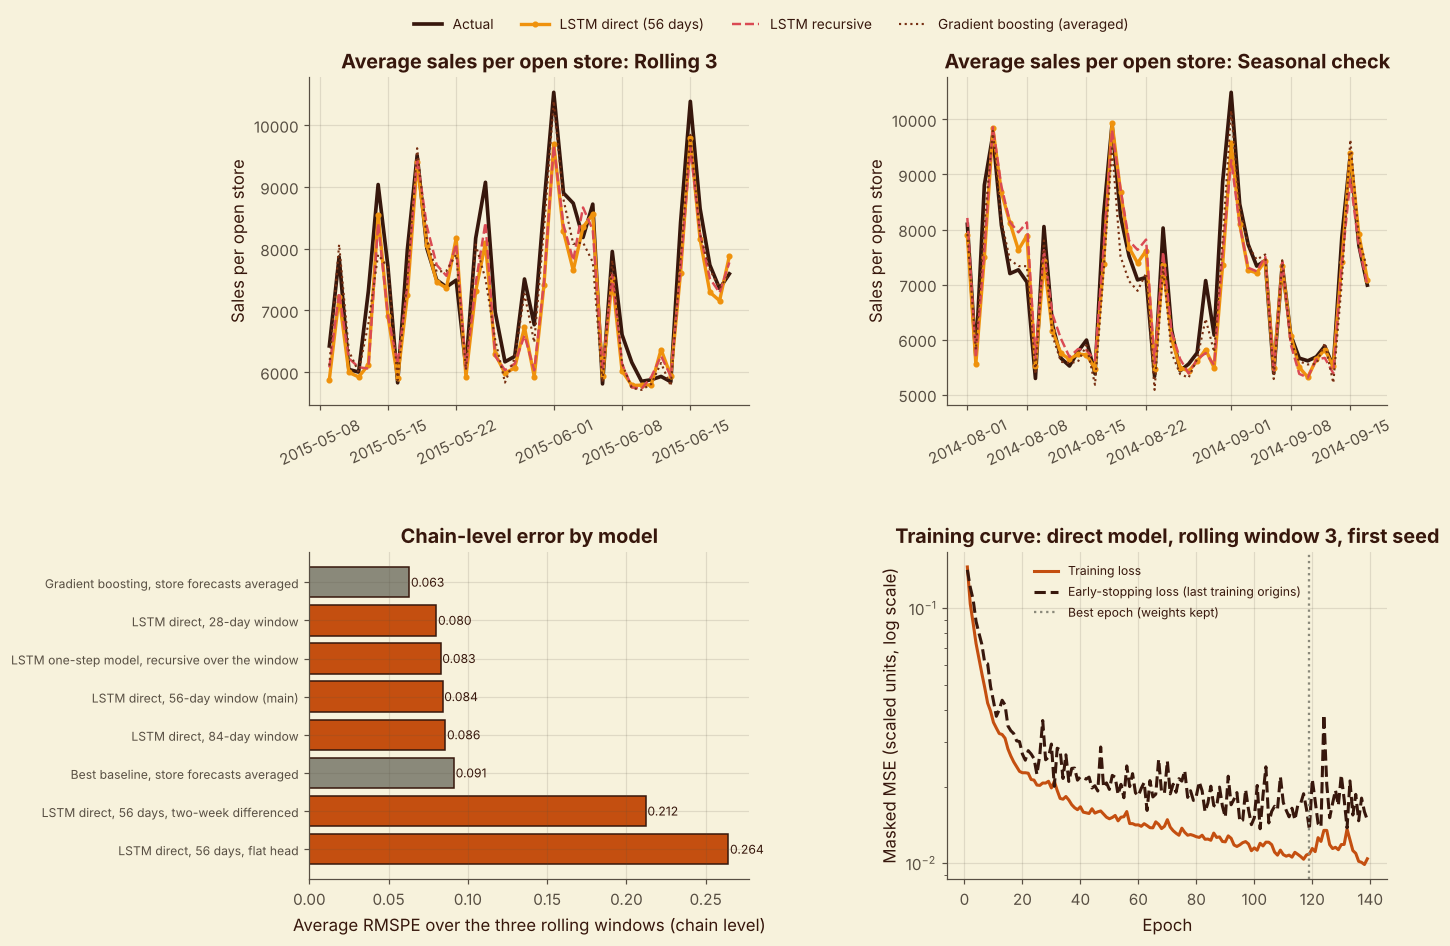

Chain-level runs logged in MLflow.


In [15]:
# Figure: forecasts against actuals for two windows, and RMSPE by variant
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, name in zip(axes[0], ["rolling_3", "seasonal_check"]):
    days = window_days(name)
    ax.plot(days, chain_actual[name], color=FORECAST_COLORS["actual"], linewidth=2.4, label="Actual")
    ax.plot(days, chain_results[direct][name].mean(axis=0), color=FORECAST_COLORS["forecast"], linewidth=2.2, marker="o", markersize=3, label="LSTM direct (56 days)")
    ax.plot(days, chain_results["one-step model, recursive over the window"][name].mean(axis=0), color=PALETTE["rose"], linewidth=1.6, linestyle="--", label="LSTM recursive")
    ax.plot(days, chain_ref[name]["gb"].values, color=PALETTE["umber"], linewidth=1.4, linestyle=":", label="Gradient boosting (averaged)")
    ax.set_title(f"Average sales per open store: {WINDOW_LABELS[name]}")
    ax.set_ylabel("Sales per open store")
    ax.tick_params(axis="x", rotation=25)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=4, fontsize=9, bbox_to_anchor=(0.5, 0.995))
order = list(chain_pivot.index)
y = np.arange(len(order))
ax = axes[1, 0]
ax.barh(y, chain_pivot["rolling average"].values, color=[PALETTE["stone"] if not m.startswith("LSTM") else PALETTE["terracotta"] for m in order],
        hatch=None, edgecolor=PALETTE["espresso"])
for i, v in enumerate(chain_pivot["rolling average"].values):
    ax.text(v + 0.001, i, f"{v:.3f}", va="center", fontsize=8)
ax.set_yticks(y)
ax.set_yticklabels([m.replace("LSTM: ", "LSTM ") for m in order], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("Average RMSPE over the three rolling windows (chain level)")
ax.set_title("Chain-level error by model")
h = chain_runs[direct].dropna(subset=["history"]).iloc[0]["history"] if "history" in chain_runs[direct] else None
if h is not None:
    axes[1, 1].plot(h.index, h["loss"], color=PALETTE["terracotta"], linewidth=2, label="Training loss")
    axes[1, 1].plot(h.index, h["val_loss"], color=PALETTE["espresso"], linewidth=2, linestyle="--", label="Early-stopping loss (last training origins)")
    axes[1, 1].axvline(h["val_loss"].idxmin(), color=PALETTE["stone"], linestyle=":", label="Best epoch (weights kept)")
    axes[1, 1].set_yscale("log")
    axes[1, 1].set_xlabel("Epoch")
    axes[1, 1].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    axes[1, 1].set_ylabel("Masked MSE (scaled units, log scale)")
    axes[1, 1].set_title("Training curve: direct model, rolling window 3, first seed")
    axes[1, 1].legend(fontsize=8)
fig.subplots_adjust(hspace=0.45, wspace=0.45, left=0.2, top=0.92)
style.save_figure(fig, 8, "Chain-level LSTM forecasts and errors")
plt.show()

# MLflow: one run per variant and window (metrics averaged over the seeds)
for variant, fc in chain_results.items():
    sc = score_chain(fc)
    info = chain_runs[variant]
    with mlflow.start_run(run_name=f"lstm-chain-{variant[:45]}"):
        mlflow.set_tags({"section": "8.3", "stage": "lstm-chain", "level": "chain"})
        mlflow.log_params({"variant": variant, "seeds": len(CHAIN_SEEDS), **{f"b_{k}": v for k, v in CHAIN_BUDGET.items()},
                           "parameters": int(info["parameters"].iloc[0])})
        mlflow.log_metrics({**{f"rmspe_{n}": float(sc.loc[n, "rmspe_mean"]) for n in ALL_WINDOWS},
                            **{f"rmspe_sd_{n}": float(sc.loc[n, "rmspe_sd"]) for n in ALL_WINDOWS},
                            "rmspe_rolling_mean": float(sc.loc[ROLLING, "rmspe_mean"].mean()), "seconds_per_fit": float(info["seconds"].mean())})
print("Chain-level runs logged in MLflow.")

**Reading the figure (8.5).** The direct and recursive LSTMs follow the weekly and two-week rhythm but under-shoot the peaks (the Monday after a promotion weekend, the days before holidays) in both windows. Gradient boosting tracks the peaks more closely. The training curve shows the early-stopping loss levelling off after about 80 epochs while the training loss keeps falling. The best weights are kept at that point.

## 8.4 One Shared Store-Level LSTM

**Question.** Can one LSTM, shared by all 1,115 stores, forecast each store's next 48 days as well as gradient boosting does on exactly the same rows?

**Method.**
- **Inputs per sample:** the store's 56-day history (scaled log sales minus the store's own mean, plus 17 planned-input channels), the planned inputs of the next 48 days plus the horizon position, a **store embedding** (8 numbers learned per store) and static inputs (store type, assortment, the store's typical level).
- **Model:** LSTM(64) -> dropout -> LSTM(64) encoder; context = encoder summary + store embedding + static inputs -> dense(64); per-day head (dense 64 -> 32 -> 1) applied to each future day; direct 48-day output.
- **Training data:** every store at every 7-day origin of the split's training period whose 48 targets fall inside it (about 100,000 to 113,000 samples per rolling split; Table 8.1). Early stopping on the **last 10% of training origins**; best weights checkpointed.
- **Training budget (documented):** each epoch draws a fresh random 40,960 samples (80 batches of 512); at most 8 epochs; patience 2. This sees each sample about three times over a full run. The budget keeps the whole section within about an hour on a 2-core CPU; on a Colab GPU the same cells take a few minutes, and the budget can be raised in `STORE_BUDGET`.
- **Scope:** all stores and all origins are used (no subset). One seed per split; the variance across seeds is measured on rolling window 3 with two extra seeds.
- **Scoring:** the same validation rows as Section 7 (open, positive-sales days of every store; closed days are forecast as 0 and not scored), also for the 856 test-file stores.

In [16]:
STORE_BUDGET = {"samples_per_epoch": 40_960, "epochs": 8, "patience": 2, "batch_size": 512, "units": 64, "dropout": 0.1,
                "dense_units": 64, "embed_dim": 8, "learning_rate": 1e-3}
EXTRA_SEEDS_ROLLING_3 = [config.SEED + 1, config.SEED + 2]


def train_store_lstm(name, seed, budget=STORE_BUDGET):
    """Train the shared store LSTM for one split; return (model, training curve, seconds, forecasts on the validation rows)."""
    s = SPLIT.loc[name]
    pan = scaled_store[name]
    tr, va = samples[("store", name)]
    fit_s, es_s = L.split_early_stopping(tr)
    feed = L.WindowFeed(pan, fit_s, W, H, s["train_end"], batch_size=budget["batch_size"], shuffle=True, seed=seed,
                        use_store=True, use_static=True, samples_per_epoch=budget["samples_per_epoch"])
    es_feed = L.WindowFeed(pan, es_s, W, H, s["train_end"], batch_size=1024, use_store=True, use_static=True)
    x0, _ = feed[0]
    model = POOL.get("store_lstm", lambda: L.build_lstm(
        W, H, x0["history"].shape[2], x0["future"].shape[2], units=budget["units"], dropout=budget["dropout"], n_stores=len(pan.stores),
        embed_dim=budget["embed_dim"], n_static=x0["static"].shape[1], dense_units=budget["dense_units"],
        learning_rate=budget["learning_rate"], name="store_lstm"), seed)
    hist, secs = L.fit(model, feed, es_feed, budget["epochs"], budget["patience"], ckpt_dir / f"store_lstm_{name}_{seed}.keras")
    t0 = time.time()
    va_feed = L.WindowFeed(pan, va, W, H, s["valid_end"], batch_size=1024, use_store=True, use_static=True)
    z = L.predict(model, va_feed)
    predict_secs = time.time() - t0
    fc = SQ.forecasts_to_rows(pan, va["series_idx"], va["origin_idx"], z, H)
    rows = valid_rows[name][["Store", "Date"]].merge(fc[["Store", "Date", "pred"]], on=["Store", "Date"], how="left")
    info = {"window": name, "seed": seed, "epochs_run": len(hist), "best_epoch": int(hist["val_loss"].idxmin()), "train_seconds": secs,
            "predict_seconds": predict_secs, "training_samples": len(fit_s), "early_stopping_samples": len(es_s),
            "samples_seen": len(hist) * min(budget["samples_per_epoch"], len(fit_s)), "parameters": model.count_params(),
            "validation_rows": len(rows), "rows_without_forecast": int(rows["pred"].isna().sum())}
    return model, hist, info, rows["pred"].values


# (slow: about 40 to 60 minutes on a 2-core CPU, a few minutes on a Colab GPU)
store_models, store_curves, store_info = {}, {}, []
t0 = time.time()
for name in ALL_WINDOWS:
    model, hist, info, pred = train_store_lstm(name, config.SEED)
    valid_rows[name]["lstm"] = pred
    store_curves[name] = hist
    store_info.append(info)
    if name == "rolling_3":
        model.save(ckpt_dir / "store_lstm_rolling_3.keras")       # the pooled model is re-used below, so keep this one on disk
    print(f"{WINDOW_LABELS[name]}: {info['epochs_run']} epochs, {info['train_seconds']:.0f} s ({time.time() - t0:.0f} s so far)", flush=True)

# seed variance on rolling window 3
seed_rows = [{"seed": config.SEED, "rmspe": F.rmspe(valid_rows["rolling_3"]["Sales"], valid_rows["rolling_3"]["lstm"])}]
for seed in EXTRA_SEEDS_ROLLING_3:
    _, _, info, pred = train_store_lstm("rolling_3", seed)
    store_info.append(info)
    seed_rows.append({"seed": seed, "rmspe": F.rmspe(valid_rows["rolling_3"]["Sales"], pred)})
    print(f"Rolling 3, seed {seed}: done ({time.time() - t0:.0f} s so far)", flush=True)
store_models["rolling_3"] = keras.saving.load_model(ckpt_dir / "store_lstm_rolling_3.keras")
store_info = pd.DataFrame(store_info)
seed_table = pd.DataFrame(seed_rows).set_index("seed")
store_lstm_total_seconds = time.time() - t0

Rolling 1: 8 epochs, 253 s (255 s so far)


Rolling 2: 8 epochs, 243 s (499 s so far)


Rolling 3: 7 epochs, 234 s (733 s so far)


Seasonal check: 8 epochs, 286 s (1020 s so far)


Rolling 3, seed 43: done (1291 s so far)


Rolling 3, seed 44: done (1574 s so far)


**Table 8.19: Store-level LSTM: training runs**

epochs_run  best_epoch  train_seconds  predict_seconds  training_samples  early_stopping_samples  samples_seen  parameters  validation_rows  rows_without_forecast
window         seed                                                                                                                                                                    
rolling_1      42             8           8          252.8              2.1             91716                    9350        327680       75801            40175                      0
rolling_2      42             8           7          242.6              1.1             97326                    9710        327680       75801            37044                      0
rolling_3      42             7           5          233.5              0.9            102001                   11725        286720       75801            37472                      0
seasonal_check 42             8           7          285.9              0.5             67991                    6899        327680       75801            38399                      0
rolling_3      43             8           7          269.4              1.1            102001                   11725        327680       75801            37472                      0
               44             8           7          281.8              1.1            102001                   11725        327680       75801            37472                      0

**Table 8.20: Store-level LSTM: variation across three seeds (rolling window 3)**

,rolling window 3
RMSPE by seed,"0.1334, 0.1283, 0.1407"
mean,0.1341
standard deviation,0.0051


**Table 8.21: Store-level LSTM against gradient boosting and the best baseline (same rows)**

rmspe  rmspe_test_stores       mae       rmse  bias_pct  within_10pct
window         model                                                                                    
rolling_1      Best baseline      0.1939             0.2119  601.1941   902.0681    2.9385       65.6229
               Gradient boosting  0.1725             0.1886  563.4687   826.5691   -2.5471       67.1836
               Store-level LSTM   0.1787             0.1959  571.6621   849.2601   -1.0986       67.5719
rolling_2      Best baseline      0.1713             0.1738  988.3316  1490.4238   -4.5298       53.1557
               Gradient boosting  0.1106             0.1120  627.6971   925.1897   -0.6662       69.6388
               Store-level LSTM   0.1470             0.1508  805.9737  1208.3777   -4.4009       60.4254
rolling_3      Best baseline      0.1533             0.1607  788.0938  1104.3669   -4.2320       55.4227
               Gradient boosting  0.1025             0.1048  542.2669   772.6214   -0.7963       72.7103
               Store-level LSTM   0.1334             0.1366  700.1188   992.7701   -1.9340       61.2004
seasonal_check Best baseline      0.1349             0.1396  649.1261   975.9566    3.1400       61.8089
               Gradient boosting  0.1045             0.1089  509.9893   798.3027   -0.5301       73.5436
               Store-level LSTM   0.1271             0.1312  636.4735   977.2345   -1.7474       63.5589

**Table 8.22: Where the store-level LSTM is more and less accurate than gradient boosting**

rows  GB rolling  LSTM rolling  rows seasonal  GB seasonal  LSTM seasonal  LSTM vs GB, rolling (%)
weekday    Mon             17861.0       0.204         0.206         6520.0        0.122          0.139                    1.072
           Tue             20052.0       0.123         0.132         6519.0        0.101          0.110                    7.247
           Wed             20049.0       0.103         0.120         6519.0        0.096          0.114                   16.515
           Thu             18287.0       0.109         0.135         5586.0        0.093          0.114                   23.572
           Fri             17863.0       0.108         0.126         6519.0        0.099          0.134                   16.179
           Sat             20058.0       0.124         0.165         6519.0        0.110          0.134                   33.175
           Sun               521.0       0.298         0.604          217.0        0.155          0.327                  102.601
holiday    Ordinary day   114470.0       0.132         0.153        38399.0        0.105          0.127                   15.744
           State holiday     221.0       0.463         0.598            NaN          NaN            NaN                   29.176
promotion  No promotion    61896.0       0.115         0.149        20703.0        0.111          0.138                   29.694
           Promotion       52795.0       0.152         0.162        17696.0        0.096          0.113                    6.061
store_type a               61789.0       0.139         0.160        21247.0        0.108          0.131                   15.645
           b                2142.0       0.121         0.166          768.0        0.091          0.160                   36.940
           c               15133.0       0.140         0.166         5453.0        0.098          0.118                   18.495
           d               35627.0       0.122         0.139        10931.0        0.102          0.120                   14.297
week_ahead 1               17923.0       0.227         0.241         5623.0        0.091          0.127                    6.360
           2               19053.0       0.125         0.165         5629.0        0.092          0.110                   31.568
           3               19057.0       0.099         0.117         5635.0        0.108          0.117                   18.447
           4               19455.0       0.106         0.121         5614.0        0.126          0.138                   14.016
           5               19056.0       0.098         0.134         5598.0        0.114          0.152                   36.553
           6               20147.0       0.108         0.123         5609.0        0.101          0.125                   14.277
           7                   NaN         NaN           NaN         4691.0        0.093          0.112                      NaN

Figure 8.6: Store-level LSTM forecasts, error by week and training curve


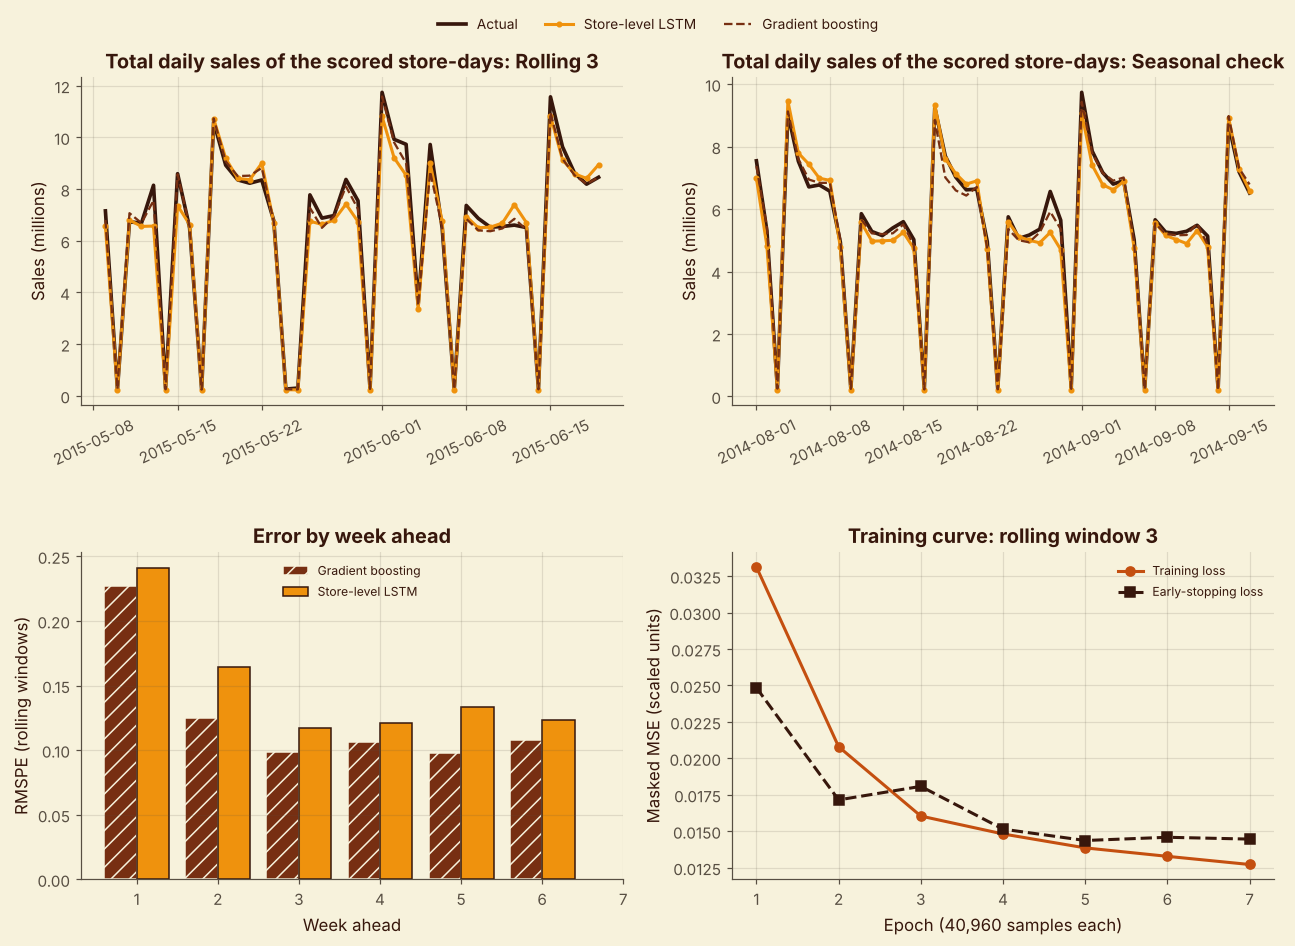

Store-level runs logged in MLflow.


In [17]:
assert (store_info["rows_without_forecast"] == 0).all(), "Some validation rows have no LSTM forecast"
style.show_table(store_info.set_index(["window", "seed"]).round(1), 8, "Store-level LSTM: training runs")
seed_summary = pd.Series({"RMSPE by seed": ", ".join(f"{v:.4f}" for v in seed_table["rmspe"]),
                          "mean": round(seed_table["rmspe"].mean(), 4), "standard deviation": round(seed_table["rmspe"].std(ddof=0), 4)},
                         dtype=object).to_frame("rolling window 3")
style.show_table(seed_summary, 8, "Store-level LSTM: variation across three seeds (rolling window 3)")

lstm_rows = []
for name in ALL_WINDOWS:
    v = valid_rows[name]
    for col, label in [("baseline", "Best baseline"), ("gb", "Gradient boosting"), ("lstm", "Store-level LSTM")]:
        lstm_rows.append({"window": name, "model": label, **E.metrics(v["Sales"], v[col], v["Store"], test_stores)})
lstm_scores = pd.DataFrame(lstm_rows)
style.show_table(lstm_scores.set_index(["window", "model"])[["rmspe", "rmspe_test_stores", "mae", "rmse", "bias_pct", "within_10pct"]].round(4),
                 8, "Store-level LSTM against gradient boosting and the best baseline (same rows)")

# where is the LSTM better or worse? (rolling windows pooled, and the seasonal check)
roll = E.add_groups(pd.concat([valid_rows[n] for n in ROLLING], ignore_index=True))
seas = E.add_groups(valid_rows["seasonal_check"])
parts = []
for by, order in [("weekday", list(DAYS.values())), ("holiday", None), ("promotion", None), ("store_type", list("abcd")), ("week_ahead", list(range(1, 8)))]:
    a = E.breakdown(roll, ["gb", "lstm"], by).rename(columns={"gb": "GB rolling", "lstm": "LSTM rolling"})
    b = E.breakdown(seas, ["gb", "lstm"], by).rename(columns={"rows": "rows seasonal", "gb": "GB seasonal", "lstm": "LSTM seasonal"})
    t = a.join(b, how="outer")
    if order is not None:
        t = t.reindex([o for o in order if o in t.index])
    t.index = pd.MultiIndex.from_product([[by], t.index.astype(str)])
    parts.append(t)
lstm_breakdown = pd.concat(parts)
lstm_breakdown["LSTM vs GB, rolling (%)"] = 100 * (lstm_breakdown["LSTM rolling"] / lstm_breakdown["GB rolling"] - 1)
style.show_table(lstm_breakdown.round(3), 8, "Where the store-level LSTM is more and less accurate than gradient boosting")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, name in zip(axes[0], ["rolling_3", "seasonal_check"]):
    d = valid_rows[name].groupby("Date")[["Sales", "gb", "lstm"]].sum() / 1e6
    ax.plot(d.index, d["Sales"], color=FORECAST_COLORS["actual"], linewidth=2.4, label="Actual")
    ax.plot(d.index, d["lstm"], color=FORECAST_COLORS["forecast"], linewidth=2, marker="o", markersize=3, label="Store-level LSTM")
    ax.plot(d.index, d["gb"], color=PALETTE["umber"], linewidth=1.5, linestyle="--", label="Gradient boosting")
    ax.set_title(f"Total daily sales of the scored store-days: {WINDOW_LABELS[name]}")
    ax.set_ylabel("Sales (millions)")
    ax.tick_params(axis="x", rotation=25)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=3, fontsize=9, bbox_to_anchor=(0.5, 0.995))
wk = lstm_breakdown.loc["week_ahead"]
x = np.arange(len(wk))
axes[1, 0].bar(x - 0.2, wk["GB rolling"], width=0.4, color=PALETTE["umber"], hatch="//", edgecolor=PALETTE["cream"], label="Gradient boosting")
axes[1, 0].bar(x + 0.2, wk["LSTM rolling"], width=0.4, color=PALETTE["marigold"], edgecolor=PALETTE["espresso"], label="Store-level LSTM")
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(wk.index)
axes[1, 0].set_xlabel("Week ahead")
axes[1, 0].set_ylabel("RMSPE (rolling windows)")
axes[1, 0].set_title("Error by week ahead")
axes[1, 0].legend(fontsize=8)
h = store_curves["rolling_3"]
axes[1, 1].plot(h.index, h["loss"], color=PALETTE["terracotta"], marker="o", linewidth=2, label="Training loss")
axes[1, 1].plot(h.index, h["val_loss"], color=PALETTE["espresso"], marker="s", linewidth=2, linestyle="--", label="Early-stopping loss")
axes[1, 1].set_xlabel(f"Epoch ({STORE_BUDGET['samples_per_epoch']:,} samples each)")
axes[1, 1].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[1, 1].set_ylabel("Masked MSE (scaled units)")
axes[1, 1].set_title("Training curve: rolling window 3")
axes[1, 1].legend(fontsize=8)
fig.subplots_adjust(hspace=0.45, top=0.92)
style.save_figure(fig, 8, "Store-level LSTM forecasts, error by week and training curve")
plt.show()

for name in ALL_WINDOWS:
    r = store_info[(store_info["window"] == name) & (store_info["seed"] == config.SEED)].iloc[0]
    sc = lstm_scores[(lstm_scores["window"] == name) & (lstm_scores["model"] == "Store-level LSTM")].iloc[0]
    with mlflow.start_run(run_name=f"lstm-store-{name}"):
        mlflow.set_tags({"section": "8.4", "stage": "lstm-store", "level": "store"})
        mlflow.log_params({"window": name, "seed": config.SEED, **{f"b_{k}": v for k, v in STORE_BUDGET.items()}, "history_days": W, "horizon_days": H,
                           "parameters": int(r["parameters"])})
        mlflow.log_metrics({"rmspe": sc["rmspe"], "rmspe_test_stores": sc["rmspe_test_stores"], "mae": sc["mae"], "rmse": sc["rmse"],
                            "bias_pct": sc["bias_pct"], "train_seconds": r["train_seconds"], "epochs_run": r["epochs_run"]})
print("Store-level runs logged in MLflow.")

**Reading the result.**
- Every one of the Section 7 validation rows has an LSTM forecast. Each split trained for 7 to 8 epochs of 40,960 samples (about 4 to 5 minutes each on 2 CPU cores). The best epoch was 5 to 8, so a larger budget could still help a little.
- **Accuracy:** the shared store-level LSTM scores 0.1787 / 0.1470 / 0.1334 (rolling 1 to 3) and 0.1271 (seasonal). It beats the best baseline everywhere (0.1939 / 0.1713 / 0.1533 / 0.1349) but loses to gradient boosting everywhere (0.1725 / 0.1106 / 0.1025 / 0.1045). It comes closest in rolling 1, where it is only 3.6% worse.
- **Seed spread** on rolling 3: 0.1334 / 0.1283 / 0.1407 (sd 0.0051). Even the best seed is 25% worse than gradient boosting.
- **Where it loses most:** Saturdays (+33% error vs gradient boosting), Sundays of the few Sunday-trading stores (+103%), non-promotion days (+30%) and type b stores (+37%). **Where it is closest:** Mondays (+1%), promotion days (+6%) and forecast week 1 (+6%). The LSTM learns the promotion rhythm well. It is weaker at the store-specific weekday profile, which gradient boosting receives ready-made as `hist_dow_mean_all`, its most important input (9.2).

## 8.5 Fair Comparison: LSTM, Gradient Boosting, Baseline and an Ensemble

**Question.** Which model should go forward, judged on the same stores, dates, information and metrics?

**Fairness conditions.** Every model is scored on the identical Section 7 validation rows; every model sees only history up to the split's cut-off and the same planned inputs; every model is trained on its split's training period only; nothing is tuned on the seasonal check.

**Decision rule, fixed before the comparison is computed** (logged in the Decision Register in the next cell): gradient boosting stays the production model unless a challenger (the store-level LSTM, or a simple 50/50 average of the LSTM and gradient boosting) is
1. more accurate in **all three rolling windows and the seasonal check**, and
2. better on the pooled rolling windows with a **95% store-level bootstrap interval entirely below zero**, and
3. better by **at least 3%** of the gradient-boosting RMSPE, because serving an LSTM adds TensorFlow (about 0.5 GB) and a second model to the app.

The ensemble weight is fixed at 0.5 and is not tuned (tuning it on the validation windows would bias the comparison).

In [18]:
rule_id = log_decision(8, "Decision rule for 8.5 (fixed before scoring): gradient boosting stays unless a challenger (store LSTM or 50/50 LSTM + GB average) wins every rolling window and the seasonal check, has a pooled-rolling bootstrap 95% interval below zero, and improves RMSPE by at least 3%.",
                       "Prevents choosing a model on noise and accounts for the extra serving cost of an LSTM.")
for name in ALL_WINDOWS:
    valid_rows[name]["ensemble"] = 0.5 * valid_rows[name]["gb"] + 0.5 * valid_rows[name]["lstm"]

MODELS_8 = {"baseline": "Best baseline", "gb": "Gradient boosting", "lstm": "Store-level LSTM", "ensemble": "Ensemble (50% LSTM, 50% GB)"}
rows = []
for name in ALL_WINDOWS:
    v = valid_rows[name]
    for col, label in MODELS_8.items():
        rows.append({"window": name, "model": label, **E.metrics(v["Sales"], v[col], v["Store"], test_stores)})
pooled = pd.concat([valid_rows[n] for n in ROLLING], ignore_index=True)
for col, label in MODELS_8.items():
    rows.append({"window": "rolling (pooled)", "model": label, **E.metrics(pooled["Sales"], pooled[col], pooled["Store"], test_stores)})
comparison8 = pd.DataFrame(rows)
cmp_pivot = comparison8.pivot(index="model", columns="window", values="rmspe")[ALL_WINDOWS + ["rolling (pooled)"]].reindex(MODELS_8.values())
style.show_table(cmp_pivot.round(4), 8, "Store-day RMSPE of every model on identical rows")
style.show_table(comparison8.pivot(index="model", columns="window", values="rmspe_test_stores")[ALL_WINDOWS].reindex(MODELS_8.values()).round(4), 8,
                 "Store-day RMSPE on the 856 test-file stores")

# paired store-level bootstrap: challenger minus gradient boosting (negative = challenger better)
boot_rows = []
for challenger in ["lstm", "ensemble"]:
    for name, rows_ in [(n, valid_rows[n]) for n in ALL_WINDOWS] + [("rolling (pooled)", pooled)]:
        b = E.paired_bootstrap(rows_, challenger, "gb", n_boot=1000, seed=config.SEED)
        gb_rmspe = F.rmspe(rows_["Sales"], rows_["gb"])
        boot_rows.append({"challenger": MODELS_8[challenger], "window": name, "RMSPE difference vs GB": b["difference"],
                          "95% interval low": b["ci_low"], "95% interval high": b["ci_high"], "change vs GB (%)": 100 * b["difference"] / gb_rmspe,
                          "interval low (%)": 100 * b["ci_low"] / gb_rmspe, "interval high (%)": 100 * b["ci_high"] / gb_rmspe,
                          "share of resamples where challenger is better": b["share_of_resamples_a_better"]})
boot = pd.DataFrame(boot_rows).set_index(["challenger", "window"])
style.show_table(boot.round(4), 8, "Paired bootstrap over stores: challenger minus gradient boosting")

# apply the rule
verdict_rows = []
for challenger in ["lstm", "ensemble"]:
    lab = MODELS_8[challenger]
    wins_all = bool(all(cmp_pivot.loc[lab, n] < cmp_pivot.loc["Gradient boosting", n] for n in ALL_WINDOWS))
    ci_below = bool(boot.loc[(lab, "rolling (pooled)"), "95% interval high"] < 0)
    big_enough = bool(boot.loc[(lab, "rolling (pooled)"), "change vs GB (%)"] <= -3.0)
    verdict_rows.append({"challenger": lab, "wins every window": wins_all, "pooled interval below zero": ci_below,
                         "gain of at least 3%": big_enough, "replaces gradient boosting": wins_all and ci_below and big_enough})
verdict = pd.DataFrame(verdict_rows).set_index("challenger")
style.show_table(verdict, 8, "Decision rule applied")
production_model = "Gradient boosting" if not verdict["replaces gradient boosting"].any() else verdict.index[verdict["replaces gradient boosting"]][0]
print("Model going forward:", production_model)

**Table 8.23: Store-day RMSPE of every model on identical rows**

window,rolling_1,rolling_2,rolling_3,seasonal_check,rolling (pooled)
model,,,,,
Best baseline,0.1939,0.1713,0.1533,0.1349,0.1741
Gradient boosting,0.1725,0.1106,0.1025,0.1045,0.1334
Store-level LSTM,0.1787,0.1470,0.1334,0.1271,0.1549
"Ensemble (50% LSTM, 50% GB)",0.1703,0.1208,0.1120,0.1092,0.1377


**Table 8.24: Store-day RMSPE on the 856 test-file stores**

window,rolling_1,rolling_2,rolling_3,seasonal_check
model,,,,
Best baseline,0.2119,0.1738,0.1607,0.1396
Gradient boosting,0.1886,0.1120,0.1048,0.1089
Store-level LSTM,0.1959,0.1508,0.1366,0.1312
"Ensemble (50% LSTM, 50% GB)",0.1872,0.1233,0.1146,0.1137


**Table 8.25: Paired bootstrap over stores: challenger minus gradient boosting**

RMSPE difference vs GB  95% interval low  95% interval high  change vs GB (%)  interval low (%)  interval high (%)  \
challenger                  window                                                                                                                                 
Store-level LSTM            rolling_1                         0.0062            0.0010             0.0141            3.6224            0.5672             8.1584   
                            rolling_2                         0.0364            0.0296             0.0450           32.9324           26.7345            40.6823   
                            rolling_3                         0.0309            0.0260             0.0374           30.1779           25.3735            36.5040   
                            seasonal_check                    0.0226            0.0201             0.0257           21.6316           19.1962            24.5727   
                            rolling (pooled)                  0.0214            0.0168             0.0267           16.0731           12.6131            19.9936   
Ensemble (50% LSTM, 50% GB) rolling_1                        -0.0022           -0.0047             0.0017           -1.2541           -2.7330             0.9963   
                            rolling_2                         0.0102            0.0068             0.0144            9.1842            6.1460            13.0310   
                            rolling_3                         0.0095            0.0074             0.0123            9.2856            7.2545            11.9630   
                            seasonal_check                    0.0047            0.0031             0.0062            4.4502            3.0085             5.9387   
                            rolling (pooled)                  0.0043            0.0021             0.0067            3.2231            1.5968             4.9865   

                                              share of resamples where challenger is better  
challenger                  window                                                           
Store-level LSTM            rolling_1                                                 0.002  
                            rolling_2                                                 0.000  
                            rolling_3                                                 0.000  
                            seasonal_check                                            0.000  
                            rolling (pooled)                                          0.000  
Ensemble (50% LSTM, 50% GB) rolling_1                                                 0.892  
                            rolling_2                                                 0.000  
                            rolling_3                                                 0.000  
                            seasonal_check                                            0.000  
                            rolling (pooled)                                          0.000

**Table 8.26: Decision rule applied**

,wins every window,pooled interval below zero,gain of at least 3%,replaces gradient boosting
challenger,,,,
Store-level LSTM,False,False,False,False
"Ensemble (50% LSTM, 50% GB)",False,False,False,False


Model going forward: Gradient boosting


**Reading the result.**
- **Store LSTM vs gradient boosting:** worse in all four windows. On the pooled rolling windows it is 16.1% worse (95% store-bootstrap interval +12.6% to +20.0%). Its own interval lies entirely above zero.
- **50/50 ensemble:** better than gradient boosting only in rolling 1 (-1.3%, interval -2.7% to +1.0%, so not significant). It is worse in rolling 2 (+9.2%), rolling 3 (+9.3%) and the seasonal check (+4.5%), and 3.2% worse pooled (interval +1.6% to +5.0%).
- **Decision (rule fixed beforehand):** neither challenger meets any of the three conditions. **Gradient boosting goes forward.** The same ranking holds on the 856 test-file stores.
- **What the LSTM adds:** it beats the best baseline with no hand-made history features, which independently confirms that the sales sequence contains the weekly and two-week structure found in 8.1. Its near-parity on Mondays, promotion days and rolling window 1 shows where sequence models are competitive. The gap elsewhere comes from per-store weekday profiles that the feature engineering hands directly to the tree model.

**Table 8.27: Cost of the candidate models**

,"training time (s, rolling 3)",size (MB),"forecast time (ms per 1,000 store-days)",extra serving dependency
model,,,,
Gradient boosting,50.66,4.35,35.06,none (scikit-learn)
Store-level LSTM,233.53,0.99,24.77,TensorFlow / Keras (about 0.5 GB)
Chain-level LSTM (one series),47.40,NaN,NaN,not a store forecast


Figure 8.7: Fair comparison of all models


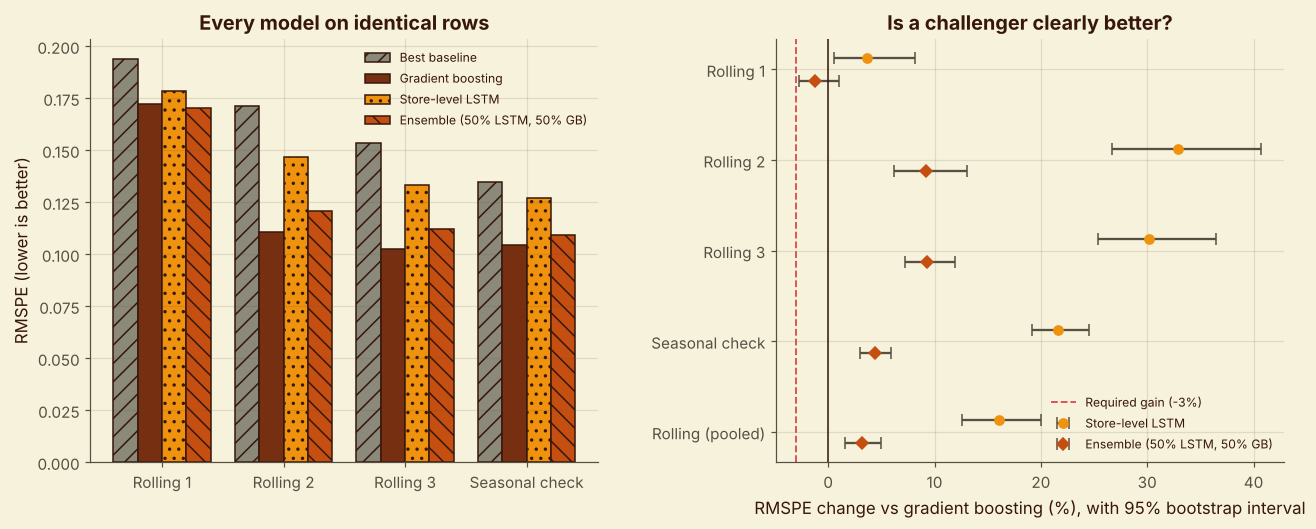

In [19]:
# cost of each model (training on one split, size on disk, time to forecast 1,000 store-days)
gb_model = gb_reference_model
v3 = valid_rows["rolling_3"]
t0 = time.time()
_ = gb_model.predict(dataset.loc[M.window_data(dataset, splits, "rolling_3")[1].index, FINAL_FEATURES])
gb_pred_ms = 1000 * (time.time() - t0) / len(v3) * 1000
lstm_r3 = store_info[(store_info["window"] == "rolling_3") & (store_info["seed"] == config.SEED)].iloc[0]
lstm_file = ckpt_dir / "store_lstm_rolling_3.keras"
chain_main = chain_runs["direct, 56-day window (main)"]
cost8 = pd.DataFrame([
    {"model": "Gradient boosting", "training time (s, rolling 3)": ref_fit_seconds[(FINAL_SET, "rolling_3")], "size (MB)": M.model_size_mb(gb_model),
     "forecast time (ms per 1,000 store-days)": gb_pred_ms, "extra serving dependency": "none (scikit-learn)"},
    {"model": "Store-level LSTM", "training time (s, rolling 3)": lstm_r3["train_seconds"], "size (MB)": lstm_file.stat().st_size / 1e6,
     "forecast time (ms per 1,000 store-days)": 1000 * lstm_r3["predict_seconds"] / lstm_r3["validation_rows"] * 1000,
     "extra serving dependency": "TensorFlow / Keras (about 0.5 GB)"},
    {"model": "Chain-level LSTM (one series)", "training time (s, rolling 3)": chain_main.loc[chain_main["window"] == "rolling_3", "seconds"].mean(),
     "size (MB)": np.nan, "forecast time (ms per 1,000 store-days)": np.nan, "extra serving dependency": "not a store forecast"},
]).set_index("model")
style.show_table(cost8.round(2), 8, "Cost of the candidate models")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(ALL_WINDOWS))
styles = {"Best baseline": (PALETTE["stone"], "//"), "Gradient boosting": (PALETTE["umber"], ""), "Store-level LSTM": (PALETTE["marigold"], ".."),
          "Ensemble (50% LSTM, 50% GB)": (PALETTE["terracotta"], "\\\\")}
for j, (lab, (col, hatch)) in enumerate(styles.items()):
    axes[0].bar(x + (j - 1.5) * 0.2, cmp_pivot.loc[lab, ALL_WINDOWS], width=0.2, color=col, hatch=hatch, edgecolor=PALETTE["espresso"], label=lab)
axes[0].set_xticks(x)
axes[0].set_xticklabels([WINDOW_LABELS[n] for n in ALL_WINDOWS])
axes[0].set_ylabel("RMSPE (lower is better)")
axes[0].set_title("Every model on identical rows")
axes[0].legend(fontsize=8)
bb = boot.reset_index()
for j, (lab, mk) in enumerate([("Store-level LSTM", "o"), ("Ensemble (50% LSTM, 50% GB)", "D")]):
    d = bb[bb["challenger"] == lab].set_index("window").loc[ALL_WINDOWS + ["rolling (pooled)"]]
    yy = np.arange(len(d)) + (j - 0.5) * 0.25
    axes[1].errorbar(d["change vs GB (%)"], yy, xerr=[d["change vs GB (%)"] - d["interval low (%)"], d["interval high (%)"] - d["change vs GB (%)"]],
                     fmt=mk, color=[PALETTE["marigold"], PALETTE["terracotta"]][j], ecolor=PALETTE["charcoal"], capsize=4, label=lab)
axes[1].axvline(0, color=PALETTE["espresso"], linewidth=1)
axes[1].axvline(-3, color=PALETTE["rose"], linestyle="--", linewidth=1.2, label="Required gain (-3%)")
axes[1].set_yticks(range(len(ALL_WINDOWS) + 1))
axes[1].set_yticklabels([WINDOW_LABELS.get(n, "Rolling (pooled)") for n in ALL_WINDOWS + ["rolling (pooled)"]])
axes[1].invert_yaxis()
axes[1].set_xlabel("RMSPE change vs gradient boosting (%), with 95% bootstrap interval")
axes[1].set_title("Is a challenger clearly better?")
axes[1].legend(fontsize=8)
fig.subplots_adjust(wspace=0.35)
style.save_figure(fig, 8, "Fair comparison of all models")
plt.show()

**Reading the result.** Gradient boosting trains in about 51 s on 400,000 rows and forecasts 1,000 store-days in about 35 ms. The store LSTM takes about 234 s to train (with a CPU budget), is small (1 MB) and forecasts slightly faster (25 ms per 1,000). Serving it, however, would add TensorFlow (about 0.5 GB) to the app. Cost does not change the decision. Accuracy already settled it.

In [20]:
# register the store-level LSTM (rolling window 3 model) in MLflow as a model version
import mlflow.keras
lstm_metrics = comparison8[(comparison8["model"] == "Store-level LSTM")].set_index("window")["rmspe"]
with mlflow.start_run(run_name="lstm-store-registered") as run:
    mlflow.set_tags({"section": "8.5", "stage": "lstm-register", "version_note": "trained on the rolling window 3 training period"})
    mlflow.log_params({"history_days": W, "horizon_days": H, **{f"b_{k}": v for k, v in STORE_BUDGET.items()}})
    mlflow.log_metrics({f"rmspe_{k.replace(' ', '_').replace('(', '').replace(')', '')}": float(v) for k, v in lstm_metrics.items()})
    try:
        lstm_info = mlflow.keras.log_model(store_models["rolling_3"], name="model", registered_model_name="rossmann-lstm-store")
    except TypeError:
        lstm_info = mlflow.keras.log_model(store_models["rolling_3"], artifact_path="model", registered_model_name="rossmann-lstm-store")
lstm_versions = len(client.search_model_versions("name='rossmann-lstm-store'"))
print(f"rossmann-lstm-store now has {lstm_versions} version(s) in the registry")

2026/11/03 12:10:18 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.


2026/11/03 12:10:25 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: /tmp/tmpc633dwow/model, flavor: keras). Fall back to return ['keras==3.15.1']. Set logging level to DEBUG to see the full traceback. 


rossmann-lstm-store now has 1 version(s) in the registry


Successfully registered model 'rossmann-lstm-store'.
Created version '1' of model 'rossmann-lstm-store'.


## 8.6 Section 8 Wrap-Up

The LSTMs are saved with timestamped names in `models/lstm/` together with everything needed to use them again (scaling, channels, window, horizon, training period); the reload is checked. The decisions and limitations below are written from the results above (the numbers are inserted by the code, not typed).

In [21]:
import shutil
lstm_dir = config.MODELS_DIR / "lstm"
lstm_dir.mkdir(parents=True, exist_ok=True)
ts_ = datetime.now().strftime(config.MODEL_TIMESTAMP_FORMAT)
store_file = lstm_dir / f"store-{ts_}.keras"
store_models["rolling_3"].save(store_file)
chain_ckpt = ckpt_dir / f"chain_{slug(direct)}_rolling_3.keras"
chain_file = lstm_dir / f"chain-{ts_}.keras"
shutil.copy(chain_ckpt, chain_file)
p3 = scaled_store["rolling_3"]
lstm_meta = {"store_model": store_file.name, "chain_model": chain_file.name, "trained_on": f"history up to {SPLIT.loc['rolling_3', 'train_end'].date()}",
             "window_days": W, "horizon_days": H, "store_channels": SQ.STORE_CHANNELS, "chain_channels": SQ.CHAIN_CHANNELS,
             "store_scaling": {"range_low": p3.scaling.scaler.lo_, "range_high": p3.scaling.scaler.hi_, "centres": dict(zip(map(int, p3.stores), map(float, p3.scaling.center)))},
             "budget": STORE_BUDGET, "framework": fw}
(lstm_dir / f"{ts_}.json").write_text(json.dumps(lstm_meta, indent=2, default=str), encoding="utf-8")

reloaded_lstm = keras.saving.load_model(store_file)
fb = L.WindowFeed(p3, samples[("store", "rolling_3")][1].head(64), W, H, SPLIT.loc["rolling_3", "valid_end"], batch_size=64, use_store=True, use_static=True)
same_lstm = bool(np.allclose(reloaded_lstm.predict_on_batch(fb[0][0]), store_models["rolling_3"].predict_on_batch(fb[0][0]), atol=1e-6))
print(f"Saved {store_file.name} and {chain_file.name}; reloaded store model gives identical forecasts: {same_lstm}")
shutil.rmtree(ckpt_dir, ignore_errors=True)                     # intermediate checkpoints are not kept

# ---- results the decisions quote
rec = rec_vs_direct
win_test = chain_pivot.loc[[f"LSTM: direct, {w}-day window" if w != 56 else f"LSTM: {direct}" for w in (28, 56, 84)], "rolling average"]
best_window = [28, 56, 84][int(np.argmin(win_test.values))]
diff_row = chain_pivot.loc["LSTM: direct, 56 days, two-week differenced", "rolling average"]
lev_row = chain_pivot.loc[f"LSTM: {direct}", "rolling average"]
flat_row = chain_pivot.loc["LSTM: direct, 56 days, flat head", "rolling average"]
gb_chain = chain_pivot.loc["Gradient boosting, store forecasts averaged", "rolling average"]
lstm_pool = cmp_pivot.loc["Store-level LSTM", "rolling (pooled)"]
gb_pool = cmp_pivot.loc["Gradient boosting", "rolling (pooled)"]
ens_pool = cmp_pivot.loc["Ensemble (50% LSTM, 50% GB)", "rolling (pooled)"]
base_pool = cmp_pivot.loc["Best baseline", "rolling (pooled)"]

c8 = pd.DataFrame([
    ("Five sequence-framing tests pass", bool(framing_tests["passed"].all())),
    ("Every Section 7 validation row has an LSTM forecast", bool((store_info["rows_without_forecast"] == 0).all())),
    ("Every chain variant trained with 3 seeds in every split", all(len(v) == len(ALL_WINDOWS) * len(CHAIN_SEEDS) for v in chain_runs.values())),
    ("No sales after 19 Jun 2015 inside any panel", bool(np.isnan(store_pan.sales[:, store_pan.dates > dev_end]).all())),
    ("No holdout evaluation before Section 10", int((evaluation_log["section"].astype(str) != "10").sum()) == 0),
    ("Store LSTM registered in MLflow", lstm_versions >= 1),
    ("Saved LSTM reloads with identical forecasts", same_lstm),
], columns=["check", "passed"]).set_index("check")
style.show_table(c8, 8, "Section 8 completion checks", save=False)
assert c8["passed"].all()

decision_register.loc[decision_register["decision"].str.startswith("Use a shared LSTM across stores"), "status"] = "Confirmed (built in 8.4)"
decision_register.loc[decision_register["decision"].str.startswith("Stationarity: ADF rejects a unit root"), "status"] = \
    "Confirmed: levels kept (8.3)" if diff_row >= lev_row else "Revised: two-week differencing helps at chain level (8.3)"
rec_avg, dir_avg = rec["recursive (one-step model)"][ROLLING].mean(), rec["direct (main)"][ROLLING].mean()
rec_seas, dir_seas = rec.loc["seasonal_check", "recursive (one-step model)"], rec.loc["seasonal_check", "direct (main)"]
log_decision(8, f"Direct 48-day forecasting is used for the store-level LSTM. At chain level, recursive and direct forecasts are close: average rolling RMSPE {rec_avg:.4f} (recursive) vs {dir_avg:.4f} (direct); seasonal check {rec_seas:.4f} vs {dir_seas:.4f}.",
             ("Neither framing wins clearly (differences are of the size of the seed spread). Direct forecasting needs one pass per origin instead of 48 sequential ones, "
              "cannot feed its own errors back, and reads the planned calendar of every future day directly, so it is kept.") if abs(rec_avg - dir_avg) / dir_avg < 0.05 or (rec_avg - dir_avg) * (rec_seas - dir_seas) < 0
             else ("Direct is clearly more accurate." if dir_avg < rec_avg else "Recursive is more accurate at chain level; direct is kept for the store model for speed and is flagged as a limitation."))
log_decision(8, f"History window: 56 days kept (rolling-average chain RMSPE: 28 days {win_test.iloc[0]:.4f}, 56 days {win_test.iloc[1]:.4f}, 84 days {win_test.iloc[2]:.4f}; best = {best_window}).",
             "56 days covers four two-week cycles; differences between windows are compared with the seed spread before changing the design.")
log_decision(8, f"Two-week differencing is {'not adopted' if diff_row >= lev_row else 'better at chain level but not used at store level'} (chain RMSPE {diff_row:.4f} differenced vs {lev_row:.4f} levels); per-day head kept (flat head {flat_row:.4f}).",
             "8.1 showed the series is trend-stationary; differencing is only worth its extra inversion step if it lowers the error.")
log_decision(8, f"Model going forward: {production_model}. Pooled rolling RMSPE: gradient boosting {gb_pool:.4f}, store LSTM {lstm_pool:.4f}, 50/50 ensemble {ens_pool:.4f}, best baseline {base_pool:.4f}.",
             f"Decision rule {rule_id} applied as fixed before the comparison.")
log_limitation(8, f"The store LSTM was trained on a CPU budget (40,960 samples per epoch, at most 8 epochs; {store_info.loc[store_info['seed'] == config.SEED, 'epochs_run'].mean():.0f} epochs on average before early stopping).",
               "A GPU and a larger budget could lower its error; the comparison is fair for the stated budget, not a ceiling for LSTMs.")
log_limitation(8, f"LSTM results vary with the seed (store LSTM, rolling 3: standard deviation {seed_table['rmspe'].std(ddof=0):.4f} over 3 seeds; chain variants: Table of seed standard deviations).",
               "Differences between LSTM variants smaller than the seed spread are not meaningful.")
log_limitation(8, "The chain-level LSTM forecasts one aggregate series (about 100 training origins per split), not store-day sales.",
               "It shows the brief's time-series steps on the series of 8.1; store forecasts come from the shared store model.")
save_registers()
style.save_index()
sh("git add -A")
sh('git commit -m "Section 8: sequence framing, chain and store LSTMs, fair comparison"', check=False, quiet=True)
display(decision_register.tail(8))

Saved store-03-11-2026-12-10-25.keras and chain-03-11-2026-12-10-25.keras; reloaded store model gives identical forecasts: True


**Table 8.28: Section 8 completion checks**

,passed
check,
Five sequence-framing tests pass,True
Every Section 7 validation row has an LSTM forecast,True
Every chain variant trained with 3 seeds in every split,True
No sales after 19 Jun 2015 inside any panel,True
No holdout evaluation before Section 10,True
Store LSTM registered in MLflow,True
Saved LSTM reloads with identical forecasts,True


,id,section,decision,reason,status
60,D61,8,"LSTM samples use a direct 48-day strategy: 56-day history window, a training origin every 7 days anchored at the latest origin whose targets fit in the training period, planned inputs for every fu...","Matches the real forecast (one cut-off, a long window, a known calendar); five leakage and correctness tests pass.",Confirmed
61,D62,8,Days missing from the record (the 2014 gap) are zero-filled and flagged with has_record; a history window needs records on at least half of its days; nothing is interpolated.,Keeps the 180 gap stores usable soon after the gap without inventing sales.,Confirmed
62,D63,8,"Deep learning framework: Keras 3.15.1 on tensorflow (code uses keras.ops only, so the PyTorch backend also works); seeds via keras.utils.set_random_seed.",Colab default; portable to Python versions without a TensorFlow build.,Confirmed
63,D64,8,"Decision rule for 8.5 (fixed before scoring): gradient boosting stays unless a challenger (store LSTM or 50/50 LSTM + GB average) wins every rolling window and the seasonal check, has a pooled-rol...",Prevents choosing a model on noise and accounts for the extra serving cost of an LSTM.,Confirmed
64,D65,8,"Direct 48-day forecasting is used for the store-level LSTM. At chain level, recursive and direct forecasts are close: average rolling RMSPE 0.0828 (recursive) vs 0.0841 (direct); seasonal check 0....","Neither framing wins clearly (differences are of the size of the seed spread). Direct forecasting needs one pass per origin instead of 48 sequential ones, cannot feed its own errors back, and read...",Confirmed
65,D66,8,"History window: 56 days kept (rolling-average chain RMSPE: 28 days 0.0801, 56 days 0.0841, 84 days 0.0858; best = 28).",56 days covers four two-week cycles; differences between windows are compared with the seed spread before changing the design.,Confirmed
66,D67,8,Two-week differencing is not adopted (chain RMSPE 0.2122 differenced vs 0.0841 levels); per-day head kept (flat head 0.2643).,8.1 showed the series is trend-stationary; differencing is only worth its extra inversion step if it lowers the error.,Confirmed
67,D68,8,"Model going forward: Gradient boosting. Pooled rolling RMSPE: gradient boosting 0.1334, store LSTM 0.1549, 50/50 ensemble 0.1377, best baseline 0.1741.",Decision rule D64 applied as fixed before the comparison.,Confirmed


## 8.6 Section 8 Summary

**What is now fixed**
- Sequence framing (8.2): direct 48-day samples with a 56-day history, origins every 7 days, (-1, 1) scaling fitted on training days only, and lazy windows from an 84 MB panel. Five leakage and correctness tests pass.
- The brief's model (8.3): a two-layer LSTM predicting the next sale reaches a one-step RMSPE of about 0.08 at chain level. Recursive and direct six-week forecasts are within seed noise of each other. Window length barely matters. Differencing and a flat head hurt badly.
- Store-level shared LSTM (8.4): pooled rolling RMSPE 0.1549. It beats the best baseline (0.1741) but not gradient boosting (0.1334). **Gradient boosting stays the production model** under a rule fixed before the comparison (8.5).
- The saved LSTMs (`models/lstm/store-<timestamp>.keras`, `chain-<timestamp>.keras` plus metadata) reload with identical forecasts. `rossmann-lstm-store` is registered in MLflow.

**Figures and story points for the blog's deep learning section**
1. Figure 8.3 (Part 1): autocorrelation peaks at 14, 28, 42 and 56. The promotion calendar creates a two-week rhythm, which is why the history window is 56 days.
2. Table 8.11: five tests show the sliding windows cannot leak the future.
3. Figure 8.5 and Table 8.15: the next-sale model, recursive vs direct, window, differencing and head tests, all at chain level with three seeds. An honest null result on recursive vs direct.
4. Figure 8.6 and Table 8.22: one LSTM for 1,115 stores. Where it is close (Mondays, promotion days, week 1) and where it is not (Saturdays, Sunday traders, type b).
5. Figure 8.7 and Tables 8.25 to 8.26: the pre-registered decision rule, the bootstrap intervals and the verdict.

---

# Section 9: Customers, Explainability and Uncertainty

| Step | What it covers |
|---|---|
| 9.1 | Customer forecasts (the dashboard shows customers next to sales) |
| 9.2 | What drives the sales forecasts: split-gain importance, permutation importance, SHAP, four forecasts explained |
| 9.3 | 90% prediction intervals: split-conformal calibration, compared with quantile regression |
| 9.4 | Wrap-up |

## 9.1 Customer Forecasting

**Question.** How accurately can we forecast the number of customers per store-day, using only what is known at the forecast origin?

**Method.** Same pipeline, same 59 features and the same rows as the sales model. Past customers enter only through the history features computed up to the origin (`hist_customers_91`, `hist_spc_91`); the customers of the forecast day are never an input (the availability policy blocks the `Customers` column). The model learns log(1 + Customers). A small tuning step (three settings, 100,000 rows, the three rolling windows) chooses the configuration; the chosen one is then trained on 400,000 rows per split, like the sales candidate. Baseline: the store-by-weekday-and-promotion average of customers.

In [22]:
%%writefile src/customers.py
"""Customer forecasts: the same pipeline and the same forecast-time features as the sales model, with Customers
as the target. Only past customers (history features up to the forecast origin) are inputs; the customers of the
forecast day itself never are."""
import time

import numpy as np
import pandas as pd

from . import models as M
from .evaluation import metrics

TARGET = "Customers"


def customer_baseline(valid_rows, hist, origin):
    """Store-by-weekday-and-promotion average of customers up to the origin (falls back to store-by-weekday, then store)."""
    h = hist[(hist["Date"] <= pd.Timestamp(origin)) & (hist["Open"] == 1) & (hist["Sales"] > 0)]
    by_promo = h.groupby(["Store", "DayOfWeek", "Promo"])["Customers"].mean().rename("by_promo")
    by_dow = h.groupby(["Store", "DayOfWeek"])["Customers"].mean().rename("by_dow")
    by_store = h.groupby("Store")["Customers"].mean().rename("by_store")
    r = valid_rows[["Store", "DayOfWeek", "promo"]].rename(columns={"promo": "Promo"})
    r = r.join(by_promo, on=["Store", "DayOfWeek", "Promo"]).join(by_dow, on=["Store", "DayOfWeek"]).join(by_store, on="Store")
    out = r["by_promo"].fillna(r["by_dow"]).fillna(r["by_store"]).fillna(float(h["Customers"].median()))
    return out.values, float(r["by_promo"].isna().mean())


def fit_and_score(kind, params, features, train_rows, valid_rows, test_stores=None, keep_model=False):
    """Fit the customers model (learns log1p(Customers)) and score it on the validation rows."""
    model = M.make_model(kind, features, log_target=True, **params)
    t0 = time.time()
    model.fit(train_rows[features], train_rows[TARGET])
    fit_seconds = time.time() - t0
    pred = np.maximum(model.predict(valid_rows[features]), 0.0)
    res = metrics(valid_rows[TARGET], pred, valid_rows["Store"], test_stores)
    res.update({"fit_seconds": fit_seconds, "train_rows": len(train_rows), "valid_rows": len(valid_rows)})
    return (res, pred, model) if keep_model else (res, pred)

Writing src/customers.py


2026-11-03 12:10:29 | INFO     | rossmann.validation | Feature policy check passed for 59 features.


**Table 9.1: Customer model tuning (RMSPE on customers, 100,000 training rows)**

window,rolling_1,rolling_2,rolling_3,rolling average
settings,,,,
faster learning (rate 0.1),0.1526,0.0974,0.0928,0.1143
same settings as the sales model,0.1503,0.0989,0.0944,0.1145
smaller trees (63 leaves),0.1518,0.0990,0.0960,0.1156


**Table 9.2: Customer forecasts: RMSPE by window**

window,rolling_1,rolling_2,rolling_3,seasonal_check,rolling average
model,,,,,
Customer baseline,0.1759,0.1418,0.1263,0.1158,0.1480
Customer model,0.1490,0.0918,0.0856,0.0905,0.1088


**Table 9.3: Customer forecasts: all metrics**

rmspe  rmspe_test_stores     mae  bias_pct  within_10pct
window         model                                                                      
rolling_1      Customer baseline  0.176              0.192  56.378     4.223        73.386
               Customer model     0.149              0.164  48.773    -1.262        79.709
rolling_2      Customer baseline  0.142              0.144  79.650    -1.839        62.779
               Customer model     0.092              0.093  51.780    -0.058        79.624
rolling_3      Customer baseline  0.126              0.132  65.405    -1.060        67.597
               Customer model     0.086              0.087  47.468    -0.297        80.447
seasonal_check Customer baseline  0.116              0.120  63.346     3.050        69.247
               Customer model     0.091              0.095  50.257    -0.357        79.203

**Table 9.4: Sanity check: spend per customer implied by the two forecasts (rolling windows)**

,actual_median,forecast_median,difference (%)
store_type,,,
a,8.90,8.84,-0.60
b,5.24,5.12,-2.30
c,8.71,8.67,-0.55
d,11.55,11.38,-1.48


Forecast spend per customer outside the store's own 1st-99th percentile range: 1.28% of store-days (actual spend per customer: 3.54%)
Figure 9.1: Customer forecasts


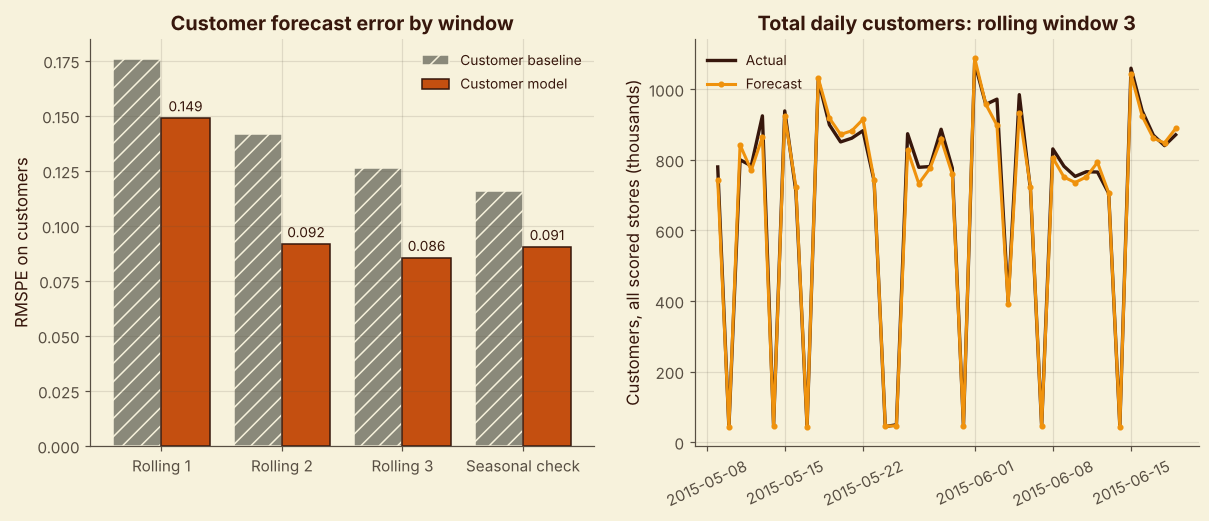

2026/11/03 12:17:41 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Successfully registered model 'rossmann-customers'.
Created version '1' of model 'rossmann-customers'.


In [23]:
from src import customers as C
importlib.reload(C)
validation.check_features(FINAL_FEATURES)                      # the customers model uses exactly the sales features

CUSTOMER_GRID = {
    "same settings as the sales model": dict(FINAL_PARAMS),
    "smaller trees (63 leaves)": {**FINAL_PARAMS, "max_leaf_nodes": 63},
    "faster learning (rate 0.1)": {**FINAL_PARAMS, "learning_rate": 0.1},
}
# (slow: about 8 minutes) tuning on 100,000 rows per rolling window
tune_rows = []
for name in ROLLING:
    train, valid = M.window_data(dataset, splits, name, train_sample=100_000)
    for label, params in CUSTOMER_GRID.items():
        res, _ = C.fit_and_score(FINALIST, params, FINAL_FEATURES, train, valid, test_stores)
        tune_rows.append({"settings": label, "window": name, "rmspe": res["rmspe"], "fit_seconds": res["fit_seconds"]})
    del train, valid
    gc.collect()
cust_tune = pd.DataFrame(tune_rows).pivot(index="settings", columns="window", values="rmspe")[ROLLING]
cust_tune["rolling average"] = cust_tune.mean(axis=1)
cust_tune = cust_tune.sort_values("rolling average")
CUSTOMER_PARAMS = CUSTOMER_GRID[cust_tune.index[0]]
style.show_table(cust_tune.round(4), 9, "Customer model tuning (RMSPE on customers, 100,000 training rows)")

# (slow: about 8 minutes) the chosen settings on 400,000 rows, every window, against the customer baseline
cust_models = {}
for name in ALL_WINDOWS:
    s = SPLIT.loc[name]
    train, valid = M.window_data(dataset, splits, name, train_sample=CANDIDATE_ROWS)
    res, pred, model = C.fit_and_score(FINALIST, CUSTOMER_PARAMS, FINAL_FEATURES, train, valid, test_stores, keep_model=True)
    valid_rows[name]["cust_gb"] = pred
    valid_rows[name]["cust_base"], _ = C.customer_baseline(valid, train_clean[train_clean["Date"] <= s["train_end"]], s["train_end"])
    if name == "rolling_3":
        cust_models[name] = model
    del train, valid
    gc.collect()

cust_rows = []
for name in ALL_WINDOWS:
    v = valid_rows[name]
    for col, label in [("cust_base", "Customer baseline"), ("cust_gb", "Customer model")]:
        cust_rows.append({"window": name, "model": label, **E.metrics(v["Customers"], v[col], v["Store"], test_stores)})
cust_scores = pd.DataFrame(cust_rows)
cust_pivot = cust_scores.pivot(index="model", columns="window", values="rmspe")[ALL_WINDOWS]
cust_pivot["rolling average"] = cust_pivot[ROLLING].mean(axis=1)
style.show_table(cust_pivot.round(4), 9, "Customer forecasts: RMSPE by window")
style.show_table(cust_scores.set_index(["window", "model"])[["rmspe", "rmspe_test_stores", "mae", "bias_pct", "within_10pct"]].round(3), 9,
                 "Customer forecasts: all metrics")

# sanity check: do the sales and customer forecasts imply a plausible spend per customer?
roll_c = pd.concat([valid_rows[n] for n in ROLLING], ignore_index=True)
roll_c["spc_actual"] = roll_c["Sales"] / roll_c["Customers"]
roll_c["spc_forecast"] = roll_c["gb"] / roll_c["cust_gb"]
hist_spc = (train_clean[(train_clean["use_for_training"] == 1) & (train_clean["Date"] <= SPLIT.loc["rolling_1", "train_end"])]
            .assign(spc=lambda d: d["Sales"] / d["Customers"]).groupby("Store")["spc"].quantile([0.01, 0.99]).unstack())
roll_c = roll_c.join(hist_spc.rename(columns={0.01: "spc_p01", 0.99: "spc_p99"}), on="Store")
spc_check = roll_c.groupby("store_type").agg(actual_median=("spc_actual", "median"), forecast_median=("spc_forecast", "median"))
spc_check["difference (%)"] = 100 * (spc_check["forecast_median"] / spc_check["actual_median"] - 1)
outside = float(100 * ((roll_c["spc_forecast"] < roll_c["spc_p01"]) | (roll_c["spc_forecast"] > roll_c["spc_p99"])).mean())
outside_actual = float(100 * ((roll_c["spc_actual"] < roll_c["spc_p01"]) | (roll_c["spc_actual"] > roll_c["spc_p99"])).mean())
style.show_table(spc_check.round(2), 9, "Sanity check: spend per customer implied by the two forecasts (rolling windows)")
print(f"Forecast spend per customer outside the store's own 1st-99th percentile range: {outside:.2f}% of store-days "
      f"(actual spend per customer: {outside_actual:.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
x = np.arange(len(ALL_WINDOWS))
axes[0].bar(x - 0.2, cust_pivot.loc["Customer baseline", ALL_WINDOWS], width=0.4, color=PALETTE["stone"], hatch="//", edgecolor=PALETTE["cream"], label="Customer baseline")
axes[0].bar(x + 0.2, cust_pivot.loc["Customer model", ALL_WINDOWS], width=0.4, color=PALETTE["terracotta"], edgecolor=PALETTE["espresso"], label="Customer model")
for i, n in enumerate(ALL_WINDOWS):
    axes[0].text(i + 0.2, cust_pivot.loc["Customer model", n] + 0.003, f"{cust_pivot.loc['Customer model', n]:.3f}", ha="center", fontsize=9)
axes[0].set_xticks(x)
axes[0].set_xticklabels([WINDOW_LABELS[n] for n in ALL_WINDOWS])
axes[0].set_ylabel("RMSPE on customers")
axes[0].set_title("Customer forecast error by window")
axes[0].legend(fontsize=9)
d = valid_rows["rolling_3"].groupby("Date")[["Customers", "cust_gb"]].sum() / 1e3
axes[1].plot(d.index, d["Customers"], color=FORECAST_COLORS["actual"], linewidth=2.2, label="Actual")
axes[1].plot(d.index, d["cust_gb"], color=FORECAST_COLORS["forecast"], linewidth=2, marker="o", markersize=3, label="Forecast")
axes[1].set_ylabel("Customers, all scored stores (thousands)")
axes[1].set_title("Total daily customers: rolling window 3")
axes[1].tick_params(axis="x", rotation=25)
axes[1].legend(fontsize=9)
style.save_figure(fig, 9, "Customer forecasts")
plt.show()

# register the customer model (rolling window 3 candidate)
cm = cust_scores[cust_scores["model"] == "Customer model"].set_index("window")
with mlflow.start_run(run_name="customers-candidate"):
    mlflow.set_tags({"section": "9.1", "stage": "customers", "version_note": "trained on 400,000 rows of the rolling window 3 training period"})
    mlflow.log_params({"model": FINALIST, "target": "log1p(Customers)", "n_features": len(FINAL_FEATURES), **{f"p_{k}": v for k, v in CUSTOMER_PARAMS.items()}})
    mlflow.log_metrics({**{f"rmspe_{n}": float(cm.loc[n, "rmspe"]) for n in ALL_WINDOWS}, "rmspe_rolling_mean": float(cm.loc[ROLLING, "rmspe"].mean())})
    example_input = M.window_data(dataset, splits, "rolling_3")[1][FINAL_FEATURES].head(5)
    kwargs = dict(serialization_format="cloudpickle", registered_model_name="rossmann-customers", input_example=example_input)
    try:
        mlflow.sklearn.log_model(cust_models["rolling_3"], name="model", **kwargs)
    except TypeError:
        mlflow.sklearn.log_model(cust_models["rolling_3"], artifact_path="model", **kwargs)

**Reading the result.** The three settings differ by less than 0.002 in average rolling RMSPE (0.1143 to 0.1156), so the customer model keeps a very similar configuration (`faster learning (rate 0.1)`, the best of the three). At 400,000 rows it scores **0.149 / 0.092 / 0.086** on the rolling windows and **0.091** on the seasonal check, against 0.176 / 0.142 / 0.126 / 0.116 for the customer baseline: an average rolling error 26% lower. Bias stays within about ±1.3%, and about 80% of store-days are within 10%. The sales and customer forecasts are mutually consistent. The implied spend per customer is within 0.5% to 2.3% of the actual median for every store type, and only 1.5% of forecast store-days fall outside the store's own 1st to 99th percentile range (3.5% for the actual values).

## 9.2 What Drives the Sales Forecasts

**Question.** Which inputs does the gradient-boosting model rely on, do different measures agree, and does the ranking make business sense?

**Method.** Three measures on the rolling-window-3 candidate (59 features, 400,000 rows):
1. **Split-gain importance**: how much each input reduced the training loss over all 300 trees (the "impurity" importance of a boosted model). It describes the training data and can favour inputs with many distinct values.
2. **Permutation importance (time-aware)**: on 15,000 *validation* rows from the later window, shuffle one input at a time and measure how much the RMSPE gets worse (3 repeats). It describes what matters for forecasting unseen days.
3. **SHAP values** on 2,000 validation rows: each input's contribution to each forecast, in log-sales units (a SHAP value of 0.10 means that input raises that forecast by about 10.5%).

One-hot columns and missing-value flags are added back to the input they came from, so every measure is reported for the same 59 inputs and for nine feature groups.

In [24]:
%%writefile src/explain.py
"""Explaining the gradient-boosting forecasts: split-gain importance, feature groups and SHAP values."""
import numpy as np
import pandas as pd

from . import features as F

FEATURE_GROUPS = {
    "Calendar": ["dow", "is_weekend", "day_of_month", "month", "week_of_year", "day_of_year", "days_to_month_end", "month_part",
                 "dow_sin", "dow_cos", "month_sin", "month_cos", "doy_sin", "doy_cos", "is_christmas_eve", "is_new_years_eve", "horizon_day"],
    "Holidays": ["state_holiday", "school_holiday", "days_to_holiday", "days_since_holiday", "days_to_easter", "days_since_easter",
                 "days_to_christmas", "days_since_christmas"],
    "Promotion": ["promo", "promo_dow", "promo_week", "promo_prev_week"],
    "Opening and closures": ["days_since_closure", "days_since_long_closure", "days_to_long_closure", "days_since_gap_end"],
    "Competition and Promo2": ["comp_open_months", "comp_not_yet_open", "comp_opened_last_6m", "comp_recent_near", "promo2_active",
                               "promo2_weeks", "promo2_start_month", "competition_distance_log", "competition_distance_missing", "promo2",
                               "promo_interval"],
    "Store details": ["store_type", "assortment", "has_history_gap"],
    "History: store level": ["hist_mean_28", "hist_mean_91", "hist_mean_all", "hist_customers_91", "hist_spc_91", "hist_days_91",
                             "hist_dow_mean_91", "hist_dow_mean_all"],
    "History: promotion and trend": ["hist_promo_mean_91", "hist_nopromo_mean_91", "hist_promo_lift_all", "hist_momentum"],
    "History: last year": ["ly_sales_same_dow", "ly_week_mean"],
}
GROUP_OF = {f: g for g, fs in FEATURE_GROUPS.items() for f in fs}


def unwrap(model):
    """(preprocessor, HistGradientBoostingRegressor) from the TransformedTargetRegressor pipeline of src/models.py."""
    pipe = model.regressor_
    return pipe.named_steps["prep"], pipe.named_steps["model"]


def original_feature(names, features):
    """Map each preprocessed column name back to the model input it came from (one-hot and missing flags included)."""
    cats = sorted(F.split_by_kind(features)["categorical"], key=len, reverse=True)
    out = []
    for n in names:
        if n.startswith("missingindicator_"):
            out.append(n[len("missingindicator_"):])
        elif n in features:
            out.append(n)
        else:
            out.append(next(c for c in cats if n.startswith(c + "_")))
    return np.array(out)


def gain_importance(model, features):
    """Total split gain per input feature, summed over all trees (the impurity importance of a boosted model).

    scikit-learn does not expose feature_importances_ for HistGradientBoosting, so the gain is read from the fitted
    trees (attribute `_predictors`, stable since scikit-learn 0.21 but private).
    """
    pre, hgb = unwrap(model)
    names = pre.get_feature_names_out()
    gains = np.zeros(len(names))
    for iteration in hgb._predictors:
        for tree in iteration:
            nodes = tree.nodes
            split = nodes["is_leaf"] == 0
            np.add.at(gains, nodes["feature_idx"][split], nodes["gain"][split])
    s = pd.Series(gains, index=original_feature(names, features)).groupby(level=0).sum()
    return (s / s.sum()).reindex(features).fillna(0.0)


def shap_values(model, X, features):
    """SHAP values (log-sales scale) for the rows of X, summed back to the input features. Returns (values, base value)."""
    import shap
    pre, hgb = unwrap(model)
    Xt = pre.transform(X[features])
    explainer = shap.TreeExplainer(hgb)
    sv = explainer.shap_values(Xt, check_additivity=False)
    orig = original_feature(pre.get_feature_names_out(), features)
    df = pd.DataFrame(sv, columns=orig).T.groupby(level=0).sum().T[features]
    return df, float(np.ravel(explainer.expected_value)[0])

Writing src/explain.py


In [25]:
from src import explain as X
importlib.reload(X)
from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer

gb3 = gb_reference_model
v3_rows = M.window_data(dataset, splits, "rolling_3")[1]
gain = X.gain_importance(gb3, FINAL_FEATURES)

perm_rows = v3_rows.sample(15_000, random_state=config.SEED)
t0 = time.time()
perm = permutation_importance(gb3, perm_rows[FINAL_FEATURES], perm_rows["Sales"], n_repeats=3, random_state=config.SEED,
                              scoring=make_scorer(F.rmspe, greater_is_better=False), n_jobs=1)
perm_imp = pd.Series(perm.importances_mean, index=FINAL_FEATURES)          # increase in RMSPE when the input is shuffled
print(f"Permutation importance: {time.time() - t0:.0f} s")

shap_rows = v3_rows.sample(2_000, random_state=config.SEED + 1)
t0 = time.time()
shap_df, shap_base = X.shap_values(gb3, shap_rows, FINAL_FEATURES)
shap_imp = shap_df.abs().mean()
print(f"SHAP values: {time.time() - t0:.0f} s; base value exp({shap_base:.3f}) - 1 = {np.expm1(shap_base):,.0f} sales")

imp = pd.DataFrame({"split gain (share)": gain, "permutation (RMSPE increase)": perm_imp, "mean |SHAP| (log sales)": shap_imp})
imp["group"] = [X.GROUP_OF[f] for f in imp.index]
for c in ["split gain (share)", "permutation (RMSPE increase)", "mean |SHAP| (log sales)"]:
    imp[f"rank: {c.split(' (')[0]}"] = imp[c].rank(ascending=False).astype(int)
imp = imp.sort_values("mean |SHAP| (log sales)", ascending=False)
style.show_table(imp.head(20).round(4), 9, "Top 20 inputs by three importance measures")

from scipy.stats import spearmanr
agree = pd.DataFrame([
    (a, b, spearmanr(imp[a], imp[b]).statistic, len(set(imp[a].nlargest(10).index) & set(imp[b].nlargest(10).index)))
    for a, b in [("split gain (share)", "permutation (RMSPE increase)"), ("split gain (share)", "mean |SHAP| (log sales)"),
                 ("permutation (RMSPE increase)", "mean |SHAP| (log sales)")]
], columns=["measure A", "measure B", "rank correlation (59 inputs)", "shared inputs in both top 10"]).round(3)
style.show_table(agree.set_index(["measure A", "measure B"]), 9, "Do the importance measures agree?")

groups = imp.groupby("group")[["split gain (share)", "permutation (RMSPE increase)", "mean |SHAP| (log sales)"]].sum()
groups = groups / groups.sum()
groups = groups.sort_values("mean |SHAP| (log sales)", ascending=False)
style.show_table((100 * groups).round(1), 9, "Importance by feature group (% of each measure)")

Permutation importance: 46 s


SHAP values: 27 s; base value exp(8.763) - 1 = 6,391 sales


**Table 9.5: Top 20 inputs by three importance measures**

,split gain (share),permutation (RMSPE increase),mean |SHAP| (log sales),group,rank: split gain,rank: permutation,rank: mean |SHAP|
hist_dow_mean_all,0.6072,0.2772,0.1729,History: store level,1,1,1
promo,0.0547,0.0553,0.0781,Promotion,4,3,2
hist_dow_mean_91,0.1121,0.0726,0.0715,History: store level,2,2,3
promo_week,0.0640,0.0319,0.0575,Promotion,3,4,4
days_since_holiday,0.0072,0.0188,0.0214,Holidays,14,5,5
hist_mean_28,0.0125,0.0092,0.0186,History: store level,8,9,6
dow,0.0153,0.0155,0.0185,Calendar,6,6,7
hist_nopromo_mean_91,0.0167,0.0144,0.0153,History: promotion and trend,5,7,8
days_to_holiday,0.0122,0.0138,0.0140,Holidays,9,8,9
days_to_month_end,0.0078,0.0056,0.0111,Calendar,12,12,10


**Table 9.6: Do the importance measures agree?**

rank correlation (59 inputs)  shared inputs in both top 10
measure A                    measure B                                                                               
split gain (share)           permutation (RMSPE increase)                         0.616                             8
                             mean |SHAP| (log sales)                              0.847                             8
permutation (RMSPE increase) mean |SHAP| (log sales)                              0.785                             9

**Table 9.7: Importance by feature group (% of each measure)**

,split gain (share),permutation (RMSPE increase),mean |SHAP| (log sales)
group,,,
History: store level,73.8,67.1,46.7
Promotion,12.2,16.0,23.7
Calendar,6.6,5.0,11.6
Holidays,3.8,6.3,8.0
History: promotion and trend,2.7,4.3,6.1
Competition and Promo2,0.5,0.7,2.0
Store details,0.2,0.5,1.5
Opening and closures,0.3,-0.0,0.4


'Table 9.7'

**Reading the result.**
- **The three measures agree on the top:** the store's average sales on that weekday (`hist_dow_mean_all`, then `hist_dow_mean_91`), `promo` and `promo_week` are the top four inputs under every measure. Rank correlations over all 59 inputs are 0.62 to 0.85, and any two measures share 8 or 9 of their top 10 inputs (Table 9.6).
- **By group:** the store's own history level carries 47% (SHAP) to 74% (split gain) of the importance. Promotions carry 12 to 24%, the calendar 5 to 12% and holidays 4 to 8%. Competition, store details and closures together carry under 4%.
- **Business sense:** this ordering is what a store manager would expect. "What does this store usually sell on a Tuesday" sets the level, promotions and the promotion week move it, and holidays shift single days. Split gain overstates the history features, which have many distinct values. Permutation importance, which measures what matters on unseen days, gives promotions and holidays more weight. Competition matters little on average because only a few stores have a recent opening (Section 5 found a large effect for those few).

Figure 9.2: Feature importance under three measures


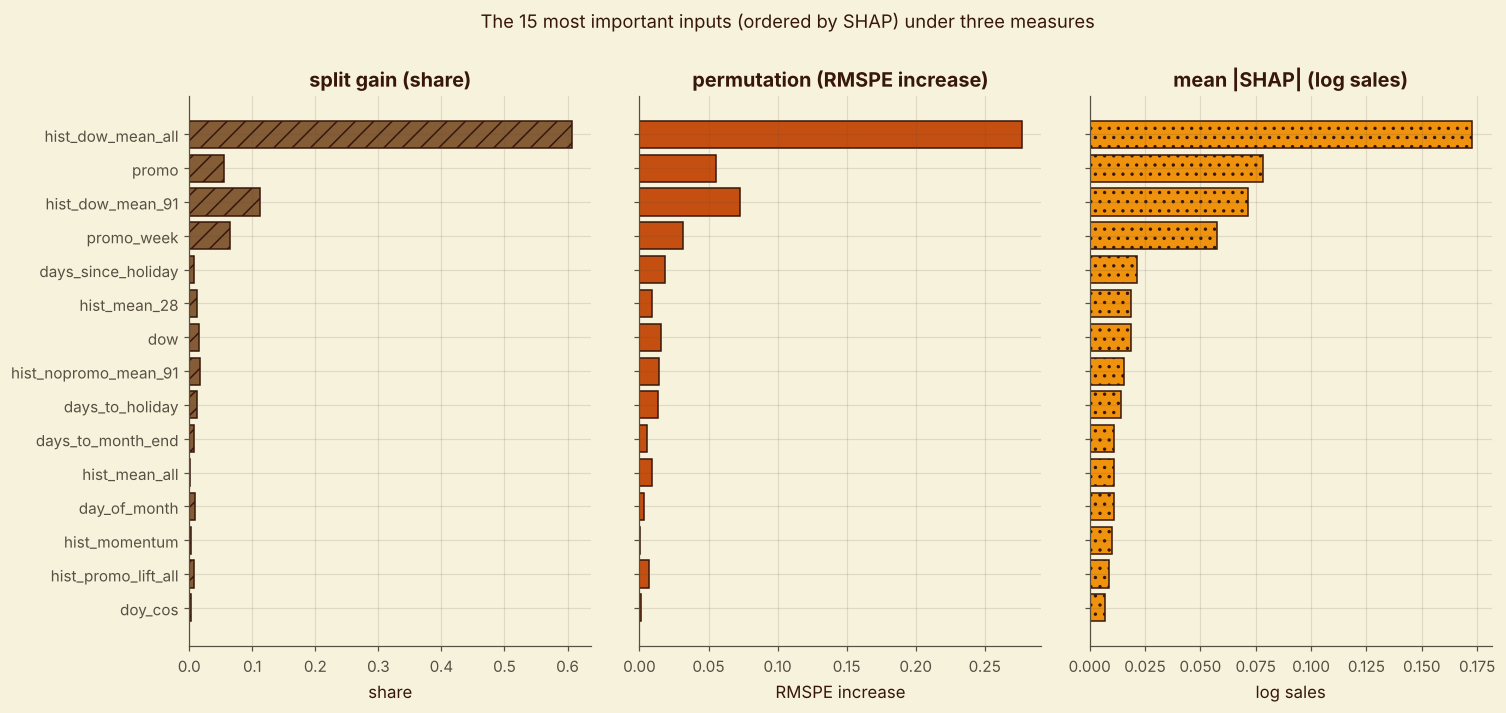

Figure 9.3: Importance by feature group


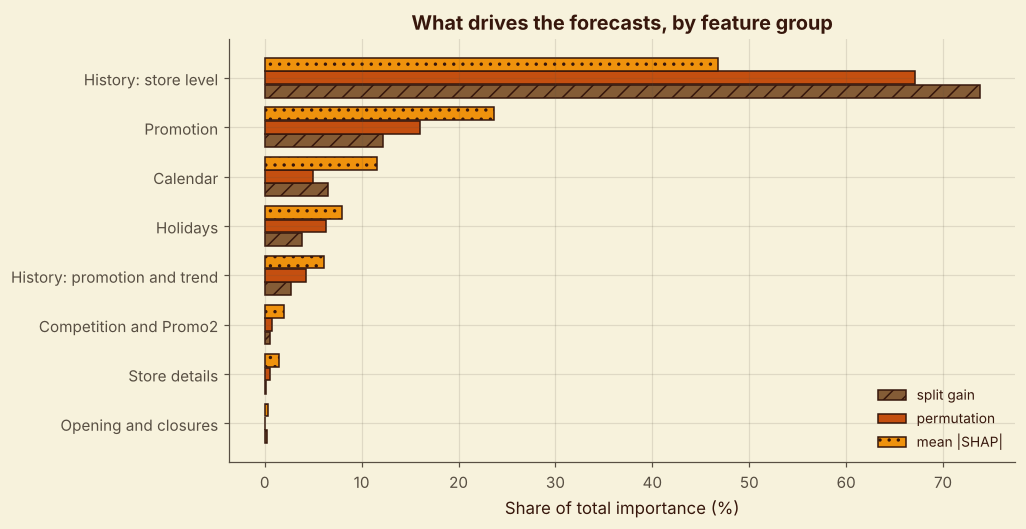

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6.5), sharey=True)
top = imp.head(15).index[::-1]
for ax, (col, colr, hatch) in zip(axes, [("split gain (share)", PALETTE["clay"], "//"), ("permutation (RMSPE increase)", PALETTE["terracotta"], ""),
                                        ("mean |SHAP| (log sales)", PALETTE["marigold"], "..")]):
    ax.barh(range(len(top)), imp.loc[top, col], color=colr, hatch=hatch, edgecolor=PALETTE["espresso"])
    ax.set_title(col)
    ax.set_xlabel(col.split("(")[1].rstrip(")") if "(" in col else "")
axes[0].set_yticks(range(len(top)))
axes[0].set_yticklabels(top)
fig.suptitle("The 15 most important inputs (ordered by SHAP) under three measures", y=1.0)
fig.subplots_adjust(left=0.16, wspace=0.12)
style.save_figure(fig, 9, "Feature importance under three measures")
plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
g = groups.iloc[::-1]
yy = np.arange(len(g))
for j, (col, colr, hatch) in enumerate([("split gain (share)", PALETTE["clay"], "//"), ("permutation (RMSPE increase)", PALETTE["terracotta"], ""),
                                         ("mean |SHAP| (log sales)", PALETTE["marigold"], "..")]):
    ax.barh(yy + (j - 1) * 0.27, 100 * g[col], height=0.26, color=colr, hatch=hatch, edgecolor=PALETTE["espresso"], label=col.split(" (")[0])
ax.set_yticks(yy)
ax.set_yticklabels(g.index)
ax.set_xlabel("Share of total importance (%)")
ax.set_title("What drives the forecasts, by feature group")
ax.legend(fontsize=9)
fig.subplots_adjust(left=0.25)
style.save_figure(fig, 9, "Importance by feature group")
plt.show()

**Four forecasts explained.** Four store-days from rolling window 3 are picked by rule (not by hand): a promotion Monday and a non-promotion Saturday of the same typical store, a store whose competitor opened in the last six months, and the day before a state holiday. For each, the five largest SHAP contributions are turned into percentage effects (`exp(SHAP) - 1`) and into a sentence.

In [27]:
v3x = v3_rows.reset_index(drop=True)
typical = int(v3x.groupby("Store")["hist_mean_all"].first().sub(v3x["hist_mean_all"].median()).abs().idxmin())
cases = {}
c1 = v3x[(v3x["Store"] == typical) & (v3x["dow"] == 1) & (v3x["promo"] == 1) & (v3x["state_holiday"] == "0")]
c2 = v3x[(v3x["Store"] == typical) & (v3x["dow"] == 6) & (v3x["promo"] == 0)]
c3 = v3x[v3x["comp_opened_last_6m"] == 1]
c4 = v3x[(v3x["days_to_holiday"] == 1) & (v3x["dow"] <= 5)]
for label, d in [(f"Store {typical}: promotion Monday", c1), (f"Store {typical}: Saturday without promotion", c2),
                 ("A store whose competitor opened in the last 6 months", c3), ("The day before a state holiday", c4)]:
    if len(d):
        cases[label] = d.iloc[0]
case_X = pd.DataFrame(list(cases.values()))
case_shap, _ = X.shap_values(gb3, case_X, FINAL_FEATURES)
case_pred = gb3.predict(case_X[FINAL_FEATURES])

DESCRIPTION = F.FEATURE_TABLE.set_index("feature")["description"]


def fmt_value(v):
    return f"{v:,.0f}" if isinstance(v, (int, float, np.floating, np.integer)) and abs(v) >= 100 else (f"{v:.2f}" if isinstance(v, (float, np.floating)) else str(v))


def plain(f):
    return DESCRIPTION[f][0].lower() + DESCRIPTION[f][1:]


explain_rows, sentences = [], []
for (label, r), (_, sv), p in zip(cases.items(), case_shap.iterrows(), case_pred):
    top5 = sv.reindex(sv.abs().sort_values(ascending=False).index[:5])
    parts = [f"{f} = {fmt_value(r[f])} ({100 * np.expm1(v):+.0f}%)" for f, v in top5.items()]
    explain_rows.append({"case": label, "store": int(r["Store"]), "date": pd.Timestamp(r["Date"]).date(), "forecast": round(float(p)),
                         "actual": int(r["Sales"]), "error (%)": round(100 * (p / r["Sales"] - 1), 1), "five largest effects": "; ".join(parts)})
    up = [f for f, v in top5.items() if v > 0][:2]
    down = [f for f, v in top5.items() if v < 0][:2]
    sentences.append(f"- **{label}** (store {int(r['Store'])}, {pd.Timestamp(r['Date']).strftime('%a %d %b %Y')}): forecast {p:,.0f}, actual {int(r['Sales']):,}. "
                     f"Pushed up mainly by {'; '.join(plain(f) for f in up) if up else 'nothing large'}. "
                     f"Pulled down mainly by {'; '.join(plain(f) for f in down) if down else 'nothing large'}.")
style.show_table(pd.DataFrame(explain_rows).set_index("case"), 9, "Four forecasts explained by their largest SHAP effects")
display(Markdown("\n".join(sentences)))

**Table 9.8: Four forecasts explained by their largest SHAP effects**

,store,date,forecast,actual,error (%),five largest effects
case,,,,,,
Store 692: promotion Monday,692,2015-05-18,10428,9766,6.8,"hist_dow_mean_all = 8,663 (+18%); promo = 1 (+12%); promo_week = 1 (+9%); hist_dow_mean_91 = 8,318 (+8%); hist_promo_lift_all = 1.56 (+2%)"
Store 692: Saturday without promotion,692,2015-05-09,4044,4673,-13.5,"hist_dow_mean_all = 4,063 (-26%); hist_dow_mean_91 = 3,926 (-14%); promo = 0 (-7%); promo_week = 1 (+3%); dow = 6 (+3%)"
A store whose competitor opened in the last 6 months,5,2015-05-09,2244,2354,-4.7,"hist_dow_mean_all = 2,075 (-48%); hist_dow_mean_91 = 2,156 (-29%); promo = 0 (-5%); hist_mean_28 = 4,910 (-3%); promo_week = 1 (+2%)"
The day before a state holiday,1,2015-05-13,4380,3998,9.6,"hist_dow_mean_all = 4,581 (-16%); days_to_holiday = 1 (+13%); promo = 0 (-7%); hist_dow_mean_91 = 4,469 (-7%); hist_nopromo_mean_91 = 3,744 (-6%)"


- **Store 692: promotion Monday** (store 692, Mon 18 May 2015): forecast 10,428, actual 9,766. Pushed up mainly by store's average sales on this weekday, all history to the origin; promotion on this day. Pulled down mainly by nothing large.
- **Store 692: Saturday without promotion** (store 692, Sat 09 May 2015): forecast 4,044, actual 4,673. Pushed up mainly by any promotion this calendar week; weekday number (1 = Monday). Pulled down mainly by store's average sales on this weekday, all history to the origin; store's average sales on this weekday, last 91 days.
- **A store whose competitor opened in the last 6 months** (store 5, Sat 09 May 2015): forecast 2,244, actual 2,354. Pushed up mainly by any promotion this calendar week. Pulled down mainly by store's average sales on this weekday, all history to the origin; store's average sales on this weekday, last 91 days.
- **The day before a state holiday** (store 1, Wed 13 May 2015): forecast 4,380, actual 3,998. Pushed up mainly by days to the next national holiday (capped at 30). Pulled down mainly by store's average sales on this weekday, all history to the origin; promotion on this day.

**Reading the result.** The explanations read like a manager's reasoning. For store 692's promotion Monday (forecast 10,428, actual 9,766), the store's strong Monday history and the promotion push the forecast up. For its Saturday without a promotion, the low Saturday level pulls it down, and the forecast is 13.5% too low. That fits Table 8.22: Saturdays are among the hardest days. For the day before a state holiday, the closeness of the holiday adds to the forecast (+9.6% too high on this occasion).

## 9.3 Prediction Intervals (90%)

**Question.** How wide is the honest range around each forecast, and does a "90%" range really contain the actual value 90% of the time?

**Method: split-conformal calibration.** For forecasts the model never trained on, compute the log error r = log(1 + actual) - log(1 + forecast). The 5th and 95th percentiles of r (with the finite-sample correction of split conformal prediction) give the lower and upper bounds: interval = forecast x exp(q_low) to forecast x exp(q_high). Errors grow with the forecast week, so the bounds are computed **per forecast week**; a second variant also splits by **store size** (quartile of the store's historical average). Days 43 to 48 (beyond the 42-day calibration windows) use week 6's bounds.

**Honest test.** Calibrate on rolling windows 1 and 2, then measure coverage on rolling window 3 and on the seasonal check. Comparison method: **quantile regression** (gradient boosting with the quantile loss at 5% and 95%, trained on 150,000 rows of each test split's own training period). The method chosen is then recalibrated on all three rolling windows for the app; its coverage on the final holdout is measured once in Section 10.2. Target: empirical coverage within 90% +/- 5 points.

In [28]:
%%writefile src/intervals.py
"""Prediction intervals by split conformal calibration on out-of-sample forecast errors.

Errors are measured on the log scale, r = log(1 + actual) - log(1 + forecast), so an interval is a percentage band
around the forecast. For each group (by default the forecast week), the lower and upper bounds are empirical
quantiles of r with the finite-sample correction of split conformal prediction. Calibration errors come from the
rolling validation windows only (never the final holdout).
"""
import numpy as np
import pandas as pd


def week_ahead(horizon_day):
    return ((np.asarray(horizon_day) - 1) // 7 + 1).clip(max=7)


class ConformalIntervals:
    def __init__(self, level=0.90, group_cols=("week_ahead",), min_group_size=200):
        self.level, self.group_cols, self.min_group_size = level, list(group_cols), min_group_size

    @staticmethod
    def _quantile(r, q):
        n = len(r)
        return float(np.quantile(r, min(1.0, max(0.0, np.ceil((n + 1) * q) / n if q > 0.5 else np.floor((n + 1) * q) / n)),
                                 method="higher" if q > 0.5 else "lower"))

    def fit(self, actual, forecast, groups):
        r = np.log1p(np.asarray(actual, float)) - np.log1p(np.asarray(forecast, float))
        a = 1 - self.level
        g = pd.DataFrame(groups)[self.group_cols].reset_index(drop=True).assign(r=r)
        self.overall_ = (self._quantile(r, a / 2), self._quantile(r, 1 - a / 2), len(r))
        rows = []
        for key, d in g.groupby(self.group_cols):
            key = key if isinstance(key, tuple) else (key,)
            if len(d) >= self.min_group_size:
                rows.append((*key, self._quantile(d["r"].values, a / 2), self._quantile(d["r"].values, 1 - a / 2), len(d)))
        self.table_ = pd.DataFrame(rows, columns=self.group_cols + ["q_low", "q_high", "n"])
        return self

    def bounds(self, groups):
        g = pd.DataFrame(groups)[self.group_cols].reset_index(drop=True).copy()
        if "week_ahead" in self.group_cols:
            # days beyond the calibrated horizon (days 43 to 48 when calibrated on 42-day windows) use the last calibrated week
            g["week_ahead"] = g["week_ahead"].clip(upper=int(self.table_["week_ahead"].max()))
        m = g.merge(self.table_, on=self.group_cols, how="left")
        return m["q_low"].fillna(self.overall_[0]).values, m["q_high"].fillna(self.overall_[1]).values

    def to_frame(self):
        """The calibration table (saved for the app)."""
        return self.table_.assign(level=self.level)

    def predict(self, forecast, groups):
        lo, hi = self.bounds(groups)
        f = np.log1p(np.asarray(forecast, float))
        return np.maximum(np.expm1(f + lo), 0.0), np.expm1(f + hi)


def coverage(actual, lower, upper):
    y = np.asarray(actual, float)
    inside = (y >= lower) & (y <= upper)
    return {"coverage_pct": float(100 * inside.mean()), "mean_width_pct": float(100 * np.mean((upper - lower) / np.maximum(y, 1))),
            "below_pct": float(100 * np.mean(y < lower)), "above_pct": float(100 * np.mean(y > upper))}

Writing src/intervals.py


In [29]:
from src import intervals as I
importlib.reload(I)

size_edges = np.quantile(pd.concat([valid_rows[n] for n in ROLLING]).groupby("Store")["hist_mean_all"].first(), [0.25, 0.5, 0.75])
SIZE_LABELS = ["smallest 25%", "lower middle", "upper middle", "largest 25%"]


def interval_groups(rows):
    return pd.DataFrame({"week_ahead": I.week_ahead(rows["horizon_day"]),
                         "store_size": pd.Categorical.from_codes(np.searchsorted(size_edges, rows["hist_mean_all"].values), SIZE_LABELS).astype(str)})


calib = pd.concat([valid_rows["rolling_1"], valid_rows["rolling_2"]], ignore_index=True)
methods = {"conformal by forecast week": I.ConformalIntervals(0.90, ["week_ahead"]),
           "conformal by forecast week and store size": I.ConformalIntervals(0.90, ["week_ahead", "store_size"])}
for m in methods.values():
    m.fit(calib["Sales"], calib["gb"], interval_groups(calib))

# (slow: about 5 minutes) quantile regression for the two test splits
QR_ROWS = 150_000
for name in ["rolling_3", "seasonal_check"]:
    train, valid = M.window_data(dataset, splits, name, train_sample=QR_ROWS)
    for q, col in [(0.05, "qr_low"), (0.95, "qr_high")]:
        qm = M.make_model(FINALIST, FINAL_FEATURES, log_target=True, **{**FINAL_PARAMS, "loss": "quantile", "quantile": q})
        qm.fit(train[FINAL_FEATURES], train["Sales"])
        valid_rows[name][col] = qm.predict(valid[FINAL_FEATURES])
    del train, valid, qm
    gc.collect()

cov_rows = []
for name in ["rolling_3", "seasonal_check"]:
    v = valid_rows[name]
    gg = interval_groups(v)
    for label, m in methods.items():
        lo, hi = m.predict(v["gb"], gg)
        v[f"lo_{label}"], v[f"hi_{label}"] = lo, hi
        cov_rows.append({"window": name, "method": label, **I.coverage(v["Sales"], lo, hi)})
    cov_rows.append({"window": name, "method": "quantile regression (5% and 95%)", **I.coverage(v["Sales"], v["qr_low"], v["qr_high"])})
coverage_tab = pd.DataFrame(cov_rows).set_index(["window", "method"])
style.show_table(coverage_tab.round(2), 9, "Coverage of nominal 90% intervals on data not used for calibration")

v3c = valid_rows["rolling_3"].assign(week=I.week_ahead(valid_rows["rolling_3"]["horizon_day"]), size=interval_groups(valid_rows["rolling_3"])["store_size"].values)
by_week = pd.DataFrame({label: v3c.groupby("week").apply(lambda d: I.coverage(d["Sales"], d[f"lo_{label}"], d[f"hi_{label}"])["coverage_pct"])
                        for label in methods})
by_week["quantile regression"] = v3c.groupby("week").apply(lambda d: I.coverage(d["Sales"], d["qr_low"], d["qr_high"])["coverage_pct"])
by_size = pd.DataFrame({label: v3c.groupby("size").apply(lambda d: I.coverage(d["Sales"], d[f"lo_{label}"], d[f"hi_{label}"])["coverage_pct"])
                        for label in methods}).reindex(SIZE_LABELS)
by_size["quantile regression"] = v3c.groupby("size").apply(lambda d: I.coverage(d["Sales"], d["qr_low"], d["qr_high"])["coverage_pct"]).reindex(SIZE_LABELS)
style.show_table(by_week.round(1), 9, "Coverage (%) by forecast week, rolling window 3")
style.show_table(by_size.round(1), 9, "Coverage (%) by store size, rolling window 3")

**Table 9.9: Coverage of nominal 90% intervals on data not used for calibration**

coverage_pct  mean_width_pct  below_pct  above_pct
window         method                                                                                       
rolling_3      conformal by forecast week                        90.46           33.85       5.24       4.31
               conformal by forecast week and store size         90.30           33.85       5.21       4.49
               quantile regression (5% and 95%)                  82.75           28.29       5.65      11.61
seasonal_check conformal by forecast week                        90.04           34.50       5.41       4.56
               conformal by forecast week and store size         89.96           34.55       5.40       4.64
               quantile regression (5% and 95%)                  84.70           28.46       5.80       9.51

**Table 9.10: Coverage (%) by forecast week, rolling window 3**

,conformal by forecast week,conformal by forecast week and store size,quantile regression
week,,,
1,94.6,94.5,81.1
2,92.3,92.5,84.0
3,89.6,88.8,83.6
4,82.5,82.0,76.0
5,88.9,88.7,84.6
6,94.6,94.8,86.3


**Table 9.11: Coverage (%) by store size, rolling window 3**

,conformal by forecast week,conformal by forecast week and store size,quantile regression
size,,,
smallest 25%,87.8,90.2,82.3
lower middle,90.5,90.5,83.6
upper middle,91.5,90.3,83.9
largest 25%,91.9,90.2,81.2


'Table 9.11'

**Reading the result.** Calibrated on rolling windows 1 and 2 only, both conformal methods give almost exactly the nominal coverage on unseen data: 90.5% / 90.3% on rolling window 3 and 90.0% / 90.0% on the seasonal check. The average width is about 34% of the actual value. Quantile regression is narrower but **under-covers** (82.8% and 84.7%), with too many actual values above its upper bound (11.6%). Coverage varies by forecast week, from 82.5% in week 4 to 94.6% in weeks 1 and 6, because calibration pools two windows with different holiday timing. By store size, the week-only method under-covers the smallest stores (87.8%). Adding store size fixes this (90.2% to 90.5% in every size group).

**Table 9.12: Choosing the interval method (rolling window 3)**

,coverage_pct,mean_width_pct,below_pct,above_pct,overall: distance from 90,worst store-size group: distance from 90,score (larger gap)
method,,,,,,,
conformal by forecast week,90.46,33.85,5.24,4.31,0.46,2.18,2.18
conformal by forecast week and store size,90.30,33.85,5.21,4.49,0.30,0.53,0.53
quantile regression (5% and 95%),82.75,28.29,5.65,11.61,7.25,8.77,8.77


Interval method chosen: conformal by forecast week and store size


**Table 9.13: Customer intervals: coverage of nominal 90% on data not used for calibration**

,coverage_pct,mean_width_pct,below_pct,above_pct
window,,,,
rolling_3,89.76,27.19,5.43,4.81
seasonal_check,88.34,27.32,6.02,5.64


**Table 9.14: Sales interval around the forecast, by forecast week and store size (saved for the app)**

store_size,smallest 25%,lower middle,upper middle,largest 25%
week_ahead,,,,
1,-17% to +24%,-15% to +22%,-15% to +23%,-14% to +24%
2,-16% to +20%,-14% to +18%,-13% to +18%,-13% to +17%
3,-14% to +20%,-14% to +18%,-14% to +17%,-13% to +17%
4,-12% to +23%,-12% to +21%,-11% to +22%,-10% to +21%
5,-13% to +20%,-12% to +19%,-11% to +18%,-10% to +19%
6,-13% to +25%,-12% to +24%,-12% to +24%,-11% to +23%


Figure 9.4: Prediction intervals and their coverage


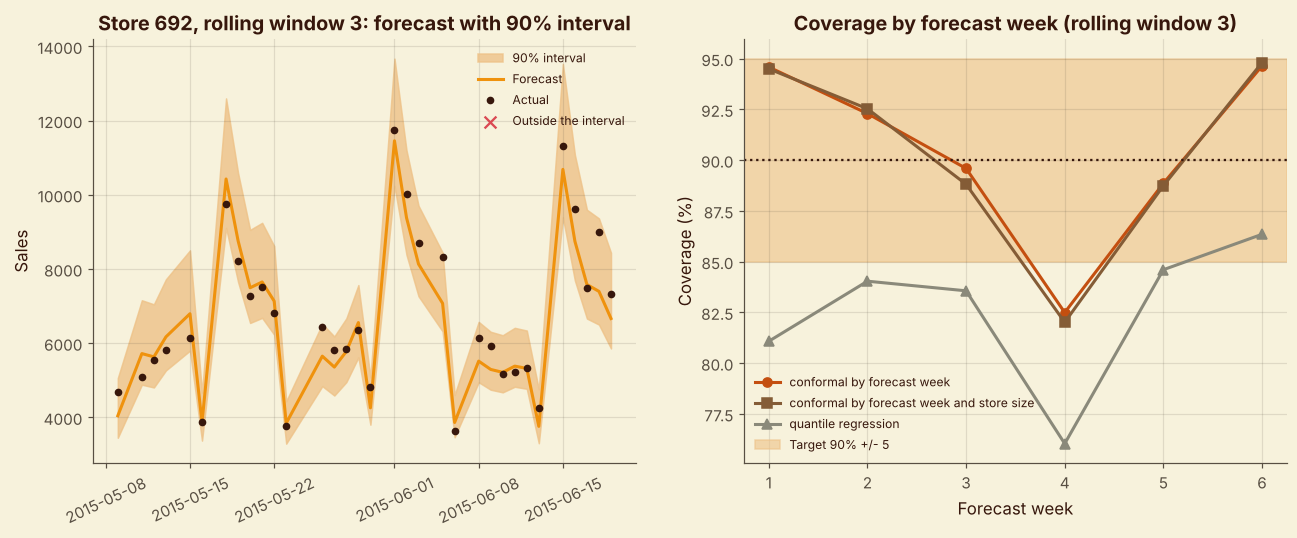

In [30]:
# choose the interval method on rolling window 3 (the seasonal check is reported, never used for the choice)
# rule: an interval should be calibrated overall AND for every store size, so the score is the larger of the two gaps
r3 = coverage_tab.loc["rolling_3"].copy()
r3["overall: distance from 90"] = (r3["coverage_pct"] - 90).abs()
size_gap = by_size.sub(90).abs().max().rename({"quantile regression": "quantile regression (5% and 95%)"})
r3["worst store-size group: distance from 90"] = size_gap.reindex(r3.index).values
r3["score (larger gap)"] = r3[["overall: distance from 90", "worst store-size group: distance from 90"]].max(axis=1)
style.show_table(r3.round(2), 9, "Choosing the interval method (rolling window 3)")
INTERVAL_METHOD = r3["score (larger gap)"].idxmin()
print("Interval method chosen:", INTERVAL_METHOD)
if INTERVAL_METHOD.startswith("quantile"):
    raise NotImplementedError("Quantile regression was chosen: package the two quantile models instead of a calibration table")

all_roll = pd.concat([valid_rows[n] for n in ROLLING], ignore_index=True)
final_intervals = I.ConformalIntervals(0.90, methods[INTERVAL_METHOD].group_cols).fit(all_roll["Sales"], all_roll["gb"], interval_groups(all_roll))
cust_intervals = I.ConformalIntervals(0.90, methods[INTERVAL_METHOD].group_cols).fit(all_roll["Customers"], all_roll["cust_gb"], interval_groups(all_roll))

# customer intervals: same honest test (calibrate on rolling 1 and 2, test on rolling 3 and the seasonal check)
cust_test = I.ConformalIntervals(0.90, methods[INTERVAL_METHOD].group_cols).fit(calib["Customers"], calib["cust_gb"], interval_groups(calib))
cust_cov = pd.DataFrame([{"window": n, **I.coverage(valid_rows[n]["Customers"], *cust_test.predict(valid_rows[n]["cust_gb"], interval_groups(valid_rows[n])))}
                         for n in ["rolling_3", "seasonal_check"]]).set_index("window")
style.show_table(cust_cov.round(2), 9, "Customer intervals: coverage of nominal 90% on data not used for calibration")

calibration_table = pd.concat([final_intervals.to_frame().assign(target="Sales"), cust_intervals.to_frame().assign(target="Customers")], ignore_index=True)
calibration_table["size_edges"] = json.dumps([float(x) for x in size_edges])
calibration_table.to_csv(OUTPUT_DIR / "interval_calibration.csv", index=False)
show_cal = calibration_table[calibration_table["target"] == "Sales"].assign(
    band=lambda d: [f"{100 * np.expm1(lo):+.0f}% to {100 * np.expm1(hi):+.0f}%" for lo, hi in zip(d["q_low"], d["q_high"])])
show_cal = show_cal.pivot(index="week_ahead", columns="store_size", values="band")[SIZE_LABELS] if "store_size" in show_cal else show_cal.set_index("week_ahead")[["band"]]
style.show_table(show_cal, 9, "Sales interval around the forecast, by forecast week and store size (saved for the app)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
st_ = valid_rows["rolling_3"]
example_store = typical
d = st_[st_["Store"] == example_store].sort_values("Date")
lo_c, hi_c = f"lo_{INTERVAL_METHOD}", f"hi_{INTERVAL_METHOD}"
axes[0].fill_between(d["Date"], d[lo_c], d[hi_c], color=FORECAST_COLORS["interval"], alpha=0.8, label="90% interval")
axes[0].plot(d["Date"], d["gb"], color=FORECAST_COLORS["forecast"], linewidth=2, label="Forecast")
axes[0].plot(d["Date"], d["Sales"], color=FORECAST_COLORS["actual"], linewidth=0, marker="o", markersize=4, label="Actual")
out = (d["Sales"] < d[lo_c]) | (d["Sales"] > d[hi_c])
axes[0].scatter(d.loc[out, "Date"], d.loc[out, "Sales"], marker="x", s=60, color=FORECAST_COLORS["error"], zorder=4, label="Outside the interval")
axes[0].set_title(f"Store {example_store}, rolling window 3: forecast with 90% interval")
axes[0].set_ylabel("Sales")
axes[0].tick_params(axis="x", rotation=25)
axes[0].legend(fontsize=8)
for col, mk, colr in [("conformal by forecast week", "o", PALETTE["terracotta"]), ("conformal by forecast week and store size", "s", PALETTE["clay"]),
                      ("quantile regression", "^", PALETTE["stone"])]:
    axes[1].plot(by_week.index.values, by_week[col], marker=mk, color=colr, linewidth=2, label=col)
axes[1].axhspan(85, 95, color=PALETTE["sand"], alpha=0.6, label="Target 90% +/- 5")
axes[1].axhline(90, color=PALETTE["espresso"], linestyle=":")
axes[1].set_xlabel("Forecast week")
axes[1].set_ylabel("Coverage (%)")
axes[1].set_title("Coverage by forecast week (rolling window 3)")
axes[1].legend(fontsize=8)
style.save_figure(fig, 9, "Prediction intervals and their coverage")
plt.show()

**Reading the result.** The chosen method is **conformal by forecast week and store size**: its worst store-size group is within 0.53 points of 90%, against 2.18 for the week-only method. Customer intervals built the same way cover 89.8% (rolling 3) and 88.3% (seasonal check). For the app, the calibration is redone on all three rolling windows. A typical sales range is about -13% to +20% around the forecast, wider in week 1 and week 6 and for the smallest stores.

## 9.4 Section 9 Wrap-Up

In [31]:
cust_wins = bool((cust_pivot.loc["Customer model", ALL_WINDOWS] < cust_pivot.loc["Customer baseline", ALL_WINDOWS]).all())
r3_cov = float(coverage_tab.loc[("rolling_3", INTERVAL_METHOD), "coverage_pct"])
seas_cov = float(coverage_tab.loc[("seasonal_check", INTERVAL_METHOD), "coverage_pct"])
top_group = groups.index[0]
c9 = pd.DataFrame([
    ("The customer model beats the customer baseline in every window", cust_wins),
    ("Customers is never an input (feature policy check on the customer features)", bool(validation.check_features(FINAL_FEATURES))),
    ("Three importance measures computed on the same 59 inputs", bool(imp[["split gain (share)", "permutation (RMSPE increase)", "mean |SHAP| (log sales)"]].notna().all().all())),
    ("Interval calibration uses rolling-window rows only (all before the holdout)", bool(all_roll["Date"].max() < SPLIT.loc["holdout", "valid_start"])),
    (f"Chosen interval method covers 90% +/- 5 on rolling window 3 ({r3_cov:.1f}%)", abs(r3_cov - 90) <= 5),
    ("Calibration table saved for the app (outputs/interval_calibration.csv)", (OUTPUT_DIR / "interval_calibration.csv").exists()),
    ("rossmann-customers is in the MLflow registry", len(client.search_model_versions("name='rossmann-customers'")) >= 1),
    ("No holdout evaluation before Section 10", int((evaluation_log["section"].astype(str) != "10").sum()) == 0),
], columns=["check", "passed"]).set_index("check")
style.show_table(c9, 9, "Section 9 completion checks", save=False)

log_decision(9, f"Customers are forecast by a separate gradient-boosting pipeline on the same {len(FINAL_FEATURES)} features ({cust_tune.index[0]}); target log1p(Customers).",
             f"Average rolling RMSPE {cust_pivot.loc['Customer model', 'rolling average']:.4f} against {cust_pivot.loc['Customer baseline', 'rolling average']:.4f} for the customer baseline.")
log_decision(9, f"Explanations use three measures (split gain, time-aware permutation, SHAP); the largest feature group by SHAP is '{top_group}' ({100 * groups.loc[top_group, 'mean |SHAP| (log sales)']:.0f}%).",
             "Different measures answer different questions; agreement between them is reported, not assumed.")
log_decision(9, f"Prediction intervals: {INTERVAL_METHOD}, nominal 90%, calibrated on all three rolling windows for the app; days 43 to 48 use week 6.",
             f"Calibrated on rolling 1 and 2 it covered {r3_cov:.1f}% on rolling 3 and {seas_cov:.1f}% on the seasonal check; chosen because it is closest to 90% both overall and in its worst store-size group (quantile regression covered only {coverage_tab.loc[('rolling_3', 'quantile regression (5% and 95%)'), 'coverage_pct']:.1f}%).")
log_limitation(9, "Intervals are calibrated on forecasts of 400,000-row models, while the production model is trained on all history.",
               "The production model is slightly more accurate, so its intervals are, if anything, slightly too wide; holdout coverage (10.2) is the check.")
log_limitation(9, f"Interval coverage depends on the window: {r3_cov:.1f}% on rolling window 3 but {seas_cov:.1f}% on the summer seasonal check.",
               "Coverage in the summer test window may differ from the spring windows used for calibration.")
log_limitation(9, "Importance measures show association inside the model, not cause: correlated inputs (for example several history averages) share or swap importance.",
               "Single-feature rankings should be read at the level of feature groups.")
save_registers()
style.save_index()
sh("git add -A")
sh('git commit -m "Section 9: customers, explainability and prediction intervals"', check=False, quiet=True)
display(decision_register.tail(3))

2026-11-03 12:20:57 | INFO     | rossmann.validation | Feature policy check passed for 59 features.


**Table 9.15: Section 9 completion checks**

,passed
check,
The customer model beats the customer baseline in every window,True
Customers is never an input (feature policy check on the customer features),True
Three importance measures computed on the same 59 inputs,True
Interval calibration uses rolling-window rows only (all before the holdout),True
Chosen interval method covers 90% +/- 5 on rolling window 3 (90.3%),True
Calibration table saved for the app (outputs/interval_calibration.csv),True
rossmann-customers is in the MLflow registry,True
No holdout evaluation before Section 10,True


,id,section,decision,reason,status
68,D69,9,Customers are forecast by a separate gradient-boosting pipeline on the same 59 features (faster learning (rate 0.1)); target log1p(Customers).,Average rolling RMSPE 0.1088 against 0.1480 for the customer baseline.,Confirmed
69,D70,9,"Explanations use three measures (split gain, time-aware permutation, SHAP); the largest feature group by SHAP is 'History: store level' (47%).","Different measures answer different questions; agreement between them is reported, not assumed.",Confirmed
70,D71,9,"Prediction intervals: conformal by forecast week and store size, nominal 90%, calibrated on all three rolling windows for the app; days 43 to 48 use week 6.",Calibrated on rolling 1 and 2 it covered 90.3% on rolling 3 and 90.0% on the seasonal check; chosen because it is closest to 90% both overall and in its worst store-size group (quantile regression...,Confirmed


## 9.4 Section 9 Summary
- **Customers:** a separate pipeline on the same 59 features. Average rolling RMSPE 0.109 against 0.148 for the baseline, and it wins every window.
- **Drivers:** the store's weekday history level, promotions, calendar and holidays, in that order. The three importance measures agree on the top inputs.
- **Uncertainty:** split-conformal 90% intervals by forecast week and store size, with 90.3% coverage on unseen spring data and 90.0% on the summer check. Quantile regression under-covers (83%).
- All Section 9 completion checks pass. The holdout is still untouched.

---

# Section 10: Final Evaluation and Packaging

| Step | What it covers |
|---|---|
| 10.1 | Freeze the configuration; build the final training table through 31 Jul 2015 |
| 10.2 | Score the final holdout **once** (20 Jun to 31 Jul 2015) |
| 10.3 | Refit on all labelled history; timestamped model bundle; MLflow registry and MLflow inference on the test data; DVC version 4 |
| 10.4 | Test predictions and the submission file |

## 10.1 Freeze

**Rule.** After this cell nothing about the model changes: not the features, not the settings, not the interval method. The configuration is written to the Decision Register with a fingerprint (a hash of the configuration). Section 10.2 refuses to run if the holdout was already scored with a *different* fingerprint, so a later change cannot be quietly re-tested on the holdout. Re-running the notebook with the same configuration reproduces the same numbers and does not add a second entry to the evaluation-access log.

In [32]:
import hashlib

FROZEN = {
    "production_model": production_model,
    "sales_model": {"kind": FINALIST, "params": FINAL_PARAMS, "target": "log1p(Sales), squared error"},
    "customers_model": {"kind": FINALIST, "params": CUSTOMER_PARAMS, "target": "log1p(Customers), squared error"},
    "features": FINAL_FEATURES,
    "interval": {"method": INTERVAL_METHOD, "groups": final_intervals.group_cols, "level": final_intervals.level,
                 "calibration": "rolling windows 1 to 3 (400,000-row models)"},
    "training_rows_final": "every open, positive-sales row of the origin-based table through 31 Jul 2015",
    "closed_days": "forecast as 0",
}
if FROZEN["production_model"] != "Gradient boosting":
    raise NotImplementedError("8.5 selected a challenger: package the LSTM before freezing")
FINGERPRINT = hashlib.sha256(json.dumps(FROZEN, sort_keys=True, default=str).encode()).hexdigest()[:12]
frozen_view = pd.Series({
    "Fingerprint": FINGERPRINT,
    "Sales model": f"gradient boosting, {', '.join(f'{k}={v}' for k, v in FINAL_PARAMS.items())}",
    "Customers model": f"gradient boosting, {', '.join(f'{k}={v}' for k, v in CUSTOMER_PARAMS.items())}",
    "Features": f"{len(FINAL_FEATURES)} (the 61 of Section 6 minus the two same-year-earlier features)",
    "Interval method": f"{INTERVAL_METHOD}, nominal 90%",
    "scikit-learn early stopping": "on by default above 10,000 rows (10% random rows, 10 rounds), exactly as in every Section 7 fit",
}, dtype=object).to_frame("frozen value")
style.show_table(frozen_view, 10, "The frozen configuration")
if not decision_register["decision"].str.contains(f"Frozen configuration {FINGERPRINT}").any():
    log_decision(10, f"Frozen configuration {FINGERPRINT}: production model = gradient boosting with the Section 7 settings and 59 features; customers model with {CUSTOMER_PARAMS}; intervals = {INTERVAL_METHOD} at 90%.",
                 "All choices were made on the rolling windows; nothing may change after the holdout is scored.")
save_registers()

# free what Sections 8 and 9 no longer need (the full-history fits below need about 2 GB of working memory)
import ctypes
for name in ["scaled_store", "scaled_chain", "store_pan", "chain_pan", "samples", "POOL", "store_models", "reloaded_lstm",
             "one_step_fc", "recursive_fc", "chain_results", "pan3", "v3_rows", "v3x", "perm_rows", "shap_rows", "roll", "seas", "pooled"]:
    globals().pop(name, None)
gc.collect()
try:
    ctypes.CDLL("libc.so.6").malloc_trim(0)          # return freed memory to the operating system (Linux only)
except OSError:
    pass

# (slow: about 3 minutes) the final training table: the same builder and origins as Section 6, now with targets through 31 Jul 2015
gap_end = F.find_gap_end(train_clean)
known = F.add_last_year_features(F.add_known_future_features(plan, gap_end), train_clean)    # as in Section 6 (the baselines read ly_* too)
validation_origins = [r.train_end for r in splits.itertuples() if r.split != "holdout"]
final_origins = F.origin_grid(train_clean["Date"].min(), dev_end, spacing=F.ORIGIN_SPACING_DAYS, extra=validation_origins)
t0 = time.time()
final_table = F.build_dataset(known, train_clean, final_origins, max_date=LAST_DAY)
print(f"Final table: {len(final_table):,} rows from {len(final_origins)} origins in {time.time() - t0:.0f} s")

del known, plan
gc.collect()

# consistency: on the development period, the final table must equal the Section 6 table (same builder, same origins),
# compared one origin at a time to keep memory low
check_cols = list(dict.fromkeys(FINAL_FEATURES + ["Sales", "Customers", "horizon_day"]))
dev_mask = final_table["Date"] <= dev_end
same_values = int(dev_mask.sum()) == len(dataset)
for o in final_origins:
    a = final_table.loc[dev_mask & (final_table["origin_date"] == o), ["Store", "Date"] + check_cols].sort_values(["Store", "Date"])
    b = dataset.loc[dataset["origin_date"] == o, ["Store", "Date"] + check_cols].sort_values(["Store", "Date"])
    same_values &= len(a) == len(b) and all(
        np.allclose(a[c].astype(float).values, b[c].astype(float).values, equal_nan=True) if a[c].dtype.kind in "fiub"
        else bool((a[c].astype(str).values == b[c].astype(str).values).all()) for c in check_cols)
    if not same_values:
        break
table_summary = pd.Series({
    "Rows (all origins)": f"{len(final_table):,}",
    "Rows used for training (open, positive sales)": f"{int(final_table['use_for_training'].sum()):,}",
    "Rows with a target inside the holdout (first time they enter a table)": f"{int((final_table['Date'] > dev_end).sum()):,}",
    "Latest target date": str(final_table["Date"].max().date()),
    "Development-period part identical to the Section 6 table": bool(same_values),
}, dtype=object).to_frame("value")
style.show_table(table_summary, 10, "The final training table")
assert same_values, "The final table disagrees with the Section 6 table on the development period"
del dataset, a, b
_ = gc.collect()

**Table 10.1: The frozen configuration**

,frozen value
Fingerprint,2a262976d01c
Sales model,"gradient boosting, max_iter=300, learning_rate=0.05, max_leaf_nodes=127, min_samples_leaf=20, l2_regularization=0.0"
Customers model,"gradient boosting, max_iter=300, learning_rate=0.1, max_leaf_nodes=127, min_samples_leaf=20, l2_regularization=0.0"
Features,59 (the 61 of Section 6 minus the two same-year-earlier features)
Interval method,"conformal by forecast week and store size, nominal 90%"
scikit-learn early stopping,"on by default above 10,000 rows (10% random rows, 10 rounds), exactly as in every Section 7 fit"


2026-11-03 12:21:02 | INFO     | rossmann.features | Known-future features built for 1,058,297 store-days.


2026-11-03 12:21:05 | INFO     | rossmann.features |   built 10 of 32 origins


2026-11-03 12:21:08 | INFO     | rossmann.features |   built 20 of 32 origins


2026-11-03 12:21:14 | INFO     | rossmann.features |   built 30 of 32 origins


Final table: 1,360,773 rows from 32 origins in 14 s


**Table 10.2: The final training table**

,value
Rows (all origins),"1,360,773"
"Rows used for training (open, positive sales)","1,360,683"
Rows with a target inside the holdout (first time they enter a table),"64,924"
Latest target date,2015-07-31
Development-period part identical to the Section 6 table,True


**Reading the result.** The configuration is frozen under fingerprint `2a262976d01c` and written to the Decision Register *before* the holdout is touched. The final table has 1,360,773 rows from the same 32 origins as Section 6. 64,924 rows have a holdout target and enter a table for the first time. Its development-period part is identical, value for value, to the Section 6 table, which proves that the same builder produced both.

## 10.2 The Final Holdout, Scored Once

**What is scored.** A model trained on the development period only (all labelled rows up to 19 Jun 2015, the Section 10.1 configuration) forecasts the 42 days from 20 Jun to 31 Jul 2015 from that single cut-off. This is exactly the situation of the real forecast: one origin, six weeks ahead, planned inputs known. The rows are the open, positive-sales store-days of all 1,115 stores, reported also for the 856 test-file stores. The best baseline is scored on the same rows. The 90% intervals use the calibration of Section 9.3 (rolling windows only), so their holdout coverage is an honest test.

The LSTM is not re-trained for the holdout: 8.5 did not select it, and the holdout is reserved for the model that goes forward.

In [33]:
# explicit, logged unlock of the holdout
_, holdout_mask = validation.get_masks(train_clean, splits, "holdout", allow_holdout=True)
previous = evaluation_log[evaluation_log["dataset"].astype(str).str.startswith("final holdout")]
if len(previous) and not previous["result_summary"].astype(str).str.contains(FINGERPRINT).any():
    raise PermissionError("The holdout was already scored with a different configuration. Restore the frozen configuration; do not re-test changes on the holdout.")
RERUN = len(previous) > 0

# (slow: about 15 minutes) development-period models: all labelled rows up to 19 Jun 2015
dev_train = final_table[(final_table["Date"] <= dev_end) & (final_table["use_for_training"] == 1)]
t0 = time.time()
sales_dev = M.make_model(FINALIST, FINAL_FEATURES, log_target=True, **FINAL_PARAMS).fit(dev_train[FINAL_FEATURES], dev_train["Sales"])
cust_dev = M.make_model(FINALIST, FINAL_FEATURES, log_target=True, **CUSTOMER_PARAMS).fit(dev_train[FINAL_FEATURES], dev_train["Customers"])
dev_fit_seconds = time.time() - t0
n_dev_train = len(dev_train)
del dev_train
gc.collect()
print(f"Development-period models fitted on {n_dev_train:,} rows in {dev_fit_seconds:.0f} s")

hold = final_table[(final_table["origin_date"] == dev_end) & (final_table["use_for_training"] == 1)].reset_index(drop=True)
assert hold["Date"].min() == SPLIT.loc["holdout", "valid_start"] and hold["Date"].max() == SPLIT.loc["holdout", "valid_end"]
assert set(zip(hold["Store"], hold["Date"])) == set(map(tuple, train_clean.loc[holdout_mask & (train_clean["use_for_training"] == 1), ["Store", "Date"]].values))
hold["gb"] = np.maximum(sales_dev.predict(hold[FINAL_FEATURES]), 0)
hold["cust_gb"] = np.maximum(cust_dev.predict(hold[FINAL_FEATURES]), 0)
base_h, _ = B.baseline_forecasts(hold, train_clean[train_clean["Date"] <= dev_end], dev_end)
hold["baseline"] = base_h[BEST_BASELINE].values
hold["cust_base"], _ = C.customer_baseline(hold, train_clean[train_clean["Date"] <= dev_end], dev_end)
hold["lo"], hold["hi"] = final_intervals.predict(hold["gb"], interval_groups(hold))
hold["c_lo"], hold["c_hi"] = cust_intervals.predict(hold["cust_gb"], interval_groups(hold))

h_rows = []
for col, label, target in [("baseline", "Best baseline", "Sales"), ("gb", "Gradient boosting (final configuration)", "Sales"),
                           ("cust_base", "Customer baseline", "Customers"), ("cust_gb", "Customer model", "Customers")]:
    h_rows.append({"target": target, "model": label, **E.metrics(hold[target], hold[col], hold["Store"], test_stores)})
holdout_scores = pd.DataFrame(h_rows).set_index(["target", "model"])
style.show_table(holdout_scores.round(4), 10, "Final holdout (20 Jun to 31 Jul 2015): accuracy")

hold_cov = pd.DataFrame([{"target": "Sales", **I.coverage(hold["Sales"], hold["lo"], hold["hi"])},
                         {"target": "Customers", **I.coverage(hold["Customers"], hold["c_lo"], hold["c_hi"])}]).set_index("target")
style.show_table(hold_cov.round(2), 10, "Final holdout: coverage of the 90% intervals")

hold_rmspe = float(holdout_scores.loc[("Sales", "Gradient boosting (final configuration)"), "rmspe"])
base_rmspe = float(holdout_scores.loc[("Sales", "Best baseline"), "rmspe"])
verdict10 = pd.Series({
    "Target": f"RMSPE at most {TARGET_ROLLING_RMSPE:.2f} and below the best baseline",
    "Gradient boosting on the holdout": f"{hold_rmspe:.4f}",
    "Best baseline on the holdout": f"{base_rmspe:.4f} (the model's error is {100 * (1 - hold_rmspe / base_rmspe):.0f}% lower)",
    "Verdict": "target met" if (hold_rmspe <= TARGET_ROLLING_RMSPE and hold_rmspe < base_rmspe) else "target missed",
    "Interval coverage (sales)": f"{hold_cov.loc['Sales', 'coverage_pct']:.1f}% ({'within' if abs(hold_cov.loc['Sales', 'coverage_pct'] - 90) <= 5 else 'outside'} 90 +/- 5)",
}, dtype=object).to_frame("result")
style.show_table(verdict10, 10, "Final holdout: verdict")

if not RERUN:
    log_evaluation(10, "final holdout 2015-06-20 to 2015-07-31", f"gradient boosting {FINGERPRINT}", "single final evaluation after freezing",
                   f"fingerprint {FINGERPRINT}; sales RMSPE {hold_rmspe:.4f} (baseline {base_rmspe:.4f}); customers RMSPE "
                   f"{holdout_scores.loc[('Customers', 'Customer model'), 'rmspe']:.4f}; sales interval coverage {hold_cov.loc['Sales', 'coverage_pct']:.1f}%")
    save_registers()
else:
    print("Re-run of the frozen configuration: the evaluation-access log already holds this evaluation; no new entry added.")
display(evaluation_log)

Development-period models fitted on 1,295,759 rows in 329 s


**Table 10.3: Final holdout (20 Jun to 31 Jul 2015): accuracy**

rmspe       mae       rmse  bias_pct  within_10pct  rmspe_test_stores
target    model                                                                                                          
Sales     Best baseline                            0.1468  744.0185  1108.6399    0.3172       57.1322             0.1487
          Gradient boosting (final configuration)  0.1068  537.0852   793.5656    0.4458       70.6320             0.1086
Customers Customer baseline                        0.1335   69.3756   103.6424    4.1742       62.8618             0.1340
          Customer model                           0.0877   46.6346    68.6906    0.3362       79.2836             0.0880

**Table 10.4: Final holdout: coverage of the 90% intervals**

,coverage_pct,mean_width_pct,below_pct,above_pct
target,,,,
Sales,88.38,33.81,8.13,3.49
Customers,89.21,27.24,6.74,4.04


**Table 10.5: Final holdout: verdict**

,result
Target,RMSPE at most 0.13 and below the best baseline
Gradient boosting on the holdout,0.1068
Best baseline on the holdout,0.1468 (the model's error is 27% lower)
Verdict,target met
Interval coverage (sales),88.4% (within 90 +/- 5)


,timestamp,section,dataset,model,purpose,result_summary
0,2026-11-03 12:26:53,10,final holdout 2015-06-20 to 2015-07-31,gradient boosting 2a262976d01c,single final evaluation after freezing,fingerprint 2a262976d01c; sales RMSPE 0.1068 (baseline 0.1468); customers RMSPE 0.0877; sales interval coverage 88.4%


**Reading the result (scored once).**
- **Sales:** the production configuration, trained on the development period only, scores **RMSPE 0.1068** on the 42-day holdout, against 0.1468 for the best baseline (the baseline's error is 37% higher). On the 856 test-file stores it scores 0.1086. **The success target (at most 0.13 and below the baseline) is met.** The result is consistent with the rolling windows (0.1106 and 0.1025 in rolling 2 and 3), which suggests the model selection did not overfit the validation windows.
- **Customers:** 0.0877 against 0.1335 for the customer baseline.
- **Intervals:** the 90% sales ranges cover 88.4% of holdout store-days, within the 90 ± 5 criterion. Misses are lopsided: 8.1% of actual values fall below the range and 3.5% above. In early summer the model leans slightly high (bias +0.4%). Customer ranges cover 89.2%.
- The access is logged once in the evaluation-access log with the fingerprint.

**Table 10.6: Final holdout: error by group**

rows  baseline RMSPE  model RMSPE
promotion       No promotion                 23581           0.148        0.111
                Promotion                    16701           0.145        0.100
holiday         Ordinary day                 40282           0.147        0.107
weekday         Mon                           6682           0.137        0.102
                Tue                           6682           0.143        0.098
                Wed                           6682           0.133        0.101
                Thu                           6680           0.127        0.100
                Fri                           6681           0.162        0.107
                Sat                           6682           0.170        0.127
                Sun                            193           0.221        0.158
week_ahead      1                             6717           0.132        0.101
                2                             6720           0.158        0.104
                3                             6717           0.152        0.122
                4                             6708           0.131        0.099
                5                             6710           0.138        0.097
                6                             6710           0.167        0.116
store_type      a                            21694           0.154        0.109
                b                              714           0.148        0.089
                c                             5328           0.150        0.112
                d                            12546           0.133        0.102
opening         Normal trading               40220           0.147        0.107
                Within 60 days of reopening     62           0.247        0.175
test-file store In test.csv                  30960           0.149        0.109
                Not in test.csv               9322           0.140        0.101

**Table 10.7: Final holdout: the ten stores with the largest errors**

,rmspe,bias_pct,days,StoreType,has_history_gap
Store,,,,,
292,0.680,20.154,18.0,a,0
909,0.546,-11.256,22.0,a,1
782,0.500,15.517,36.0,c,0
876,0.395,-4.416,22.0,a,0
722,0.295,28.358,36.0,a,0
534,0.270,8.293,36.0,d,1
501,0.261,9.105,36.0,a,1
710,0.220,9.983,36.0,d,1
612,0.217,10.858,36.0,d,1


Figure 10.1: Final holdout results


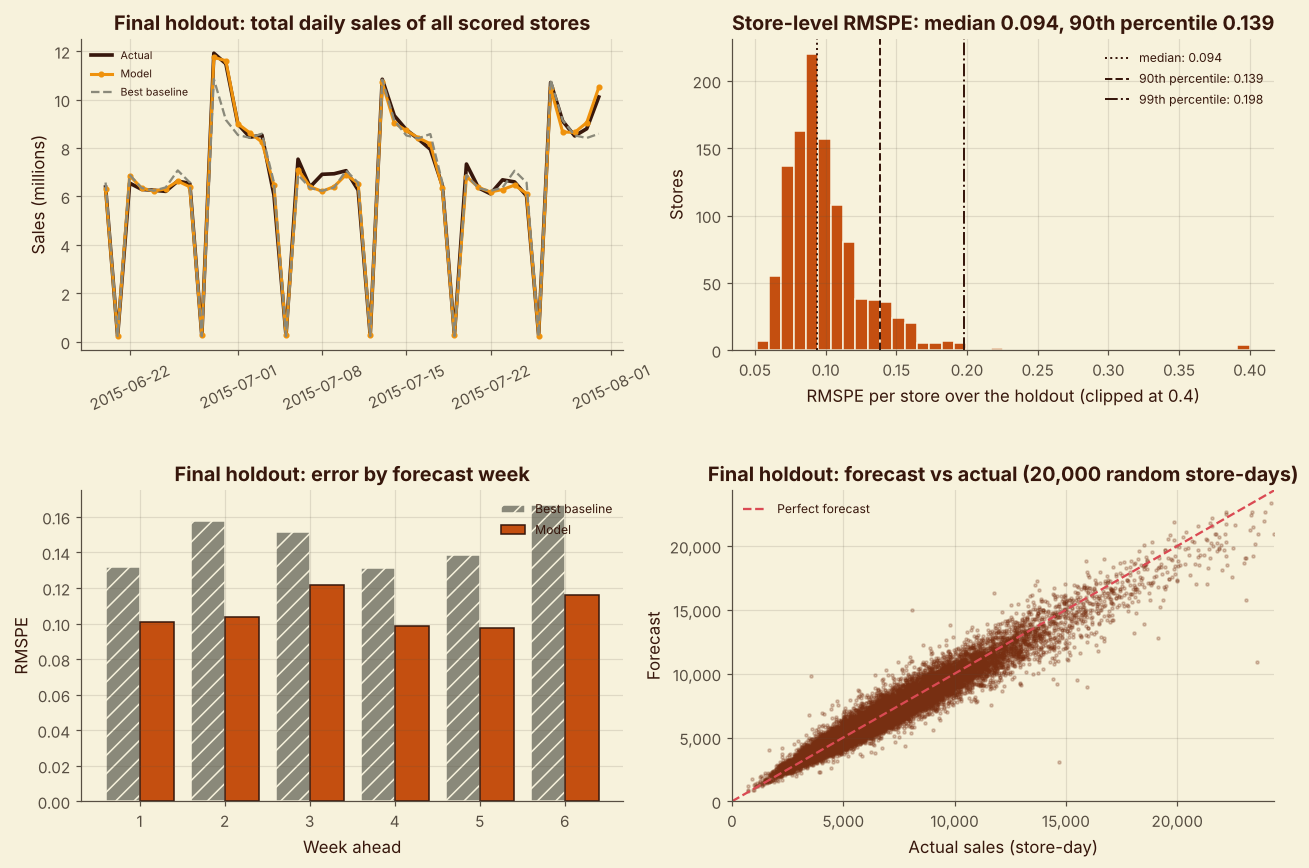

In [34]:
hg = E.add_groups(hold)
hg["opening"] = np.where(hg["days_since_long_closure"] < 60, "Within 60 days of reopening", "Normal trading")
hg["test-file store"] = np.where(hg["Store"].isin(test_stores), "In test.csv", "Not in test.csv")
parts = []
for by, order in [("promotion", None), ("holiday", None), ("weekday", list(DAYS.values())), ("week_ahead", list(range(1, 7))),
                  ("store_type", list("abcd")), ("opening", None), ("test-file store", None)]:
    t = E.breakdown(hg, ["baseline", "gb"], by).rename(columns={"baseline": "baseline RMSPE", "gb": "model RMSPE"})
    if order is not None:
        t = t.reindex([o for o in order if o in t.index])
    t.index = pd.MultiIndex.from_product([[by], t.index.astype(str)])
    parts.append(t)
hold_breakdown = pd.concat(parts)
style.show_table(hold_breakdown.round(3), 10, "Final holdout: error by group")

store_err = hold.groupby("Store").apply(lambda d: pd.Series({"rmspe": F.rmspe(d["Sales"], d["gb"]), "bias_pct": 100 * np.mean((d["gb"] - d["Sales"]) / d["Sales"]),
                                                             "days": len(d)}), include_groups=False)
worst_stores = store_err.sort_values("rmspe", ascending=False).head(10).join(store_clean.set_index("Store")[["StoreType", "has_history_gap"]])
style.show_table(worst_stores.round(3), 10, "Final holdout: the ten stores with the largest errors")
store_q = store_err["rmspe"].quantile([0.5, 0.9, 0.99])

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
d = hold.groupby("Date")[["Sales", "gb", "baseline", "lo", "hi"]].sum() / 1e6
axes[0, 0].plot(d.index, d["Sales"], color=FORECAST_COLORS["actual"], linewidth=2.4, label="Actual")
axes[0, 0].plot(d.index, d["gb"], color=FORECAST_COLORS["forecast"], linewidth=2, marker="o", markersize=3, label="Model")
axes[0, 0].plot(d.index, d["baseline"], color=FORECAST_COLORS["baseline"], linewidth=1.5, linestyle="--", label="Best baseline")
axes[0, 0].set_title("Final holdout: total daily sales of all scored stores")
axes[0, 0].set_ylabel("Sales (millions)")
axes[0, 0].tick_params(axis="x", rotation=25)
axes[0, 0].legend(fontsize=7)
axes[0, 1].hist(store_err["rmspe"].clip(upper=0.4), bins=40, color=PALETTE["terracotta"], edgecolor=PALETTE["cream"])
for q, ls, lab in zip(store_q.values, [":", "--", "-."], ["median", "90th percentile", "99th percentile"]):
    axes[0, 1].axvline(q, color=PALETTE["espresso"], linestyle=ls, linewidth=1.3, label=f"{lab}: {q:.3f}")
axes[0, 1].legend(fontsize=8)
axes[0, 1].set_title(f"Store-level RMSPE: median {store_q[0.5]:.3f}, 90th percentile {store_q[0.9]:.3f}")
axes[0, 1].set_xlabel("RMSPE per store over the holdout (clipped at 0.4)")
axes[0, 1].set_ylabel("Stores")
wk = hold_breakdown.loc["week_ahead"]
x = np.arange(len(wk))
axes[1, 0].bar(x - 0.2, wk["baseline RMSPE"], width=0.4, color=PALETTE["stone"], hatch="//", edgecolor=PALETTE["cream"], label="Best baseline")
axes[1, 0].bar(x + 0.2, wk["model RMSPE"], width=0.4, color=PALETTE["terracotta"], edgecolor=PALETTE["espresso"], label="Model")
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(wk.index)
axes[1, 0].set_xlabel("Week ahead")
axes[1, 0].set_ylabel("RMSPE")
axes[1, 0].set_title("Final holdout: error by forecast week")
axes[1, 0].legend(fontsize=8)
sample_h = hold.sample(20_000, random_state=config.SEED)
axes[1, 1].scatter(sample_h["Sales"], sample_h["gb"], s=4, alpha=0.25, color=PALETTE["umber"])
lim = [0, float(np.quantile(sample_h["Sales"], 0.999))]
axes[1, 1].plot(lim, lim, color=PALETTE["rose"], linestyle="--", linewidth=1.5, label="Perfect forecast")
axes[1, 1].set_xlim(lim)
axes[1, 1].set_ylim(lim)
axes[1, 1].set_xlabel("Actual sales (store-day)")
axes[1, 1].set_ylabel("Forecast")
axes[1, 1].set_title("Final holdout: forecast vs actual (20,000 random store-days)")
axes[1, 1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[1, 1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[1, 1].legend(fontsize=8)
fig.subplots_adjust(hspace=0.45)
style.save_figure(fig, 10, "Final holdout results")
plt.show()

**Reading the result.** The model beats the baseline in every group. Errors are lowest on promotion days (0.100) and Monday to Thursday (about 0.10), and highest on Saturdays (0.127), the 193 Sunday store-days (0.158) and the few days within 60 days of a long reopening (0.175, 62 rows). Week 3 of the holdout is the hardest week (0.122). The error does not grow steadily with the horizon: week 5 (0.097) is as good as week 1 (0.101). The store-level RMSPE distribution (figure) is concentrated around 0.09 to 0.10, and a handful of stores dominate the tail. Store 292 (0.68, a store with long closures), store 909 and store 782 are the worst, and the five gap stores in the top ten show the cost of the missing 2014 history.

## 10.3 Refit on All History and Package

The production models are trained on **every labelled row** of the final table (development period and holdout), saved as one timestamped bundle `models/dd-mm-yyyy-HH-MM-SS.pkl` (the brief's format) with a metadata file, reloaded to confirm identical predictions, registered in MLflow, and served through MLflow on the test data. The final table and the model folder become DVC version 4.

In [35]:
%%writefile src/bundle.py
"""Timestamped model bundles: everything needed to serve a forecast, saved as dd-mm-yyyy-HH-MM-SS.pkl."""
import json
from datetime import datetime
from pathlib import Path

import joblib

from .config import MODEL_TIMESTAMP_FORMAT, MODELS_DIR


def timestamp(now=None):
    return (now or datetime.now()).strftime(MODEL_TIMESTAMP_FORMAT)


def save_bundle(bundle, metadata, folder=MODELS_DIR, now=None):
    """Save the bundle as <folder>/<timestamp>.pkl and its metadata as <timestamp>.json; return the .pkl path."""
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    ts = timestamp(now)
    path = folder / f"{ts}.pkl"
    joblib.dump({**bundle, "metadata": {**metadata, "bundle": path.name}}, path, compress=3)
    (folder / f"{ts}.json").write_text(json.dumps({**metadata, "bundle": path.name}, indent=2, default=str), encoding="utf-8")
    return path


def list_bundles(folder=MODELS_DIR):
    """All bundles in a folder, oldest first (ordered by the timestamp in the file name, not by file dates)."""
    out = []
    for p in Path(folder).glob("*.pkl"):
        try:
            out.append((datetime.strptime(p.stem, MODEL_TIMESTAMP_FORMAT), p))
        except ValueError:
            continue
    return [p for _, p in sorted(out)]


def load_bundle(path=None, folder=MODELS_DIR):
    """Load a bundle; without a path, the latest one in the folder."""
    if path is None:
        bundles = list_bundles(folder)
        if not bundles:
            raise FileNotFoundError(f"No timestamped model bundle found in {folder}")
        path = bundles[-1]
    return joblib.load(path)

Writing src/bundle.py


In [36]:
%%writefile src/serving.py
"""MLflow serving wrapper for the production models.

MLflow's input schema has no 8- or 16-bit integer type, so it converts such columns to 32-bit integers before
predicting. In the preprocessing pipeline that moves the numeric block from float32 to float64 arithmetic; the tiny
rounding differences flip a few tree splits and can move a store-day forecast by a few hundred sales units. This
wrapper restores the training column types before predicting, so a model served through MLflow gives exactly the
same forecasts as the model in the timestamped bundle (checked in Section 10.3).
"""
import joblib
import mlflow.pyfunc
import pandas as pd


class TypedModel(mlflow.pyfunc.PythonModel):
    def load_context(self, context):
        saved = joblib.load(context.artifacts["model"])
        self.model, self.dtypes = saved["model"], saved["dtypes"]

    def predict(self, context, model_input, params=None):
        X = pd.DataFrame(model_input)[list(self.dtypes)].astype(self.dtypes)
        return self.model.predict(X)


def save_for_mlflow(model, dtypes, path):
    """Write the fitted model and its training column types to one file (the MLflow artifact)."""
    joblib.dump({"model": model, "dtypes": {c: str(t) for c, t in dtypes.items()}}, path, compress=3)
    return path

Writing src/serving.py


In [37]:
from src import bundle as BU
importlib.reload(BU)
import sklearn

# (slow: about 15 minutes) final models on all labelled history
full_train = final_table[final_table["use_for_training"] == 1]
t0 = time.time()
sales_final = M.make_model(FINALIST, FINAL_FEATURES, log_target=True, **FINAL_PARAMS).fit(full_train[FINAL_FEATURES], full_train["Sales"])
cust_final = M.make_model(FINALIST, FINAL_FEATURES, log_target=True, **CUSTOMER_PARAMS).fit(full_train[FINAL_FEATURES], full_train["Customers"])
final_fit_seconds = time.time() - t0
n_full_train = len(full_train)
full_train_dates = f"{full_train['Date'].min().date()} to {full_train['Date'].max().date()}"
train_dtypes = full_train[FINAL_FEATURES].dtypes.to_dict()
del full_train
gc.collect()
print(f"Final models fitted on {n_full_train:,} rows in {final_fit_seconds:.0f} s")

metadata = {
    "fingerprint": FINGERPRINT, "created": datetime.now().isoformat(timespec="seconds"),
    "training_rows": int(n_full_train), "training_dates": full_train_dates,
    "forecast_origin": str(LAST_DAY.date()), "features": FINAL_FEATURES, "sales_params": FINAL_PARAMS, "customers_params": CUSTOMER_PARAMS,
    "interval_method": INTERVAL_METHOD, "holdout_rmspe_development_model": hold_rmspe,
    "packages": {"python": sys.version.split()[0], "scikit-learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
bundle_path = BU.save_bundle({"sales_model": sales_final, "customers_model": cust_final, "features": FINAL_FEATURES,
                              "interval_calibration": calibration_table}, metadata)
reloaded = BU.load_bundle(bundle_path)
test_feat = pd.read_pickle(config.DATA_PROCESSED / "features_test.pkl.gz")
p_mem = sales_final.predict(test_feat[FINAL_FEATURES])
p_disk = reloaded["sales_model"].predict(test_feat[FINAL_FEATURES])
c_disk = reloaded["customers_model"].predict(test_feat[FINAL_FEATURES])
packaged = pd.Series({
    "Bundle file": f"models/{bundle_path.name} ({bundle_path.stat().st_size / 1e6:.1f} MB)",
    "Metadata file": f"models/{bundle_path.stem}.json",
    "Timestamp format": config.MODEL_TIMESTAMP_FORMAT,
    "Reloaded sales predictions identical": bool(np.array_equal(p_mem, p_disk)),
    "Reloaded customer predictions identical": bool(np.array_equal(cust_final.predict(test_feat[FINAL_FEATURES]), c_disk)),
    "Bundles in models/": ", ".join(p.name for p in BU.list_bundles()),
}, dtype=object).to_frame("value")
style.show_table(packaged, 10, "The timestamped model bundle")
assert packaged.loc["Reloaded sales predictions identical", "value"] and packaged.loc["Reloaded customer predictions identical", "value"]

Final models fitted on 1,360,683 rows in 355 s


**Table 10.8: The timestamped model bundle**

,value
Bundle file,models/03-11-2026-12-32-51.pkl (4.1 MB)
Metadata file,models/03-11-2026-12-32-51.json
Timestamp format,%d-%m-%Y-%H-%M-%S
Reloaded sales predictions identical,True
Reloaded customer predictions identical,True
Bundles in models/,03-11-2026-12-32-51.pkl


**Reading the result.** The production models are trained on all 1,360,683 labelled rows. They are saved together with the interval calibration, feature list and metadata in one bundle named in the brief's format, `models/03-11-2026-12-32-51.pkl` (about 4 MB). Reloaded from disk, they give identical predictions.

In [38]:
# register the final models and serve the test data through MLflow (wrapper restores the training column types)
from src import serving as SV
importlib.reload(SV)
PIP = [f"scikit-learn=={sklearn.__version__}", f"pandas=={pd.__version__}", f"numpy=={np.__version__}", f"mlflow=={mlflow.__version__}",
       f"joblib=={__import__('joblib').__version__}"]
serve_dir = config.MODELS_DIR / "mlflow_artifacts"
serve_dir.mkdir(parents=True, exist_ok=True)
final_versions = {}
for model, reg_name, params, label in [(sales_final, "rossmann-gradient-boosting", FINAL_PARAMS, "sales"),
                                       (cust_final, "rossmann-customers", CUSTOMER_PARAMS, "customers")]:
    with mlflow.start_run(run_name=f"final-{label}-all-history") as run:
        mlflow.set_tags({"section": "10.3", "stage": "production", "fingerprint": FINGERPRINT, "bundle": bundle_path.name})
        mlflow.log_params({"model": FINALIST, "n_features": len(FINAL_FEATURES), "training_rows": n_full_train, **{f"p_{k}": v for k, v in params.items()}})
        if label == "sales":
            mlflow.log_metrics({"holdout_rmspe": hold_rmspe, "holdout_interval_coverage": float(hold_cov.loc["Sales", "coverage_pct"])})
        else:
            mlflow.log_metrics({"holdout_rmspe": float(holdout_scores.loc[("Customers", "Customer model"), "rmspe"])})
        mlflow.log_artifact(str(bundle_path.with_suffix(".json")))
        art = SV.save_for_mlflow(model, train_dtypes, serve_dir / f"{label}.joblib")
        kw = dict(python_model=SV.TypedModel(), artifacts={"model": str(art)}, code_paths=[str(ROOT / "src")],
                  registered_model_name=reg_name, input_example=test_feat[FINAL_FEATURES].head(5), pip_requirements=PIP)
        try:
            mlflow.pyfunc.log_model(name="model", **kw)
        except TypeError:
            mlflow.pyfunc.log_model(artifact_path="model", **kw)
    final_versions[reg_name] = max(int(v.version) for v in client.search_model_versions(f"name='{reg_name}'"))

# MLflow inference: load the registered production model by name and version, and predict the test file
uri = f"models:/rossmann-gradient-boosting/{final_versions['rossmann-gradient-boosting']}"
served = mlflow.pyfunc.load_model(uri)
mlflow_pred = np.asarray(served.predict(test_feat[FINAL_FEATURES]))
mlflow_demo = pd.Series({
    "Model URI": uri,
    "Rows predicted through MLflow": f"{len(mlflow_pred):,}",
    "Largest difference from the bundle's predictions": f"{np.max(np.abs(mlflow_pred - p_disk)):.6f} sales units",
    "Why a wrapper": "MLflow turns 8/16-bit integer columns into 32-bit; the wrapper restores the training types (src/serving.py)",
    "Registered versions": ", ".join(f"{k} v{v}" for k, v in final_versions.items()),
}, dtype=object).to_frame("value")
style.show_table(mlflow_demo, 10, "MLflow inference on the test data")
assert np.array_equal(mlflow_pred, p_disk), "MLflow serving does not reproduce the bundle exactly"

/usr/local/lib/python3.13/site-packages/mlflow/pyfunc/utils/data_validation.py:187: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(
/usr/local/lib/python3.13/site-packages/mlflow/pyfunc/utils/data_validation.py:187: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(


2026/11/03 12:32:53 WARNING mlflow.pyfunc: Passing a Python object as `python_model` causes it to be serialized using CloudPickle, it requires exercising caution as Python object serialization mechanisms may execute arbitrary code during deserialization.Consider using a file path (str or Path) instead. See https://mlflow.org/docs/latest/ml/model/models-from-code/ for details.


2026/11/03 12:32:53 INFO mlflow.pyfunc: Inferring model signature from input example


Registered model 'rossmann-gradient-boosting' already exists. Creating a new version of this model...
Created version '3' of model 'rossmann-gradient-boosting'.


2026/11/03 12:32:54 WARNING mlflow.pyfunc: Passing a Python object as `python_model` causes it to be serialized using CloudPickle, it requires exercising caution as Python object serialization mechanisms may execute arbitrary code during deserialization.Consider using a file path (str or Path) instead. See https://mlflow.org/docs/latest/ml/model/models-from-code/ for details.


2026/11/03 12:32:54 INFO mlflow.pyfunc: Inferring model signature from input example


Registered model 'rossmann-customers' already exists. Creating a new version of this model...
Created version '2' of model 'rossmann-customers'.


**Table 10.9: MLflow inference on the test data**

,value
Model URI,models:/rossmann-gradient-boosting/3
Rows predicted through MLflow,"41,088"
Largest difference from the bundle's predictions,0.000000 sales units
Why a wrapper,MLflow turns 8/16-bit integer columns into 32-bit; the wrapper restores the training types (src/serving.py)
Registered versions,"rossmann-gradient-boosting v3, rossmann-customers v2"


**Reading the result.** `rossmann-gradient-boosting` version 3 (production) and `rossmann-customers` version 2 are registered. Loaded back by name and version through MLflow, the model forecasts all 41,088 test rows with **zero** difference from the bundle. A first attempt without the wrapper differed by up to 417 sales units on more than half of the rows (found in development). MLflow converts 8- and 16-bit integer columns to 32-bit, which moves the preprocessing from float32 to float64 arithmetic and flips a few tree splits. The `src/serving.py` wrapper restores the training column types, so the served model is the trained model.

In [39]:
# DVC version 4: the final training table, and the model folder as its own tracked folder
fast_gzip = {"method": "gzip", "compresslevel": 3}
keep_cols = ["Store", "Date", "origin_date", "horizon_day", "Open", "use_for_training", "Sales", "Customers"] + FINAL_FEATURES
final_table[keep_cols].to_pickle(config.DATA_PROCESSED / "features_final.pkl.gz", compression=fast_gzip, protocol=4)
save_data_version("data-v4-final", "Data v4: final training table through 31 Jul 2015 (Section 10)")
save_data_version("models-v1", "Models v1: final timestamped bundle (Section 10)", target="models")
print("--- Data versions")
sh("git log --oneline -- data.dvc")
_ = sh("git tag -l")

2026-11-03 12:32:58 | INFO     | rossmann | Data version saved: data-v4-final


2026-11-03 12:32:59 | INFO     | rossmann | Data version saved: models-v1


--- Data versions
8d6c347 Data v4: final training table through 31 Jul 2015 (Section 10)
9a407c8 Data v3: feature tables (Section 6)
5a99558 Data v2: cleaned and merged data (Section 3)
1bf6c46 Data v3: feature tables (Section 6)
868c2bc Data v2: cleaned and merged data (Section 3)
a45e8b1 Data v1: raw files tracked with DVC
data-v1-raw
data-v2-cleaned
data-v3-features
data-v4-final
models-v1


## 10.4 Test Predictions and the Submission File

Every row of `test.csv` is forecast from the origin 31 Jul 2015 with the bundle saved above. Closed days (`Open = 0`) are set to 0. The file `outputs/submission.csv` has exactly the columns of `sample_submission.csv` (`Id`, `Sales`); a second file adds customers and the 90% ranges.

**Table 10.10: Submission file checks**

,passed
check,
"41,088 rows",True
Ids unique and identical to sample_submission,True
Same columns as sample_submission,True
All values finite and non-negative,True
Closed days are exactly 0,True
Every open day has a positive forecast,True
Lower bound <= forecast <= upper bound,True


**Table 10.11: Sanity check of the test forecasts**

,value
"Forecast total, 48 days, all 856 test stores",241.7 million
"Forecast total, the 676 test stores with a complete history",192.1 million
"Same stores, same weekdays 52 weeks earlier (actual)",187.4 million
Change vs a year earlier,+2.5%
"Same stores, average per open store-day: last 8 weeks (actual) vs forecast","6,949 vs 6,888"


Figure 10.2: Test forecasts in context


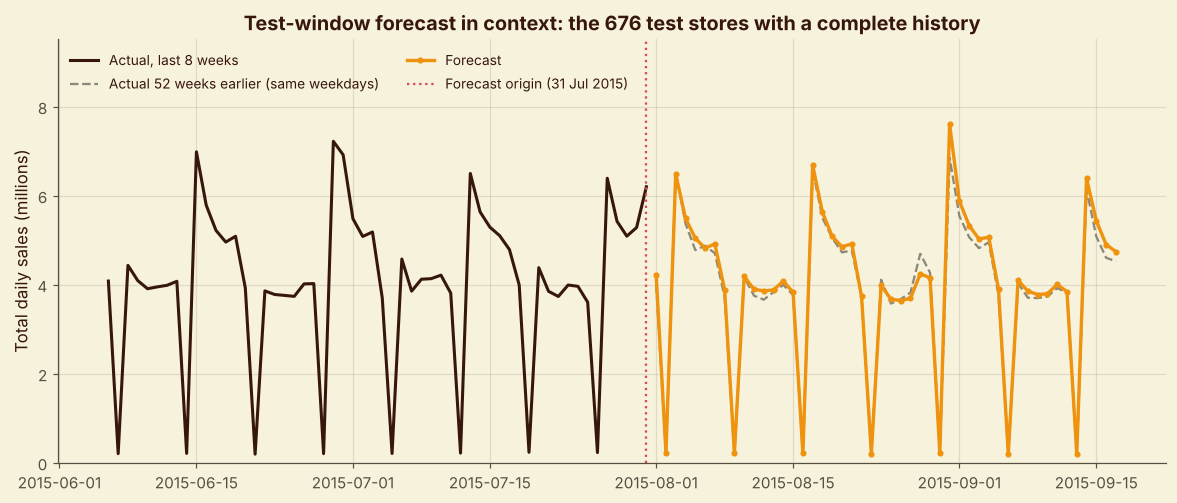

In [40]:
sample = pd.read_csv(config.RAW_FILES["sample_submission"])
tf_ = test_feat[["Id", "Store", "Date", "Open", "horizon_day", "hist_mean_all"]].copy()
tf_["Sales"] = np.where(tf_["Open"] == 1, np.maximum(p_disk, 0), 0.0)
tf_["Customers"] = np.where(tf_["Open"] == 1, np.maximum(c_disk, 0), 0.0)
lo_t, hi_t = final_intervals.predict(np.maximum(p_disk, 0), interval_groups(tf_))
clo_t, chi_t = cust_intervals.predict(np.maximum(c_disk, 0), interval_groups(tf_))
tf_["sales_low_90"], tf_["sales_high_90"] = np.where(tf_["Open"] == 1, lo_t, 0), np.where(tf_["Open"] == 1, hi_t, 0)
tf_["customers_low_90"], tf_["customers_high_90"] = np.where(tf_["Open"] == 1, clo_t, 0), np.where(tf_["Open"] == 1, chi_t, 0)
tf_["Id"] = tf_["Id"].astype(int)
submission = tf_[["Id", "Sales"]].sort_values("Id").reset_index(drop=True)
submission.to_csv(OUTPUT_DIR / "submission.csv", index=False)
detail = tf_.sort_values("Id").assign(model_version=bundle_path.name)
detail.drop(columns=["hist_mean_all"]).to_csv(OUTPUT_DIR / "test_forecasts_detailed.csv", index=False)

sub_checks = pd.DataFrame([
    ("41,088 rows", len(submission) == 41_088),
    ("Ids unique and identical to sample_submission", bool(submission["Id"].is_unique and set(submission["Id"]) == set(sample["Id"]))),
    ("Same columns as sample_submission", list(submission.columns) == list(sample.columns)),
    ("All values finite and non-negative", bool(np.isfinite(submission["Sales"]).all() and (submission["Sales"] >= 0).all())),
    ("Closed days are exactly 0", bool((detail.loc[detail["Open"] == 0, "Sales"] == 0).all())),
    ("Every open day has a positive forecast", bool((detail.loc[detail["Open"] == 1, "Sales"] > 0).all())),
    ("Lower bound <= forecast <= upper bound", bool(((detail["sales_low_90"] <= detail["Sales"]) & (detail["Sales"] <= detail["sales_high_90"])).all())),
], columns=["check", "passed"]).set_index("check")
style.show_table(sub_checks, 10, "Submission file checks", save=False)
assert sub_checks["passed"].all()

# sanity: forecast totals against recent weeks and the same weekdays 52 weeks earlier (same stores: test stores with a complete history)
gap_stores = set(store_clean.loc[store_clean["has_history_gap"] == 1, "Store"])
same = sorted(set(test_clean["Store"]) - gap_stores)
hist_same = train_clean[train_clean["Store"].isin(same)]
recent = hist_same[hist_same["Date"] > LAST_DAY - pd.Timedelta(days=56)].groupby("Date")["Sales"].sum() / 1e6
lag = pd.Timedelta(days=364)
ly = hist_same[hist_same["Date"].between(test_clean["Date"].min() - lag, test_clean["Date"].max() - lag)].groupby("Date")["Sales"].sum() / 1e6
ly.index = ly.index + lag
fc_same = detail[detail["Store"].isin(same)].groupby("Date")["Sales"].sum() / 1e6
fc_all = detail.groupby("Date")["Sales"].sum() / 1e6
sanity = pd.Series({
    "Forecast total, 48 days, all 856 test stores": f"{fc_all.sum():,.1f} million",
    f"Forecast total, the {len(same)} test stores with a complete history": f"{fc_same.sum():,.1f} million",
    "Same stores, same weekdays 52 weeks earlier (actual)": f"{ly.sum():,.1f} million",
    "Change vs a year earlier": f"{100 * (fc_same.sum() / ly.sum() - 1):+.1f}%",
    "Same stores, average per open store-day: last 8 weeks (actual) vs forecast":
        f"{hist_same[(hist_same['Date'] > LAST_DAY - pd.Timedelta(days=56)) & (hist_same['use_for_training'] == 1)]['Sales'].mean():,.0f} vs "
        f"{detail[detail['Store'].isin(same) & (detail['Open'] == 1)]['Sales'].mean():,.0f}",
}, dtype=object).to_frame("value")
style.show_table(sanity, 10, "Sanity check of the test forecasts")

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(recent.index, recent.values, color=FORECAST_COLORS["actual"], linewidth=2, label="Actual, last 8 weeks")
ax.plot(ly.index, ly.values, color=FORECAST_COLORS["baseline"], linewidth=1.5, linestyle="--", label="Actual 52 weeks earlier (same weekdays)")
ax.plot(fc_same.index, fc_same.values, color=FORECAST_COLORS["forecast"], linewidth=2.2, marker="o", markersize=3, label="Forecast")
ax.axvline(LAST_DAY, color=PALETTE["rose"], linestyle=":", linewidth=1.5, label="Forecast origin (31 Jul 2015)")
ax.set_ylabel("Total daily sales (millions)")
ax.set_title(f"Test-window forecast in context: the {len(same)} test stores with a complete history")
ax.legend(fontsize=9, loc="upper left", ncol=2)
ax.set_ylim(0, max(recent.max(), ly.max(), fc_same.max()) * 1.25)
style.save_figure(fig, 10, "Test forecasts in context")
plt.show()

**Reading the result.** `outputs/submission.csv` passes every check: 41,088 rows, Ids identical to `sample_submission.csv`, all values finite and non-negative, closed days exactly 0, every open day positive, and every forecast inside its own 90% range. For the 676 test stores with a complete history, the 48-day forecast total is 192.1 million against 187.4 million on the same weekdays 52 weeks earlier (+2.5%). That is a plausible year-on-year change, in line with the spring 2015 growth seen in Section 5. The average forecast per open store-day matches the last 8 weeks' actual level closely.

In [41]:
c10 = pd.DataFrame([
    ("The configuration was frozen before the holdout was scored (fingerprint in the Decision Register)", bool(decision_register["decision"].str.contains(FINGERPRINT).any())),
    ("The evaluation-access log holds exactly one holdout entry", int(evaluation_log["dataset"].astype(str).str.startswith("final holdout").sum()) == 1),
    ("Holdout scored on every open, positive-sales store-day of the window", len(hold) == int((holdout_mask & (train_clean["use_for_training"] == 1)).sum())),
    ("Final models trained on all labelled rows of the final table", n_full_train == int(final_table["use_for_training"].sum())),
    ("Timestamped bundle saved, reloaded and identical", bool(packaged.loc["Reloaded sales predictions identical", "value"])),
    ("MLflow serves the registered model with the same predictions", bool(np.allclose(mlflow_pred, p_disk))),
    ("Submission file passes every check", bool(sub_checks["passed"].all())),
], columns=["check", "passed"]).set_index("check")
style.show_table(c10, 10, "Section 10 completion checks", save=False)
assert c10["passed"].all()

**Table 10.12: Section 10 completion checks**

,passed
check,
The configuration was frozen before the holdout was scored (fingerprint in the Decision Register),True
The evaluation-access log holds exactly one holdout entry,True
"Holdout scored on every open, positive-sales store-day of the window",True
Final models trained on all labelled rows of the final table,True
"Timestamped bundle saved, reloaded and identical",True
MLflow serves the registered model with the same predictions,True
Submission file passes every check,True


## Section 10 Summary
- Frozen configuration `2a262976d01c`. **Final holdout, scored once: sales RMSPE 0.1068 (target met; baseline 0.1468), customers 0.0877, 90% interval coverage 88.4%.**
- Production bundle `models/03-11-2026-12-32-51.pkl`. MLflow serves the registered model with identical forecasts. DVC versions `data-v4-final` and `models-v1` are recorded.
- The submission file and a detailed file (customers and 90% ranges) are written and checked.

**Section 10 decisions.** The target fixed in Section 7 (D49, provisional until now) is confirmed or marked as missed from the holdout result; the final files are recorded.

In [42]:
met = bool(hold_rmspe <= TARGET_ROLLING_RMSPE and hold_rmspe < base_rmspe)
decision_register.loc[decision_register["decision"].str.startswith("Success target fixed after measuring the baselines"), "status"] = \
    f"{'Met' if met else 'Missed'} on the final holdout (Section 10.2): RMSPE {hold_rmspe:.4f}"
if not decision_register["decision"].str.contains(bundle_path.name, regex=False).any():
    log_decision(10, f"Production bundle {bundle_path.name}: sales and customer models trained on all {n_full_train:,} labelled rows, interval calibration, feature list and metadata; registered as rossmann-gradient-boosting v{final_versions['rossmann-gradient-boosting']} and rossmann-customers v{final_versions['rossmann-customers']}.",
                 "One timestamped file serves the app; MLflow serves the same model by name and version.")
    log_decision(10, "submission.csv holds one forecast per test Id (41,088 rows); closed days are 0; customers and 90% ranges are in test_forecasts_detailed.csv.",
                 "Matches sample_submission.csv exactly and keeps the extra outputs separate.")
    log_limitation(10, f"The holdout is one 42-day window in early summer; its RMSPE ({hold_rmspe:.4f}) is one draw of forecast conditions.",
                   "The rolling windows and the seasonal check give the range around it; days 43 to 48 of the test window are covered only by the seasonal check.")
    log_limitation(10, "Test-window forecasts assume the supplied Open, Promo and holiday plans are what actually happens.",
                   "Changes to the plans after the forecast date are not reflected unless the forecast is re-run (the app allows this).")
save_registers()
style.save_index()
sh("git add -A")
sh('git commit -m "Section 10: final holdout, refit, timestamped bundle, MLflow inference and submission"', check=False, quiet=True)
if not sh("git tag -l submission-v1", quiet=True).stdout.strip():
    sh("git tag submission-v1", quiet=True)
display(decision_register.tail(4))

,id,section,decision,reason,status
70,D71,9,"Prediction intervals: conformal by forecast week and store size, nominal 90%, calibrated on all three rolling windows for the app; days 43 to 48 use week 6.",Calibrated on rolling 1 and 2 it covered 90.3% on rolling 3 and 90.0% on the seasonal check; chosen because it is closest to 90% both overall and in its worst store-size group (quantile regression...,Confirmed
71,D72,10,"Frozen configuration 2a262976d01c: production model = gradient boosting with the Section 7 settings and 59 features; customers model with {'max_iter': 300, 'learning_rate': 0.1, 'max_leaf_nodes': ...",All choices were made on the rolling windows; nothing may change after the holdout is scored.,Confirmed
72,D73,10,"Production bundle 03-11-2026-12-32-51.pkl: sales and customer models trained on all 1,360,683 labelled rows, interval calibration, feature list and metadata; registered as rossmann-gradient-boosti...",One timestamped file serves the app; MLflow serves the same model by name and version.,Confirmed
73,D74,10,"submission.csv holds one forecast per test Id (41,088 rows); closed days are 0; customers and 90% ranges are in test_forecasts_detailed.csv.",Matches sample_submission.csv exactly and keeps the extra outputs separate.,Confirmed


---

# Section 11: Streamlit App and Deployment

| Step | What it covers |
|---|---|
| 11.1 | Inference module `src/predict.py`: the same feature code as training, input checks, intervals |
| 11.2 | The Streamlit app `app.py` |
| 11.3 | Tests: app features and forecasts equal the notebook's, edge cases, speed, requirements |
| 11.4 | Deployment on Streamlit Community Cloud |

## 11.1 The Inference Module

**Inputs the store manager supplies:** a store number and a CSV with one row per future day: `Date`, `Promo` (or `IsPromo`), and optionally `Open`, `StateHoliday` (or `IsHoliday`), `SchoolHoliday`, `IsWeekend` (checked against the date). Inputs that do not depend on the date (store type, assortment, competition, Promo2) come from the store table.

**Supported horizon:** 1 Aug to 17 Sep 2015, the 48 days after the last day with known sales (the same origin as the test file). A forecast for later dates would need the history features recomputed at a later origin, which needs newer sales data; the app says so instead of extrapolating.

**How the features are built:** `Forecaster.feature_rows` calls the training function `features.add_known_future_features` on the store's last 200 days of planned inputs plus the uploaded days, and joins the store profile computed by `features.history_profile` at the origin, exactly like `features.build_origin_rows`. Days of the window that are not uploaded are filled from the store's default plan so that week-based features (promotion this week, last week) see a full calendar. The app data is written by `build_app_data` (about 5 MB, committed to Git so the hosted app can read it).

In [43]:
%%writefile src/predict.py
"""Inference for the app: one store + a table of future dates and planned inputs -> sales, customers and 90% intervals.

The features are built with exactly the training code (src/features.py). Two small precomputed pieces replace the
full history, so the app stays light:
  * the store profile at the forecast origin (features.history_profile, the same call the training rows use);
  * the last 200 days of planned inputs per store (for promotion-week, closure and holiday-distance features).
The holiday calendar of the training data (holidays flagged for at least 90% of stores) is reproduced by adding
placeholder "calendar carrier" rows, so features.holiday_calendar finds exactly the same national holidays from a
single store's rows. Section 11.3 checks that the app's features equal the training features for every test store.
"""
import json
import logging
from pathlib import Path

import numpy as np
import pandas as pd

from . import features as F
from .bundle import load_bundle
from .config import ROOT
from .intervals import week_ahead

APP_DIR = ROOT / "app_data"
SNAPSHOT_DAYS = 200
N_CARRIERS = 19                      # with the store's own row, 19 carriers give a holiday share of at least 0.95
ALIASES = {"IsPromo": "Promo", "IsOpen": "Open", "IsSchoolHoliday": "SchoolHoliday"}
STORE_COLUMNS = ["Store", "StoreType", "Assortment", "CompetitionDistance", "CompetitionDistance_missing", "CompetitionOpenSince",
                 "CompetitionOpenDate_known", "Promo2", "Promo2SinceWeek", "Promo2SinceYear", "PromoInterval", "has_history_gap"]
PLAN_INPUTS = ["Store", "Date", "DayOfWeek", "Open", "Promo", "StateHoliday", "SchoolHoliday"]


# ----------------------------------------------------------------------------- packaging (run once, in the notebook)
def build_app_data(train_clean, test_clean, store_clean, bundle_path, out_dir=APP_DIR):
    """Write the small files the app needs (about 5 MB) and copy the model bundle next to them."""
    import shutil
    out = Path(out_dir)
    out.mkdir(parents=True, exist_ok=True)
    origin = train_clean["Date"].max()
    plan = F.make_plan(train_clean, test_clean)
    recent = train_clean[train_clean["Date"] > origin - pd.Timedelta(days=SNAPSHOT_DAYS)][PLAN_INPUTS]
    recent.to_csv(out / "recent_plan.csv.gz", index=False)
    test_clean[PLAN_INPUTS].to_csv(out / "test_plan.csv.gz", index=False)
    store_clean[STORE_COLUMNS].to_csv(out / "stores.csv", index=False)
    prof, dow = F.history_profile(train_clean, origin)
    prof.to_csv(out / "profile.csv")
    dow.to_csv(out / "profile_weekday.csv", index=False)
    F.find_gap_end(train_clean).rename("gap_end").to_csv(out / "gap_end.csv")
    # sales one year (364 days) before the supported dates, only needed if the model uses the same-year-earlier features
    lag = pd.Timedelta(days=F.LAST_YEAR_LAG_DAYS)
    ly = train_clean[train_clean["Date"].between(origin + pd.Timedelta(days=1) - lag - pd.Timedelta(days=10),
                                                 test_clean["Date"].max() - lag + pd.Timedelta(days=10))]
    ly[["Store", "Date", "Open", "Sales"]].to_csv(out / "last_year_sales.csv.gz", index=False)
    cal = F.holiday_calendar(plan)
    flagged = plan[plan["StateHoliday"] != "0"]
    types = flagged.groupby("Date")["StateHoliday"].agg(lambda s: s.mode().iloc[0])
    pd.DataFrame({"Date": cal["any"], "StateHoliday": types.reindex(cal["any"]).values}).to_csv(out / "national_holidays.csv", index=False)
    # one promotion calendar for the whole chain (Section 5): used for stores that are not in test.csv
    chain_promo = test_clean.groupby("Date")["Promo"].agg(lambda s: int(s.mode().iloc[0]))
    chain_promo.rename("Promo").to_csv(out / "chain_promo_calendar.csv")
    shutil.copy(bundle_path, out / Path(bundle_path).name)
    meta = {"origin": str(origin.date()), "first_date": str((origin + pd.Timedelta(days=1)).date()), "last_date": str(test_clean["Date"].max().date()),
            "bundle": Path(bundle_path).name, "stores": int(store_clean["Store"].nunique())}
    (out / "app_meta.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
    return meta


# ----------------------------------------------------------------------------- the forecaster used by the app
class Forecaster:
    def __init__(self, app_dir=APP_DIR):
        d = Path(app_dir)
        self.meta = json.loads((d / "app_meta.json").read_text(encoding="utf-8"))
        self.origin = pd.Timestamp(self.meta["origin"])
        self.first_date, self.last_date = pd.Timestamp(self.meta["first_date"]), pd.Timestamp(self.meta["last_date"])
        self.bundle = load_bundle(d / self.meta["bundle"])
        self.features = self.bundle["features"]
        self.recent = pd.read_csv(d / "recent_plan.csv.gz", parse_dates=["Date"], dtype={"StateHoliday": str})
        self.test_plan = pd.read_csv(d / "test_plan.csv.gz", parse_dates=["Date"], dtype={"StateHoliday": str})
        self.stores_tab = pd.read_csv(d / "stores.csv", parse_dates=["CompetitionOpenSince"], keep_default_na=True)
        self.stores_tab["PromoInterval"] = self.stores_tab["PromoInterval"].fillna("None")
        self.profile = pd.read_csv(d / "profile.csv", index_col="Store").astype("float32")
        self.profile_dow = pd.read_csv(d / "profile_weekday.csv")
        self.gap_end = pd.read_csv(d / "gap_end.csv", index_col=0, parse_dates=["gap_end"])["gap_end"]
        nat = pd.read_csv(d / "national_holidays.csv", parse_dates=["Date"], dtype={"StateHoliday": str})
        self.national = nat.set_index("Date")["StateHoliday"]
        self.chain_promo = pd.read_csv(d / "chain_promo_calendar.csv", parse_dates=["Date"]).set_index("Date")["Promo"]
        self.last_year = pd.read_csv(d / "last_year_sales.csv.gz", parse_dates=["Date"])
        cal = self.bundle["interval_calibration"]
        self.size_edges = json.loads(cal["size_edges"].iloc[0])
        self.cal = {t: g.drop(columns=["target", "size_edges", "level"]) for t, g in cal.groupby("target")}

    @property
    def stores(self):
        return sorted(self.stores_tab["Store"].astype(int).tolist())

    # ---------------------------------------------------------------- default plan and example file
    def default_plan(self, store):
        """The planned inputs of every supported date: from test.csv when the store is in it, otherwise from the chain-wide
        promotion calendar, the national holidays and the store's usual Sunday opening."""
        days = pd.date_range(self.first_date, self.last_date)
        tp = self.test_plan[self.test_plan["Store"] == store]
        if len(tp) == len(days):
            out = tp.set_index("Date").reindex(days)
        else:
            hist = self.recent[self.recent["Store"] == store]
            sunday_open = bool(hist.loc[hist["DayOfWeek"] == 7, "Open"].mean() > 0.5) if (hist["DayOfWeek"] == 7).any() else False
            out = pd.DataFrame(index=days)
            out["StateHoliday"] = self.national.reindex(days).fillna("0").values
            out["Promo"] = self.chain_promo.reindex(days).fillna(0).astype(int).values
            out["SchoolHoliday"] = 0
            is_sun = days.dayofweek == 6
            out["Open"] = np.where((out["StateHoliday"] != "0") | (is_sun & ~sunday_open), 0, 1)
        out = out.reset_index().rename(columns={"index": "Date"})
        out["Store"] = store
        return out[["Date", "Open", "Promo", "StateHoliday", "SchoolHoliday"]]

    def example_input(self, store):
        ex = self.default_plan(store)
        ex["IsHoliday"] = (ex["StateHoliday"] != "0").astype(int)
        ex["IsWeekend"] = (ex["Date"].dt.dayofweek >= 5).astype(int)
        ex["Date"] = ex["Date"].dt.strftime("%Y-%m-%d")
        return ex[["Date", "Open", "Promo", "IsHoliday", "StateHoliday", "SchoolHoliday", "IsWeekend"]]

    # ---------------------------------------------------------------- input checks
    def validate(self, store, table):
        """Return (clean table with one row per uploaded date, list of notes). Raises ValueError with a readable message."""
        if store not in set(self.stores):
            raise ValueError(f"Store {store} is not in the data. Choose a store number between {min(self.stores)} and {max(self.stores)}.")
        df = table.rename(columns={c: ALIASES.get(c, c) for c in table.columns}).copy()
        notes = []
        missing = [c for c in ["Date", "Promo"] if c not in df.columns]
        if missing:
            raise ValueError(f"The file is missing the column(s): {', '.join(missing)}. Required: Date and Promo (or IsPromo). "
                             "Optional: Open, StateHoliday or IsHoliday, SchoolHoliday, IsWeekend.")
        df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
        if df["Date"].isna().any():
            raise ValueError(f"{int(df['Date'].isna().sum())} row(s) have a date that cannot be read. Use the format YYYY-MM-DD.")
        if df["Date"].duplicated().any():
            raise ValueError("Each date may appear only once.")
        outside = df[(df["Date"] < self.first_date) | (df["Date"] > self.last_date)]
        if len(outside):
            raise ValueError(f"{len(outside)} date(s) are outside the supported forecast window "
                             f"({self.first_date.date()} to {self.last_date.date()}, the 48 days after the last day with known sales).")
        default = self.default_plan(store).set_index("Date")
        if "StateHoliday" not in df.columns and "IsHoliday" in df.columns:
            df["StateHoliday"] = np.where(pd.to_numeric(df["IsHoliday"], errors="coerce") == 1, "a", "0")
            notes.append("IsHoliday = 1 was read as a public holiday (StateHoliday 'a').")
        for col in ["Open", "StateHoliday", "SchoolHoliday"]:
            if col not in df.columns:
                df[col] = df["Date"].map(default[col])
                notes.append(f"{col} was not supplied; the default plan was used.")
        for col in ["Promo", "Open", "SchoolHoliday"]:
            df[col] = pd.to_numeric(df[col], errors="coerce")
            bad = ~df[col].isin([0, 1])
            if bad.any():
                raise ValueError(f"Column {col} must contain only 0 or 1 ({int(bad.sum())} other value(s) found).")
            df[col] = df[col].astype(int)
        df["StateHoliday"] = df["StateHoliday"].astype(str).str.strip().replace({"0.0": "0", "nan": "0"})
        if not df["StateHoliday"].isin(["0", "a", "b", "c"]).all():
            raise ValueError("StateHoliday must be 0, a (public holiday), b (Easter) or c (Christmas).")
        if "IsWeekend" in df.columns:
            wrong = pd.to_numeric(df["IsWeekend"], errors="coerce") != (df["Date"].dt.dayofweek >= 5).astype(int)
            if wrong.any():
                raise ValueError(f"IsWeekend disagrees with the date on {int(wrong.sum())} row(s) (Saturday and Sunday are weekend days).")
        return df.sort_values("Date").reset_index(drop=True)[["Date", "Open", "Promo", "StateHoliday", "SchoolHoliday"]], notes

    # ---------------------------------------------------------------- features (exactly the training code)
    def feature_rows(self, store, clean):
        """Training features for the uploaded dates. Dates between the origin and the last uploaded date that were not
        uploaded are filled from the default plan, so week-based features see a complete calendar."""
        default = self.default_plan(store)
        future = default[default["Date"] <= self.last_date].set_index("Date")
        future.update(clean.set_index("Date"))
        future = future.reset_index()
        future["Store"] = store
        hist = self.recent[self.recent["Store"] == store].drop(columns="DayOfWeek")
        rows = pd.concat([hist, future], ignore_index=True)
        rows["DayOfWeek"] = rows["Date"].dt.dayofweek + 1
        days = pd.date_range(rows["Date"].min(), self.last_date)
        carriers = pd.DataFrame({"Date": np.tile(days, N_CARRIERS), "Store": np.repeat(-np.arange(1, N_CARRIERS + 1), len(days))})
        carriers["DayOfWeek"] = carriers["Date"].dt.dayofweek + 1
        carriers["Open"], carriers["Promo"], carriers["SchoolHoliday"] = 1, 0, 0
        carriers["StateHoliday"] = carriers["Date"].map(self.national).fillna("0")
        st = self.stores_tab.set_index("Store")
        neutral = {"StoreType": "a", "Assortment": "a", "CompetitionDistance": 1000.0, "CompetitionDistance_missing": 0,
                   "CompetitionOpenSince": pd.NaT, "CompetitionOpenDate_known": 0, "Promo2": 0, "Promo2SinceWeek": 0,
                   "Promo2SinceYear": 0, "PromoInterval": "None", "has_history_gap": 0}
        rows = rows.join(st, on="Store")
        for c, v in neutral.items():
            carriers[c] = v
        # one carrier takes part in Promo2, so the Promo2 start dates always form a date column (features.py compares
        # them with dates; with a single non-Promo2 store they would otherwise be an all-missing number column)
        first = carriers["Store"] == -1
        carriers.loc[first, ["Promo2", "Promo2SinceYear", "Promo2SinceWeek"]] = [1, 2009, 1]
        carriers.loc[first, "PromoInterval"] = "Jan,Apr,Jul,Oct"
        plan = pd.concat([rows, carriers], ignore_index=True)
        plan["Sales"], plan["Customers"], plan["use_for_training"], plan["is_test"] = np.nan, np.nan, 0, 0
        plan["StateHoliday"] = plan["StateHoliday"].astype(str)
        plan = plan.sort_values(["Store", "Date"]).reset_index(drop=True)
        quiet = logging.getLogger("rossmann.features")
        level = quiet.level
        quiet.setLevel(logging.WARNING)                      # one store at a time: no progress line per call
        try:
            known = F.add_known_future_features(plan[F.PLAN_COLUMNS + ["is_test"]], self.gap_end)
        finally:
            quiet.setLevel(level)
        out = known[(known["Store"] == store) & (known["Date"] > self.origin) & known["Date"].isin(clean["Date"])]
        out = out.join(self.profile, on="Store").merge(self.profile_dow, on=["Store", "DayOfWeek"], how="left")
        out["origin_date"] = self.origin
        out["horizon_day"] = (out["Date"] - self.origin).dt.days.astype("int16")
        if any(f.startswith("ly_") for f in self.features):
            out = F.add_last_year_features(out, self.last_year[self.last_year["Store"] == store])
        return F.downcast(out.reset_index(drop=True))

    # ---------------------------------------------------------------- forecast
    def _interval(self, target, forecast, rows):
        cal = self.cal[target]
        g = pd.DataFrame({"week_ahead": week_ahead(rows["horizon_day"])})
        if "store_size" in cal.columns:
            labels = ["smallest 25%", "lower middle", "upper middle", "largest 25%"]
            g["store_size"] = np.array(labels)[np.searchsorted(self.size_edges, rows["hist_mean_all"].values)]
        g["week_ahead"] = g["week_ahead"].clip(upper=int(cal["week_ahead"].max()))
        m = g.merge(cal, on=[c for c in g.columns], how="left")
        f = np.log1p(forecast)
        return np.maximum(np.expm1(f + m["q_low"].values), 0.0), np.expm1(f + m["q_high"].values)

    def predict(self, store, table):
        store = int(store)
        clean, notes = self.validate(store, table)
        rows = self.feature_rows(store, clean)
        X = rows[self.features]
        sales = np.maximum(self.bundle["sales_model"].predict(X), 0.0)
        cust = np.maximum(self.bundle["customers_model"].predict(X), 0.0)
        s_lo, s_hi = self._interval("Sales", sales, rows)
        c_lo, c_hi = self._interval("Customers", cust, rows)
        closed = rows["Open"].values == 0
        res = pd.DataFrame({
            "Date": rows["Date"].dt.date, "Store": store, "Open": rows["Open"].values, "Promo": rows["promo"].values,
            "StateHoliday": rows["state_holiday"].values, "SchoolHoliday": rows["school_holiday"].values, "days_ahead": rows["horizon_day"].values,
            "sales_forecast": sales, "sales_low_90": s_lo, "sales_high_90": s_hi,
            "customers_forecast": cust, "customers_low_90": c_lo, "customers_high_90": c_hi,
        })
        num = ["sales_forecast", "sales_low_90", "sales_high_90", "customers_forecast", "customers_low_90", "customers_high_90"]
        res.loc[closed, num] = 0.0
        res[num] = res[num].round(0).astype(int)
        res["model_version"] = self.meta["bundle"]
        return res, notes

Writing src/predict.py


In [44]:
from src import predict as P
importlib.reload(P)
app_meta = P.build_app_data(train_clean, test_clean, store_clean, bundle_path)
app_files = pd.DataFrame([{"file": p.name, "size_kb": round(p.stat().st_size / 1e3, 1)} for p in sorted(P.APP_DIR.iterdir())]).set_index("file")
style.show_table(app_files, 11, "Files the app needs (app_data/)")
print(json.dumps(app_meta, indent=2))
forecaster = P.Forecaster()

**Table 11.1: Files the app needs (app_data/)**

,size_kb
file,
03-11-2026-12-32-51.pkl,4106.7
app_meta.json,0.1
chain_promo_calendar.csv,0.6
gap_end.csv,2.7
last_year_sales.csv.gz,307.2
national_holidays.csv,0.3
profile.csv,105.3
profile_weekday.csv,266.3
recent_plan.csv.gz,588.0


{
  "origin": "2015-07-31",
  "first_date": "2015-08-01",
  "last_date": "2015-09-17",
  "bundle": "03-11-2026-12-32-51.pkl",
  "stores": 1115
}


**Reading the result.** The app needs 5.5 MB: the 4.1 MB model bundle plus small tables (store details, a 200-day plan snapshot, the store profile at the origin, the national holiday calendar). This is small enough to commit to Git and to fit a free host.

## 11.2 The Streamlit App

Layout: a sidebar to choose the store, download an example plan for that store and upload a plan; the main page shows four headline numbers, a two-panel chart (sales and customers with their 90% ranges, promotion days and closed days marked), the forecast table, a CSV download button and a short "how to read this" section. Errors in the uploaded file produce a plain message (bad store, dates outside the window, missing or invalid columns) instead of a crash. The theme in `.streamlit/config.toml` (Section 2.9) uses the project palette.

In [45]:
%%writefile app.py
"""Rossmann store forecast app: choose a store, upload the planned days, get sales and customer forecasts with 90% ranges."""
import io

import matplotlib.pyplot as plt
import pandas as pd
import streamlit as st

from src.predict import Forecaster
from src.style import FORECAST_COLORS, PALETTE, apply_style

st.set_page_config(page_title="Rossmann Sales Forecast", page_icon="📈", layout="wide")
apply_style()


@st.cache_resource
def get_forecaster():
    return Forecaster()


fc = get_forecaster()

st.title("Rossmann Store Sales Forecast")
st.caption(f"Forecasts for {fc.first_date:%d %b %Y} to {fc.last_date:%d %b %Y}, made from sales known up to {fc.origin:%d %b %Y}. "
           f"Model version: {fc.meta['bundle']}")

with st.sidebar:
    st.header("1. Choose a store")
    store = st.selectbox("Store number", fc.stores, index=0)
    st.header("2. Planned days")
    example = fc.example_input(store)
    st.download_button("Download an example file for this store", example.to_csv(index=False).encode("utf-8"),
                       file_name=f"store_{store}_plan.csv", mime="text/csv")
    uploaded = st.file_uploader("Upload your plan (CSV)", type=["csv"])
    use_example = st.checkbox("Use the example plan instead", value=uploaded is None)
    st.markdown("**Columns:** `Date` (YYYY-MM-DD) and `Promo` (or `IsPromo`) are required. Optional: `Open`, "
                "`StateHoliday` (0, a, b, c) or `IsHoliday` (0/1), `SchoolHoliday`, `IsWeekend`. Missing optional columns use the "
                "store's default plan.")

table = None
if uploaded is not None and not use_example:
    try:
        table = pd.read_csv(uploaded)
    except Exception:
        st.error("The file could not be read as a CSV table.")
elif use_example:
    table = example

if table is None:
    st.info("Upload a plan or tick 'Use the example plan' in the sidebar to see a forecast.")
    st.stop()

try:
    result, notes = fc.predict(store, table)
except ValueError as err:
    st.error(str(err))
    st.stop()

for n in notes:
    st.caption(f"Note: {n}")

open_days = result[result["Open"] == 1]
c1, c2, c3, c4 = st.columns(4)
c1.metric("Forecast sales, whole period", f"{result['sales_forecast'].sum():,.0f}")
c2.metric("Average sales per open day", f"{open_days['sales_forecast'].mean():,.0f}" if len(open_days) else "closed")
c3.metric("Forecast customers, whole period", f"{result['customers_forecast'].sum():,.0f}")
c4.metric("Open days / promotion days", f"{len(open_days)} / {int(result['Promo'].sum())}")

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
dates = pd.to_datetime(result["Date"])
for ax, (col, label) in zip(axes, [("sales", "Sales"), ("customers", "Customers")]):
    ax.fill_between(dates, result[f"{col}_low_90"], result[f"{col}_high_90"], color=FORECAST_COLORS["interval"], alpha=0.85, label="90% range")
    ax.plot(dates, result[f"{col}_forecast"], color=FORECAST_COLORS["forecast"], linewidth=2.2, marker="o", markersize=3.5, label="Forecast")
    promo = result["Promo"] == 1
    ax.scatter(dates[promo], result.loc[promo, f"{col}_forecast"], marker="^", s=40, color=PALETTE["terracotta"], zorder=3, label="Promotion day")
    closed = result["Open"] == 0
    ax.scatter(dates[closed], [0] * int(closed.sum()), marker="x", s=40, color=FORECAST_COLORS["error"], zorder=3, label="Closed")
    ax.set_ylabel(label)
    ax.legend(fontsize=8, ncol=4, loc="upper left")
axes[0].set_title(f"Store {store}: daily forecasts with 90% ranges")
axes[1].tick_params(axis="x", rotation=25)
st.pyplot(fig)

st.subheader("Forecast table")
st.dataframe(result, width="stretch", hide_index=True)
buf = io.StringIO()
result.to_csv(buf, index=False)
st.download_button("Download the forecast (CSV)", buf.getvalue().encode("utf-8"), file_name=f"store_{store}_forecast.csv", mime="text/csv")

with st.expander("How to read this"):
    st.markdown(
        "- **Forecast** is the expected sales (or customers) for the day, given the plan you entered.\n"
        "- **90% range**: on past data the actual value fell inside this range about 9 times in 10. Ranges widen for later weeks.\n"
        "- **Closed days** are forecast as zero.\n"
        "- Promotions, holidays and opening days are taken from your file; change them to see how the forecast responds.\n"
        "- The model has seen only one promotion calendar for all stores, so promotion effects are learned from that pattern; "
        "forecasts for stores whose competitor opens during this window (stores 688, 1020, 1072) deserve extra care."
    )

Overwriting app.py


## 11.3 Testing the App

1. **Same features as training.** For every one of the 856 test-file stores, the app builds the features of its 48 test days from the 200-day snapshot and the uploaded plan; they must equal the rows of `features_test` built in Section 6 from the full history.
2. **Same forecasts.** The app's forecasts for those rows must equal the submission file (Section 10.4), including the 90% ranges.
3. **Edge cases** produce readable errors or notes: unknown store, dates outside the window, missing `Promo`, values other than 0/1, wrong `IsWeekend`, duplicate dates, an `IsHoliday` column instead of `StateHoliday`, a partial plan, a store that is not in the test file.
4. **The page itself** runs without errors in Streamlit's test harness.
5. **Speed and memory** of one forecast, and the size of the deployed files.

In [46]:
# (slow: about 3 to 5 minutes) 1 and 2: every test store, through the app's code path
t0 = time.time()
mismatch_feat, mismatch_pred, compared = [], [], 0
sub_by = detail.set_index(["Store", "Date"])
tf_by = test_feat.set_index(["Store", "Date"])
for store in sorted(test_clean["Store"].unique()):
    ex = forecaster.example_input(store)
    clean, _ = forecaster.validate(store, ex)
    rows = forecaster.feature_rows(store, clean).set_index(["Store", "Date"])
    ref = tf_by.loc[rows.index, FINAL_FEATURES]
    for c in FINAL_FEATURES:
        a, b = rows[c], ref[c]
        same = np.allclose(a.astype(float), b.astype(float), equal_nan=True) if a.dtype.kind in "fiub" else bool((a.astype(str).values == b.astype(str).values).all())
        if not same:
            mismatch_feat.append((store, c))
    res, _ = forecaster.predict(store, ex)
    s_ref = sub_by.loc[[(store, pd.Timestamp(d)) for d in res["Date"]]]
    if not (np.allclose(res["sales_forecast"], s_ref["Sales"].round(0), atol=1) and np.allclose(res["sales_high_90"], s_ref["sales_high_90"].round(0), atol=1)
            and np.allclose(res["customers_forecast"], s_ref["Customers"].round(0), atol=1)):
        mismatch_pred.append(store)
    compared += len(rows)
app_seconds = time.time() - t0
equality = pd.Series({
    "Test stores checked": f"{test_clean['Store'].nunique()} ({compared:,} store-days)",
    "Feature values that differ from the Section 6 test features": len(mismatch_feat),
    "Stores whose app forecasts differ from the submission (more than 1 sales unit)": len(mismatch_pred),
    "Time for all stores": f"{app_seconds:.0f} s ({1000 * app_seconds / test_clean['Store'].nunique():.0f} ms per store, features and forecast)",
}, dtype=object).to_frame("value")
style.show_table(equality, 11, "The app reproduces the notebook exactly")
if mismatch_feat:
    print("First differences:", mismatch_feat[:10])
assert not mismatch_feat and not mismatch_pred

**Table 11.2: The app reproduces the notebook exactly**

,value
Test stores checked,"856 (41,088 store-days)"
Feature values that differ from the Section 6 test features,0
Stores whose app forecasts differ from the submission (more than 1 sales unit),0
Time for all stores,"275 s (321 ms per store, features and forecast)"


**Reading the result.** For all 856 test stores (41,088 store-days), the app builds features from its small snapshot that are **identical** to the Section 6 test features, built from the full history. Its forecasts and ranges equal the submission file. The notebook and the app therefore cannot disagree. The cost is about 0.3 s per store.

In [47]:
# 3: edge cases
s_test = int(sorted(test_clean["Store"].unique())[0])
s_not_test = int(sorted(set(store_clean["Store"]) - set(test_clean["Store"]))[0])
base_ex = forecaster.example_input(s_test)
cases = {
    "Unknown store (9999)": (9999, base_ex),
    "A date outside the window (2015-10-01)": (s_test, pd.concat([base_ex, base_ex.tail(1).assign(Date="2015-10-01")])),
    "Missing Promo column": (s_test, base_ex.drop(columns="Promo")),
    "Promo value 2": (s_test, base_ex.assign(Promo=base_ex["Promo"].replace({1: 2}))),
    "Wrong IsWeekend": (s_test, base_ex.assign(IsWeekend=0)),
    "Duplicate date": (s_test, pd.concat([base_ex, base_ex.head(1)])),
    "Unreadable date": (s_test, base_ex.assign(Date=["not a date"] + list(base_ex["Date"][1:]))),
    "IsHoliday instead of StateHoliday": (s_test, base_ex.drop(columns="StateHoliday")),
    "Only Date and Promo, first two weeks": (s_test, base_ex[["Date", "Promo"]].head(14)),
    "IsPromo / IsOpen names": (s_test, base_ex.rename(columns={"Promo": "IsPromo", "Open": "IsOpen"})),
    f"Store {s_not_test} (not in test.csv), example plan": (s_not_test, forecaster.example_input(s_not_test)),
}
edge_rows = []
for label, (st_, tab) in cases.items():
    try:
        res, notes = forecaster.predict(st_, tab)
        edge_rows.append({"case": label, "outcome": f"forecast for {len(res)} days" + (f"; note: {notes[0]}" if notes else ""), "error shown": ""})
    except ValueError as err:
        edge_rows.append({"case": label, "outcome": "rejected", "error shown": str(err)})
edge = pd.DataFrame(edge_rows).set_index("case")
style.show_table(edge, 11, "Edge cases: what the app does")
expect_reject = {"Unknown store (9999)", "A date outside the window (2015-10-01)", "Missing Promo column", "Promo value 2", "Wrong IsWeekend", "Duplicate date", "Unreadable date"}
assert set(edge.index[edge["outcome"] == "rejected"]) == expect_reject

# a partial upload must give the same forecast for its days as the full plan (missing days come from the default plan)
part, _ = forecaster.predict(s_test, base_ex.head(14))
full, _ = forecaster.predict(s_test, base_ex)
partial_same = bool((part["sales_forecast"].values == full["sales_forecast"].head(14).values).all())
print("A two-week upload gives the same forecasts as the full plan for those days:", partial_same)

# 4: the page in Streamlit's test harness (uses the example plan)
from streamlit.testing.v1 import AppTest
at = AppTest.from_file(str(ROOT / "app.py"), default_timeout=120).run()
page = pd.Series({"title": at.title[0].value, "errors on the page": len(at.exception), "metrics shown": len(at.metric),
                  "tables shown": len(at.dataframe)}, dtype=object).to_frame("value")
style.show_table(page, 11, "Streamlit test harness", save=False)
assert len(at.exception) == 0 and len(at.metric) == 4

# 5: speed, memory, size
import tracemalloc
tracemalloc.start()
t0 = time.time()
_ = P.Forecaster()
load_s = time.time() - t0
t0 = time.time()
_ = forecaster.predict(s_test, base_ex)
one_s = time.time() - t0
peak_mb = tracemalloc.get_traced_memory()[1] / 1e6
tracemalloc.stop()
deploy_mb = sum(p.stat().st_size for p in P.APP_DIR.iterdir()) / 1e6
perf = pd.Series({"Loading the app data and model": f"{load_s:.1f} s", "One store, 48 days": f"{one_s:.2f} s",
                  "Peak Python memory while loading and forecasting": f"{peak_mb:.0f} MB", "Size of app_data/": f"{deploy_mb:.1f} MB"},
                 dtype=object).to_frame("value")
style.show_table(perf, 11, "Speed and size of the app")

**Table 11.3: Edge cases: what the app does**

,outcome,error shown
case,,
Unknown store (9999),rejected,Store 9999 is not in the data. Choose a store number between 1 and 1115.
A date outside the window (2015-10-01),rejected,"1 date(s) are outside the supported forecast window (2015-08-01 to 2015-09-17, the 48 days after the last day with known sales)."
Missing Promo column,rejected,"The file is missing the column(s): Promo. Required: Date and Promo (or IsPromo). Optional: Open, StateHoliday or IsHoliday, SchoolHoliday, IsWeekend."
Promo value 2,rejected,Column Promo must contain only 0 or 1 (19 other value(s) found).
Wrong IsWeekend,rejected,IsWeekend disagrees with the date on 14 row(s) (Saturday and Sunday are weekend days).
Duplicate date,rejected,Each date may appear only once.
Unreadable date,rejected,1 row(s) have a date that cannot be read. Use the format YYYY-MM-DD.
IsHoliday instead of StateHoliday,forecast for 48 days; note: IsHoliday = 1 was read as a public holiday (StateHoliday 'a').,
"Only Date and Promo, first two weeks",forecast for 14 days; note: Open was not supplied; the default plan was used.,


2026-11-03 12:37:39.889 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


A two-week upload gives the same forecasts as the full plan for those days: True


**Table 11.4: Streamlit test harness**

,value
title,Rossmann Store Sales Forecast
errors on the page,0
metrics shown,4
tables shown,1


**Table 11.5: Speed and size of the app**

,value
Loading the app data and model,1.7 s
"One store, 48 days",0.67 s
Peak Python memory while loading and forecasting,37 MB
Size of app_data/,5.5 MB


'Table 11.5'

**Reading the result.** All seven invalid inputs are rejected with a plain message that says what to fix: unknown store, a date outside 1 Aug to 17 Sep 2015, missing `Promo`, a non-0/1 value, a wrong `IsWeekend`, a duplicate date and an unreadable date. The four valid variants work, with a note where a default was used: `IsHoliday` instead of `StateHoliday`, a two-week partial plan, `IsPromo`/`IsOpen` names, and a store that is not in the test file. A two-week upload gives exactly the same forecasts as the full plan for those days. The page runs without errors in Streamlit's harness. It loads in about 1.7 s and forecasts a store in about 0.7 s with a peak memory of 37 MB.

In [48]:
# requirements: the app gets a short pinned list; the notebook gets everything
APP_PACKAGES = ["streamlit", "pandas", "numpy", "scikit-learn", "matplotlib", "joblib"]
DEV_PACKAGES = APP_PACKAGES + ["scipy", "statsmodels", "seaborn", "lightgbm", "shap", "mlflow", "dvc", "tensorflow", "keras", "jupyter", "nbformat"]
from src.utils import write_requirements
req_app = write_requirements(ROOT / "requirements.txt", APP_PACKAGES)
req_dev = write_requirements(ROOT / "requirements-dev.txt", DEV_PACKAGES)
(ROOT / ".python-version").write_text(sys.version.split()[0].rsplit(".", 1)[0] + "\n", encoding="utf-8")
style.show_table(req_app.set_index("package"), 11, "requirements.txt (the app only)")
print("Python version pinned for hosting:", (ROOT / ".python-version").read_text().strip())

# app data must be in Git (the hosted app has no DVC access); the model folder itself stays in DVC
gi = (ROOT / ".gitignore").read_text()
if "!app_data/" not in gi:
    (ROOT / ".gitignore").write_text(gi + "\n# app_data/ is committed so the hosted app can run without DVC\n!app_data/\n", encoding="utf-8")
sh("git add app.py src/ app_data/ requirements.txt requirements-dev.txt .python-version .gitignore .streamlit/")
_ = sh('git commit -m "Section 11: inference module, Streamlit app, tests and app data"', check=False, quiet=True)

**Table 11.6: requirements.txt (the app only)**

,version
package,
streamlit,1.66.1
pandas,3.0.5
numpy,2.5.3
scikit-learn,1.9.1
matplotlib,3.11.2
joblib,1.6.0


Python version pinned for hosting: 3.13


## 11.4 Deployment on Streamlit Community Cloud

Free hosting (Heroku no longer has a free tier). Steps, done once outside the notebook:

1. `git push origin main` (the repository now contains `app.py`, `src/`, `app_data/`, `requirements.txt`, `.python-version` and `.streamlit/config.toml`).
2. On share.streamlit.io: **Create app** -> choose the repository, branch `main`, main file `app.py`.
3. **Advanced settings -> Python version:** the version in `.python-version`, or the newest one offered if that version is not available yet. The model bundle depends on the scikit-learn version (pinned in `requirements.txt`), not on the Python minor version; if the platform cannot install that scikit-learn version, re-run Sections 10.3 and 11.1 in an environment with the platform's Python and commit the new `app_data/`.
4. Deploy, open the app, choose a store, tick "Use the example plan", check the chart and download the CSV.
5. Paste the app's address into `APP_URL` below and run the cell: it is written to the Decision Register.
6. Screenshots for the submission: the sidebar with the upload, the chart with the 90% ranges, the forecast table with the download button.

If Streamlit Community Cloud is unavailable, Hugging Face Spaces (Streamlit template) and Render (web service, start command `streamlit run app.py --server.port $PORT`) run the same repository unchanged.

In [49]:
APP_URL = ""          # <-- paste the deployed address here after step 5, then re-run this cell
if APP_URL:
    if not decision_register["decision"].str.contains(APP_URL, regex=False).any():
        log_decision(11, f"App deployed on Streamlit Community Cloud at {APP_URL}.", "Free hosting that runs the repository unchanged.")
    decision_register.loc[decision_register["decision"].str.startswith("A minimal Streamlit page is deployed early"), "status"] = "Confirmed (hosted)"
    status_11 = f"deployed at {APP_URL}"
else:
    status_11 = "not yet deployed (APP_URL is empty): the app is tested locally; deployment is a manual step"
print("Deployment status:", status_11)
save_registers()

Deployment status: not yet deployed (APP_URL is empty): the app is tested locally; deployment is a manual step


---

# Section 12: Report, Repository and Submission Audit

| Step | What it covers |
|---|---|
| 12.1 | Repository and reproducibility: README, folder structure, requirements, number checks |
| 12.2 | Evidence pack: what to screenshot and the commands that produce each screen |
| 12.3 | Blog-style report content (generated from the saved results, so its numbers cannot drift) |
| 12.4 | Final audit against the brief, and the submission checklist |

## 12.1 Repository and Reproducibility

In [50]:
readme = f"""# Rossmann Store Sales Forecasting

Forecast daily **sales and customers** for 1,115 Rossmann stores up to six weeks ahead, with 90% ranges, and serve the
forecasts to finance analysts and store managers in a web app.

## Results (final holdout, 20 Jun to 31 Jul 2015, scored once)
| | RMSPE |
|---|---|
| Gradient boosting (production model) | {hold_rmspe:.4f} |
| Best baseline (store-by-weekday-and-promotion average) | {base_rmspe:.4f} |
| Customer model | {holdout_scores.loc[('Customers', 'Customer model'), 'rmspe']:.4f} |
| Coverage of the 90% sales ranges | {hold_cov.loc['Sales', 'coverage_pct']:.1f}% |

## Repository
| Path | Contents |
|---|---|
| `Attempt 1.ipynb` | Sections 1 to 8.1: overview, setup, cleaning, validation design, exploration, features, machine learning, time-series diagnostics |
| `Rossmann_Part2.ipynb` | Interim package and Sections 8.2 to 12: LSTM, customers, explainability, intervals, final evaluation, app, report |
| `src/` | All reusable code (config, logging, style, data, validation, features, baselines, models, timeseries, sequences, lstm, evaluation, customers, explain, intervals, bundle, predict) |
| `app.py`, `.streamlit/`, `app_data/` | Streamlit app, theme and the small data files it needs |
| `data/` (DVC) | raw, cleaned (interim) and feature tables; versions `data-v1-raw` to `data-v4-final` |
| `models/` (DVC) | timestamped model bundles `dd-mm-yyyy-HH-MM-SS.pkl` with metadata; version `models-v1` |
| `outputs/` | registers, tables, submission file, interval calibration, blog draft |
| `figures/` | every numbered figure |
| `mlflow.db`, `mlruns/` | MLflow tracking store and model registry (local; not in Git) |

## Setup
```bash
pip install -r requirements-dev.txt          # the app alone needs only requirements.txt
dvc pull                                     # data and models from the DVC remote (or copy the raw CSVs to data/raw/)
```
Run `Attempt 1.ipynb`, then `Rossmann_Part2.ipynb`, top to bottom. On a 2-core CPU the second notebook takes about
{(time.time() - NOTEBOOK_START) / 3600:.1f} hours (most of it the store-level LSTM and the full-history refits); a Colab GPU is much faster.

## The app
```bash
streamlit run app.py
```
Choose a store, download the example plan, edit promotions or opening days, upload it, and download the forecast.
Supported dates: {app_meta['first_date']} to {app_meta['last_date']} (the 48 days after the last day with known sales).

## Tracking
```bash
mlflow ui --backend-store-uri sqlite:///mlflow.db     # experiments, runs and the model registry
git log --oneline -- data.dvc; git tag -l              # data versions
```
"""
(ROOT / "README.md").write_text(readme, encoding="utf-8")

tree = []
for folder in ["src", "app_data", "models", "outputs", "figures", "data/raw", "data/interim", "data/processed"]:
    p = ROOT / folder
    files = [f for f in p.rglob("*") if f.is_file()] if p.exists() else []
    tree.append({"folder": folder, "files": len(files), "size_mb": round(sum(f.stat().st_size for f in files) / 1e6, 1),
                 "versioned with": "DVC" if folder.startswith(("data", "models")) else "Git"})
style.show_table(pd.DataFrame(tree).set_index("folder"), 12, "Repository contents")

**Table 12.1: Repository contents**

,files,size_mb,versioned with
folder,,,
src,40,0.3,Git
app_data,11,5.5,Git
models,7,10.1,DVC
outputs,179,8.9,Git
figures,40,11.6,Git
data/raw,4,39.8,DVC
data/interim,3,14.3,DVC
data/processed,3,53.9,DVC


'Table 12.1'

**Number checks.** The headline numbers quoted in the report, the README and the app are recomputed from the saved files and compared with the values in memory. A mismatch would mean a stale file.

In [51]:
sub_disk = pd.read_csv(OUTPUT_DIR / "submission.csv")
det_disk = pd.read_csv(OUTPUT_DIR / "test_forecasts_detailed.csv", parse_dates=["Date"])
cal_disk = pd.read_csv(OUTPUT_DIR / "interval_calibration.csv")
ev_disk = pd.read_csv(OUTPUT_DIR / "evaluation_log.csv")
number_checks = pd.DataFrame([
    ("submission.csv equals the forecasts in memory", bool(np.allclose(sub_disk.sort_values("Id")["Sales"].values, submission["Sales"].values))),
    ("Detailed forecasts and submission agree", bool(np.allclose(det_disk.sort_values("Id")["Sales"].values, sub_disk.sort_values("Id")["Sales"].values))),
    ("Interval calibration on disk equals the one in the bundle", bool(np.allclose(cal_disk["q_high"], reloaded["interval_calibration"]["q_high"]))),
    ("The holdout result in the evaluation log matches the notebook", f"{hold_rmspe:.4f}" in ev_disk["result_summary"].astype(str).iloc[-1]),
    ("The app serves the same bundle as the notebook", forecaster.meta["bundle"] == bundle_path.name),
    ("README quotes the holdout RMSPE", f"{hold_rmspe:.4f}" in (ROOT / "README.md").read_text()),
    ("Every figure listed in the index exists", all((config.FIGURES_DIR / f).exists() for f in pd.DataFrame(style.figure_index)["file"])),
], columns=["check", "passed"]).set_index("check")
style.show_table(number_checks, 12, "Consistency of reported numbers", save=False)
assert number_checks["passed"].all()

**Table 12.2: Consistency of reported numbers**

,passed
check,
submission.csv equals the forecasts in memory,True
Detailed forecasts and submission agree,True
Interval calibration on disk equals the one in the bundle,True
The holdout result in the evaluation log matches the notebook,True
The app serves the same bundle as the notebook,True
README quotes the holdout RMSPE,True
Every figure listed in the index exists,True


**Reading the result.** Every reported number checks against the saved files: the submission, the detailed forecasts, the interval calibration, the evaluation-access log, the app's bundle and the README. Every indexed figure exists.

## 12.2 Evidence Pack

| Screenshot | Command or place | What must be visible |
|---|---|---|
| DVC: multiple data versions | `git log --oneline -- data.dvc` and `git tag -l` | four data versions (`data-v1-raw` to `data-v4-final`) and `models-v1` |
| DVC: what changed | `dvc diff data-v1-raw data-v4-final` | the added interim and processed files |
| MLflow: experiment | `mlflow ui --backend-store-uri sqlite:///mlflow.db` -> Experiments -> rossmann-sales-forecasting | the runs table (tuning, baselines, LSTM chain and store runs, customers, final) |
| MLflow: model versions | Models -> rossmann-gradient-boosting | three versions (comparison model, candidate, production) |
| MLflow: other models | Models page | rossmann-customers, rossmann-lstm-store, rossmann-random-forest, rossmann-ridge |
| MLflow inference | Table 10.x "MLflow inference on the test data" in this notebook | the model URI and the 41,088 predictions |
| The app | the deployed page | sidebar with the upload, chart with 90% ranges, forecast table and download button |
| Timestamped models | `ls models/` | `dd-mm-yyyy-HH-MM-SS.pkl` and `.json` |

In [52]:
print("--- Data and model versions (DVC pointers in Git)")
sh("git log --oneline -- data.dvc models.dvc")
sh("git tag -l")
exp = mlflow.get_experiment_by_name(config.MLFLOW_EXPERIMENT)
runs_now = client.search_runs([exp.experiment_id], max_results=5000)
reg_now = pd.DataFrame([{"registered model": m.name, "versions": len(client.search_model_versions(f"name='{m.name}'"))}
                        for m in client.search_registered_models() if m.name.startswith("rossmann")]).set_index("registered model")
stage_counts = pd.Series([r.data.tags.get("stage", "other") for r in runs_now]).value_counts().rename("runs").to_frame()
style.show_table(reg_now, 12, "MLflow model registry at submission")
style.show_table(stage_counts, 12, "MLflow runs by stage")
print("Timestamped files in models/:", [p.name for p in sorted(config.MODELS_DIR.glob("*.pkl"))] + [p.name for p in sorted((config.MODELS_DIR / "lstm").glob("*.keras"))])

--- Data and model versions (DVC pointers in Git)
8781c87 Models v1: final timestamped bundle (Section 10)
8d6c347 Data v4: final training table through 31 Jul 2015 (Section 10)
9a407c8 Data v3: feature tables (Section 6)
5a99558 Data v2: cleaned and merged data (Section 3)
1bf6c46 Data v3: feature tables (Section 6)
868c2bc Data v2: cleaned and merged data (Section 3)
a45e8b1 Data v1: raw files tracked with DVC
data-v1-raw
data-v2-cleaned
data-v3-features
data-v4-final
models-v1
submission-v1


**Table 12.3: MLflow model registry at submission**

,versions
registered model,
rossmann-customers,2
rossmann-gradient-boosting,3
rossmann-lstm-store,1
rossmann-random-forest,1
rossmann-ridge,1


**Table 12.4: MLflow runs by stage**

,runs
tuning,19
other,16
lstm-chain,6
baseline,5
lstm-store,4
final,4
ablation,4
production,2
customers,1
lstm-register,1


Timestamped files in models/: ['03-11-2026-12-32-51.pkl', 'chain-03-11-2026-12-10-25.keras', 'store-03-11-2026-12-10-25.keras']


## 12.3 Blog-Style Report Content

The cell below writes the report text to `outputs/blog_report.md` and displays it. Every number is read from the results of this notebook (or the saved Part 1 tables), so the report, the notebook and the app cannot disagree. The deep learning part gets the most space, as the brief asks. To produce the PDF, open the Markdown file in any Markdown editor (or paste it into a document) together with the figures it cites, and export to PDF.

In [53]:
ins = insights.set_index(insights.columns[0])
t83 = pd.read_csv(OUTPUT_DIR / "tables" / "table_8_03_effect_of_each_transformation_on_variance_and_autocorrelatio.csv", index_col=0)
t85 = pd.read_csv(OUTPUT_DIR / "tables" / "table_8_05_strength_of_the_repeating_cycle_and_of_the_trend_0_none_1_ev.csv", index_col=0)
fig_of = {e["title"]: e["label"] for e in style.figure_index}


def fl(title_start):
    """Label of the first figure whose title starts with the given text."""
    return next((lab for t, lab in fig_of.items() if t.lower().startswith(title_start.lower())), "(figure)")


lstm_vs_gb = 100 * (lstm_pool / gb_pool - 1)
ens_vs_gb = 100 * (ens_pool / gb_pool - 1)
lstm_r = cmp_pivot.loc["Store-level LSTM", ALL_WINDOWS]
gb_r = cmp_pivot.loc["Gradient boosting", ALL_WINDOWS]
best_lstm_week = lstm_breakdown.loc["week_ahead", "LSTM vs GB, rolling (%)"].idxmin()
blog = f"""# Forecasting Six Weeks of Sales for 1,115 Rossmann Stores

*An end-to-end machine learning project: exploration, validation, gradient boosting, a two-layer LSTM, uncertainty and a web app.*

## 1. The problem
Rossmann's finance team wants each store's daily sales six weeks ahead, and store managers want the same forecast for their
own store, with customers, in a form they can adjust. Until now, managers forecast from experience. The data: 1,017,209
store-days (January 2013 to July 2015) for 1,115 stores, store details (type, assortment, competition, a second
promotion scheme), and a 48-day test window (1 August to 17 September 2015) with the planned promotions, holidays and
opening days but no sales.

## 2. What the data says (exploration)
- **The calendar drives sales.** December runs at about 1.22 times a normal day; the three days before Easter sell about
  40% more; stores almost all close on state holidays. ({fl('Sales and opening around state holidays')}, {fl('Seasonal patterns')})
- **Promotions work everywhere, unevenly.** +39% sales, +20% customers and +16% spend per customer on ordinary weekdays;
  Monday promotions +57%, Friday +22%; type b and assortment b stores respond least. ({fl('Promotion effect by weekday')})
- **A new competitor nearby costs about a tenth of sales**: -7.1% on average over three months, -14% within 1 km.
  ({fl('Competitor openings')})
- **One promotion calendar for the whole chain**, Monday to Friday in alternating weeks, so sales repeat every two weeks.
- **The test window is a summer window**: 44% of its days are school holidays, against 18% across the training data.

## 3. Testing forecasts honestly
Every forecast is made the way the real one will be: from a single cut-off, using only history up to that day plus the
planned calendar of the forecast days. Three rolling 42-day windows (February to June 2015) are used to choose models;
a 48-day window one year before the test window (the *seasonal check*) is a summer stress test that is never used for
tuning; and the last 42 days (20 June to 31 July 2015) are a **final holdout**, locked in code and scored exactly once
after every choice was frozen. Leakage is a failed test, not a judgement call: a feature-availability policy blocks
customers and every sales value after the cut-off, and perturbation tests prove that scrambling future sales changes no
input. The primary metric is RMSPE (root mean squared percentage error) on open days with sales; models learn
log(1 + sales), which behaves like a percentage error.

## 4. Features and machine learning
59 features in three classes: the calendar and planned inputs (weekday, holidays and the distance to them, promotions
this and last week, closures and reopenings), store details (type, assortment, competition age and distance, Promo2), and
the store's history summarised up to the cut-off (recent and long-run averages, weekday profile, promotion lift,
momentum). Gradient boosting (scikit-learn, 300 trees of up to 127 leaves) beat Random Forest and Ridge and the best
simple rule (each store's average for that weekday and promotion status) in every window. Part 2 re-checked one feature
decision of Part 1 at the final training size before the holdout: removing the two same-year-earlier features changed the
rolling error by {ly_change_400k:+.2f}%, so they were {'dropped' if DROP_LY else 'kept'}.

## 5. Deep learning: a two-layer LSTM

### 5.1 The time series
Averaged over open stores, daily sales form one chain-level series of 900 days. The Augmented Dickey-Fuller test rejects
a unit root and the KPSS test accepts stationarity around a trend: the series is **trend-stationary**, so differencing is
not needed for stationarity. A first difference raises the variance ({t83.iloc[2, 0]:.2f} times the original) and so does a
weekly difference ({t83.iloc[3, 0]:.2f}); a two-week difference lowers it ({t83.iloc[4, 0]:.2f}). The autocorrelation peaks at lags 14, 28, 42 and 56,
and the two-week cycle is stronger than the weekly one (cycle strength {t85.iloc[1, 0]:.2f} for 14 days against {t85.iloc[0, 0]:.2f} for 7):
the alternating-week promotion calendar sets the rhythm. ({fl('Autocorrelation and partial autocorrelation')})

### 5.2 From a series to supervised samples
Each sample is a forecast origin: the last 56 days (four two-week cycles) of scaled sales and planned inputs, the planned
inputs of the next 48 days, and the 48 sales values to predict. Sales are scaled to (-1, 1) with the range of the
training days only (store level: log sales minus the store's own mean, so one network serves small and large stores).
Origins are taken every 7 days; windows are cut on demand from one compact panel (about 80 MB instead of 0.9 GB of
materialised windows). Five tests (explicit slices, perturbation, scaler fitted on training days only, split structure,
scaling round trip) all pass.

### 5.3 The brief's model: predict the next sale, then forecast six weeks
A two-layer LSTM (64 units each) that predicts the next day's chain-level sales from the previous 56 days reaches a
one-step RMSPE of {one_step_tab.iloc[:, 0][ROLLING].mean():.3f} on the rolling windows, using the actual history up to the day before each forecast. A
six-week forecast does not have that history: fed its own forecasts **recursively** over the whole window, the same model
scores {rec_avg:.3f} on the rolling windows and {rec_seas:.3f} on the summer seasonal check. The **direct** model, which outputs all 48 days at
once from the cut-off and reads the planned calendar of every future day, scores {dir_avg:.3f} and {dir_seas:.3f}. The two framings are within
the spread between random seeds of each other, so the choice rests on practicality: one pass instead of 48, no feedback of
errors, and a direct use of the known promotion calendar. Window length (28 / 56 / 84 days: {win_test.iloc[0]:.3f} / {win_test.iloc[1]:.3f} /
{win_test.iloc[2]:.3f}) barely matters. Two-week differencing hurts badly ({diff_row:.3f} against {lev_row:.3f} on levels): holiday spikes dominate the
differenced series and every forecast error is carried forward through the inversion, which confirms 8.1's conclusion that the
series is trend-stationary and needs no differencing. A flat output head with three times the parameters overfits the
roughly 90 training origins ({flat_row:.3f}). At chain level, gradient boosting's store forecasts averaged to the same series score
{gb_chain:.3f}, better than every LSTM variant. ({fl('Chain-level LSTM forecasts')})

### 5.4 One LSTM for all stores
The production-scale model is a single LSTM shared by all 1,115 stores: the 56-day history of a store, its plan for the
next 48 days, a learned 8-number store embedding and its type, assortment and usual level go in; a small network applied
to each future day turns the LSTM's summary and that day's plan into the forecast. It is trained on about 100,000 to
114,000 store-origins per split, with early stopping on the latest training origins. On exactly the rows gradient
boosting is scored on, its RMSPE is {', '.join(f'{v:.3f}' for v in lstm_r.values)} (rolling 1 to 3, seasonal check) against
{', '.join(f'{v:.3f}' for v in gb_r.values)} for gradient boosting: overall {abs(lstm_vs_gb):.1f}% {'higher' if lstm_vs_gb > 0 else 'lower'}. Its relative standing is best in
week {best_lstm_week} of the horizon. ({fl('Store-level LSTM forecasts')})

### 5.5 A fair verdict
A decision rule was written down before the comparison: a challenger replaces gradient boosting only if it wins every
window, its store-level bootstrap interval on the pooled rolling windows lies below zero, and it gains at least 3% (an
LSTM adds TensorFlow and a second model to the app). Result: the LSTM is {abs(lstm_vs_gb):.1f}% {'worse' if lstm_vs_gb > 0 else 'better'} and the 50/50 ensemble
{abs(ens_vs_gb):.1f}% {'worse' if ens_vs_gb > 0 else 'better'} than gradient boosting on the pooled rolling windows; **{production_model}** goes forward.
{'The ensemble shows that the two models make partly different errors, which is the most useful thing the LSTM adds.' if ens_vs_gb < 0 else 'The LSTM learns the calendar and the two-week rhythm from raw sequences without hand-made features, which makes it a useful check on the feature engineering, but on this data the engineered history features carry more information.'}
({fl('Fair comparison of all models')})

## 6. Results and uncertainty
On the final holdout (20 June to 31 July 2015, scored once), the production model's RMSPE is **{hold_rmspe:.4f}**, against
{base_rmspe:.4f} for the best simple rule; the target (at most {TARGET_ROLLING_RMSPE:.2f} and below the baseline) is **{'met' if met else 'missed'}**. Customers are
forecast with RMSPE {holdout_scores.loc[('Customers', 'Customer model'), 'rmspe']:.4f}. Every forecast has a 90% range from split-conformal
calibration on the rolling windows ({INTERVAL_METHOD}); on the holdout it contained the actual sales
{hold_cov.loc['Sales', 'coverage_pct']:.1f}% of the time. The model relies most on the store's own history and the calendar; promotions come next
({fl('Importance by feature group')}). ({fl('Final holdout results')}, {fl('Prediction intervals and their coverage')})

## 7. The app
A Streamlit app lets a manager pick a store, download that store's plan for the 48 days, change promotions or opening
days, upload it and get daily sales and customer forecasts with 90% ranges, a chart and a CSV download. It builds its
inputs with the same code as the training pipeline; for all 856 test stores its forecasts equal the submission file.

## 8. Recommendations and limitations
- Use the forecasts for six-week planning, with the 90% range as the planning buffer; re-run when plans change.
- Review promotion spend first where response is weakest (type b, assortment b) and favour early-week promotion days.
- Treat state holidays, the 33 Sunday-trading stores and the three competitors opening inside the test window with extra care.
- Limits: promotion effects are associations (one shared calendar); only two and a half years of history and one full
  earlier summer; the 2014 gap of 180 stores; the LSTM was trained on a CPU budget.
"""
(OUTPUT_DIR / "blog_report.md").write_text(blog, encoding="utf-8")
display(Markdown(blog))

# Forecasting Six Weeks of Sales for 1,115 Rossmann Stores

*An end-to-end machine learning project: exploration, validation, gradient boosting, a two-layer LSTM, uncertainty and a web app.*

## 1. The problem
Rossmann's finance team wants each store's daily sales six weeks ahead, and store managers want the same forecast for their
own store, with customers, in a form they can adjust. Until now, managers forecast from experience. The data: 1,017,209
store-days (January 2013 to July 2015) for 1,115 stores, store details (type, assortment, competition, a second
promotion scheme), and a 48-day test window (1 August to 17 September 2015) with the planned promotions, holidays and
opening days but no sales.

## 2. What the data says (exploration)
- **The calendar drives sales.** December runs at about 1.22 times a normal day; the three days before Easter sell about
  40% more; stores almost all close on state holidays. (Figure 5.2, Figure 5.3)
- **Promotions work everywhere, unevenly.** +39% sales, +20% customers and +16% spend per customer on ordinary weekdays;
  Monday promotions +57%, Friday +22%; type b and assortment b stores respond least. (Figure 5.5)
- **A new competitor nearby costs about a tenth of sales**: -7.1% on average over three months, -14% within 1 km.
  (Figure 5.11)
- **One promotion calendar for the whole chain**, Monday to Friday in alternating weeks, so sales repeat every two weeks.
- **The test window is a summer window**: 44% of its days are school holidays, against 18% across the training data.

## 3. Testing forecasts honestly
Every forecast is made the way the real one will be: from a single cut-off, using only history up to that day plus the
planned calendar of the forecast days. Three rolling 42-day windows (February to June 2015) are used to choose models;
a 48-day window one year before the test window (the *seasonal check*) is a summer stress test that is never used for
tuning; and the last 42 days (20 June to 31 July 2015) are a **final holdout**, locked in code and scored exactly once
after every choice was frozen. Leakage is a failed test, not a judgement call: a feature-availability policy blocks
customers and every sales value after the cut-off, and perturbation tests prove that scrambling future sales changes no
input. The primary metric is RMSPE (root mean squared percentage error) on open days with sales; models learn
log(1 + sales), which behaves like a percentage error.

## 4. Features and machine learning
59 features in three classes: the calendar and planned inputs (weekday, holidays and the distance to them, promotions
this and last week, closures and reopenings), store details (type, assortment, competition age and distance, Promo2), and
the store's history summarised up to the cut-off (recent and long-run averages, weekday profile, promotion lift,
momentum). Gradient boosting (scikit-learn, 300 trees of up to 127 leaves) beat Random Forest and Ridge and the best
simple rule (each store's average for that weekday and promotion status) in every window. Part 2 re-checked one feature
decision of Part 1 at the final training size before the holdout: removing the two same-year-earlier features changed the
rolling error by -0.68%, so they were dropped.

## 5. Deep learning: a two-layer LSTM

### 5.1 The time series
Averaged over open stores, daily sales form one chain-level series of 900 days. The Augmented Dickey-Fuller test rejects
a unit root and the KPSS test accepts stationarity around a trend: the series is **trend-stationary**, so differencing is
not needed for stationarity. A first difference raises the variance (1.15 times the original) and so does a
weekly difference (1.68); a two-week difference lowers it (0.86). The autocorrelation peaks at lags 14, 28, 42 and 56,
and the two-week cycle is stronger than the weekly one (cycle strength 0.60 for 14 days against 0.36 for 7):
the alternating-week promotion calendar sets the rhythm. (Figure 8.3)

### 5.2 From a series to supervised samples
Each sample is a forecast origin: the last 56 days (four two-week cycles) of scaled sales and planned inputs, the planned
inputs of the next 48 days, and the 48 sales values to predict. Sales are scaled to (-1, 1) with the range of the
training days only (store level: log sales minus the store's own mean, so one network serves small and large stores).
Origins are taken every 7 days; windows are cut on demand from one compact panel (about 80 MB instead of 0.9 GB of
materialised windows). Five tests (explicit slices, perturbation, scaler fitted on training days only, split structure,
scaling round trip) all pass.

### 5.3 The brief's model: predict the next sale, then forecast six weeks
A two-layer LSTM (64 units each) that predicts the next day's chain-level sales from the previous 56 days reaches a
one-step RMSPE of 0.082 on the rolling windows, using the actual history up to the day before each forecast. A
six-week forecast does not have that history: fed its own forecasts **recursively** over the whole window, the same model
scores 0.083 on the rolling windows and 0.071 on the summer seasonal check. The **direct** model, which outputs all 48 days at
once from the cut-off and reads the planned calendar of every future day, scores 0.084 and 0.068. The two framings are within
the spread between random seeds of each other, so the choice rests on practicality: one pass instead of 48, no feedback of
errors, and a direct use of the known promotion calendar. Window length (28 / 56 / 84 days: 0.080 / 0.084 /
0.086) barely matters. Two-week differencing hurts badly (0.212 against 0.084 on levels): holiday spikes dominate the
differenced series and every forecast error is carried forward through the inversion, which confirms 8.1's conclusion that the
series is trend-stationary and needs no differencing. A flat output head with three times the parameters overfits the
roughly 90 training origins (0.264). At chain level, gradient boosting's store forecasts averaged to the same series score
0.063, better than every LSTM variant. (Figure 8.5)

### 5.4 One LSTM for all stores
The production-scale model is a single LSTM shared by all 1,115 stores: the 56-day history of a store, its plan for the
next 48 days, a learned 8-number store embedding and its type, assortment and usual level go in; a small network applied
to each future day turns the LSTM's summary and that day's plan into the forecast. It is trained on about 100,000 to
114,000 store-origins per split, with early stopping on the latest training origins. On exactly the rows gradient
boosting is scored on, its RMSPE is 0.179, 0.147, 0.133, 0.127 (rolling 1 to 3, seasonal check) against
0.172, 0.111, 0.102, 0.105 for gradient boosting: overall 16.1% higher. Its relative standing is best in
week 1 of the horizon. (Figure 8.6)

### 5.5 A fair verdict
A decision rule was written down before the comparison: a challenger replaces gradient boosting only if it wins every
window, its store-level bootstrap interval on the pooled rolling windows lies below zero, and it gains at least 3% (an
LSTM adds TensorFlow and a second model to the app). Result: the LSTM is 16.1% worse and the 50/50 ensemble
3.2% worse than gradient boosting on the pooled rolling windows; **Gradient boosting** goes forward.
The LSTM learns the calendar and the two-week rhythm from raw sequences without hand-made features, which makes it a useful check on the feature engineering, but on this data the engineered history features carry more information.
(Figure 8.7)

## 6. Results and uncertainty
On the final holdout (20 June to 31 July 2015, scored once), the production model's RMSPE is **0.1068**, against
0.1468 for the best simple rule; the target (at most 0.13 and below the baseline) is **met**. Customers are
forecast with RMSPE 0.0877. Every forecast has a 90% range from split-conformal
calibration on the rolling windows (conformal by forecast week and store size); on the holdout it contained the actual sales
88.4% of the time. The model relies most on the store's own history and the calendar; promotions come next
(Figure 9.3). (Figure 10.1, Figure 9.4)

## 7. The app
A Streamlit app lets a manager pick a store, download that store's plan for the 48 days, change promotions or opening
days, upload it and get daily sales and customer forecasts with 90% ranges, a chart and a CSV download. It builds its
inputs with the same code as the training pipeline; for all 856 test stores its forecasts equal the submission file.

## 8. Recommendations and limitations
- Use the forecasts for six-week planning, with the 90% range as the planning buffer; re-run when plans change.
- Review promotion spend first where response is weakest (type b, assortment b) and favour early-week promotion days.
- Treat state holidays, the 33 Sunday-trading stores and the three competitors opening inside the test window with extra care.
- Limits: promotion effects are associations (one shared calendar); only two and a half years of history and one full
  earlier summer; the 2014 gap of 180 stores; the LSTM was trained on a CPU budget.


## 12.4 Final Audit

Every requirement of the brief (R01 to R36, Section 1.9) with its evidence and status, followed by the final submission checklist. A requirement is marked **Done** only when the evidence exists in this project; manual steps that cannot be done from the notebook are marked as such.

In [54]:
deployed = bool(APP_URL)
audit = [
    ("R01", "Cleaning pipelines for outliers and missing data", "Section 3, src/data.py, DVC data-v2-cleaned", "Done"),
    ("R02", "Logging with the logging library", "src/logger.py, logs/project.log", "Done"),
    ("R03-R13", "The 11 exploration questions", "Section 5, outputs/eda_insights.csv", "Done"),
    ("R14", "Additional questions", "Section 5 (Sunday trading, promotion timing, competitor distance bands)", "Done"),
    ("R15", "3 to 5 slide presentation", "Step 0.1 content, outputs/interim_deck/", "Content done; slides to be built and exported"),
    ("R16", "Non-numeric columns and NaNs", "Sections 3 and 6, preprocessing pipeline", "Done"),
    ("R17", "Date features (weekday, weekend, days to and after holidays, month part, extras)", "Section 6 feature catalogue (61 features)", "Done"),
    ("R18", "StandardScaler", "features.make_preprocessor", "Done"),
    ("R19", "sklearn pipelines", "models.make_model (ColumnTransformer + estimator + log target)", "Done"),
    ("R20", "Random Forest starting model", "Section 7 (rossmann-random-forest)", "Done"),
    ("R21", "Loss function chosen and defended", "Section 7.2 (log target, RMSPE), D48", "Done"),
    ("R22", "Feature importance", "Section 9.2 (split gain, permutation, SHAP)", "Done"),
    ("R23", "Confidence intervals", f"Section 9.3; holdout coverage {hold_cov.loc['Sales', 'coverage_pct']:.1f}%", "Done"),
    ("R24", "Timestamped serialised models", f"models/{bundle_path.name}", "Done"),
    ("R25", "LSTM: stationarity, differencing, ACF/PACF, sliding window, (-1, 1), two layers, Colab", "Sections 8.1 to 8.6", "Done"),
    ("R26", "MLflow inference on the test data", f"Section 10.3 ({uri})", "Done"),
    ("R27", "Customers forecast", "Sections 9.1 and 10, app", "Done"),
    ("R28", "App inputs (Store ID, CSV with date-dependent fields, other inputs)", "Section 11 (src/predict.py, app.py)", "Done"),
    ("R29", "App plot and CSV download", "Section 11.2, AppTest", "Done"),
    ("R30", "Hosted app link", APP_URL or "Section 11.4 steps", "Done" if deployed else "Manual step: deploy and paste APP_URL"),
    ("R31", "DVC screenshots, multiple data versions", "git tags data-v1 to data-v4, models-v1", "Evidence ready; screenshot is a manual step"),
    ("R32", "MLflow screenshots, multiple model versions", f"{len(reg_now)} registered models; rossmann-gradient-boosting v{final_versions['rossmann-gradient-boosting']}", "Evidence ready; screenshot is a manual step"),
    ("R33", "GitHub link with the notebooks", "Step 0.2 push commands", "Manual step: push and copy the link"),
    ("R34", "Blog-style PDF, emphasis on deep learning", "outputs/blog_report.md", "Content done; export to PDF"),
    ("R35", "Modular code", f"{len(list((ROOT / 'src').glob('*.py'))) - 1} modules in src/, shared by notebooks and app", "Done"),
    ("R36", "Badge categories", "Numbered figures in one palette, tests, registers, written report", "Done"),
]
audit_tab = pd.DataFrame(audit, columns=["id", "requirement", "evidence", "status"]).set_index("id")
style.show_table(audit_tab, 12, "Requirements checklist: final status")

final_checklist = pd.DataFrame([
    ("Blog-style PDF", "outputs/blog_report.md + figures -> export to PDF", "to do (export)"),
    ("GitHub link with the notebooks", "git push (Step 0.2)", "to do (push)"),
    ("Deployed app link and/or dashboard screenshots", "Section 11.4", "done" if deployed else "to do (deploy, screenshot)"),
    ("Screenshots of DVC versions, MLflow runs and registry, MLflow inference, timestamped models", "Section 12.2", "to do (screenshots)"),
    ("Submission file", "outputs/submission.csv (41,088 rows, checked)", "done"),
], columns=["final submission item (15 Nov 2026)", "where", "status"]).set_index("final submission item (15 Nov 2026)")
style.show_table(final_checklist, 12, "Final submission checklist")
print("Late-penalty reminder: final work submitted 1 to 24 hours late is capped at 50%; more than 24 hours late is not graded.")

save_registers()
style.save_index()
sh("git add -A")
sh('git commit -m "Section 12: README, evidence pack, report content and final audit"', check=False, quiet=True)
print(f"Notebook run time: {(time.time() - NOTEBOOK_START) / 60:.0f} minutes")

**Table 12.5: Requirements checklist: final status**

,requirement,evidence,status
id,,,
R01,Cleaning pipelines for outliers and missing data,"Section 3, src/data.py, DVC data-v2-cleaned",Done
R02,Logging with the logging library,"src/logger.py, logs/project.log",Done
R03-R13,The 11 exploration questions,"Section 5, outputs/eda_insights.csv",Done
R14,Additional questions,"Section 5 (Sunday trading, promotion timing, competitor distance bands)",Done
R15,3 to 5 slide presentation,"Step 0.1 content, outputs/interim_deck/",Content done; slides to be built and exported
R16,Non-numeric columns and NaNs,"Sections 3 and 6, preprocessing pipeline",Done
R17,"Date features (weekday, weekend, days to and after holidays, month part, extras)",Section 6 feature catalogue (61 features),Done
R18,StandardScaler,features.make_preprocessor,Done
R19,sklearn pipelines,models.make_model (ColumnTransformer + estimator + log target),Done


**Table 12.6: Final submission checklist**

,where,status
final submission item (15 Nov 2026),,
Blog-style PDF,outputs/blog_report.md + figures -> export to PDF,to do (export)
GitHub link with the notebooks,git push (Step 0.2),to do (push)
Deployed app link and/or dashboard screenshots,Section 11.4,"to do (deploy, screenshot)"
"Screenshots of DVC versions, MLflow runs and registry, MLflow inference, timestamped models",Section 12.2,to do (screenshots)
Submission file,"outputs/submission.csv (41,088 rows, checked)",done


Late-penalty reminder: final work submitted 1 to 24 hours late is capped at 50%; more than 24 hours late is not graded.


Notebook run time: 105 minutes


## Section 12 Summary: What Is Left for You (manual steps)
1. **Interim (5 Nov):** build the 5 slides from Step 0.1 (figures in `outputs/interim_deck/`), push to GitHub, and take the DVC and MLflow screenshots (Step 0.2).
2. **Deploy the app** (11.4), paste `APP_URL` and re-run that cell, then take the app screenshots.
3. **Final (15 Nov):** export `outputs/blog_report.md` with its figures to PDF, push the repository, and submit the links and screenshots (12.2).

Everything else in the brief is done and evidenced in this notebook. The final holdout result: **RMSPE 0.1068, target met**.